In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torchvision
import torchaudio

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Torchaudio  :", torchaudio.__version__)
print("CUDA        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device      :", device)

PyTorch     : 2.6.0+cu124
Torchvision : 0.21.0+cu124
Torchaudio  : 2.6.0+cu124
CUDA        : True
GPU         : NVIDIA GeForce RTX 4070
Device      : cuda


In [2]:
ROOT = Path(r"D:\2026\final_project")

SPLIT_PATH = (
    ROOT
    / "data_processed"
    / "metadata"
    / "ICBHI_patient_level_split_seed777_v1.csv"
)

# Mel-Spectrogram parameters
SAMPLE_RATE = 4000
TARGET_DURATION = 4.0
TARGET_SAMPLES = 16000

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 128
FMIN = 0
FMAX = 2000

# CNN common input size
IMAGE_SIZE = 224

print("Split file:", SPLIT_PATH.exists())
print("Sample rate:", SAMPLE_RATE)
print("Target duration:", TARGET_DURATION)
print("Mel bins:", N_MELS)
print("CNN image size:", IMAGE_SIZE)

Split file: True
Sample rate: 4000
Target duration: 4.0
Mel bins: 128
CNN image size: 224


In [3]:
df = pd.read_csv(SPLIT_PATH)

print("Total modeling cycles:", len(df))
print()

print("Split:")
print(df["split"].value_counts())

print("\nClass:")
print(df["label"].value_counts())

print("\nUse for model:")
print(df["use_for_model"].value_counts())

Total modeling cycles: 6896

Split:
split
train         4737
validation    1141
test          1018
Name: count, dtype: int64

Class:
label
Normal     3641
Crackle    1863
Wheeze      886
Both        506
Name: count, dtype: int64

Use for model:
use_for_model
True    6896
Name: count, dtype: int64


In [4]:
CLASS_NAMES = [
    "Both",
    "Crackle",
    "Normal",
    "Wheeze"
]

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

IDX_TO_CLASS = {
    idx: name
    for name, idx in CLASS_TO_IDX.items()
}

print(CLASS_TO_IDX)

{'Both': 0, 'Crackle': 1, 'Normal': 2, 'Wheeze': 3}


In [5]:
from pathlib import Path

ROOT = Path(r"D:\2026\final_project")

SAMPLE_RATE = 4000
TARGET_DURATION = 4.0
TARGET_SAMPLES = 16000

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 128
FMIN = 0
FMAX = 2000

IMAGE_SIZE = 224

print("SAMPLE_RATE     :", SAMPLE_RATE)
print("TARGET_DURATION :", TARGET_DURATION)
print("TARGET_SAMPLES  :", TARGET_SAMPLES)
print("N_FFT           :", N_FFT)
print("HOP_LENGTH      :", HOP_LENGTH)
print("N_MELS          :", N_MELS)
print("FMIN / FMAX     :", FMIN, "/", FMAX)

SAMPLE_RATE     : 4000
TARGET_DURATION : 4.0
TARGET_SAMPLES  : 16000
N_FFT           : 512
HOP_LENGTH      : 128
N_MELS          : 128
FMIN / FMAX     : 0 / 2000


In [6]:
import torch
import torchaudio

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    f_min=FMIN,
    f_max=FMAX,
    power=2.0
)

print(mel_transform)

MelSpectrogram(
  (spectrogram): Spectrogram()
  (mel_scale): MelScale()
)


In [7]:
CLASS_NAMES = [
    "Both",
    "Crackle",
    "Normal",
    "Wheeze"
]

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

IDX_TO_CLASS = {
    idx: name
    for name, idx in CLASS_TO_IDX.items()
}

print(CLASS_TO_IDX)

{'Both': 0, 'Crackle': 1, 'Normal': 2, 'Wheeze': 3}


In [8]:
from torch.utils.data import Dataset

class ICBHIMelDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True).copy()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        wav_path = row["processed_file"]

        waveform, sr = torchaudio.load(wav_path)

        # 샘플레이트 확인
        if sr != SAMPLE_RATE:
            raise ValueError(
                f"Unexpected sample rate: {sr} | {wav_path}"
            )

        # 혹시 stereo이면 mono로 변환
        if waveform.shape[0] > 1:
            waveform = waveform.mean(
                dim=0,
                keepdim=True
            )

        # Mel-Spectrogram
        mel = mel_transform(waveform)

        # Power -> dB
        mel_db = 10.0 * torch.log10(
            torch.clamp(mel, min=1e-10)
        )

        # 각 cycle에서 최대값을 0 dB 기준으로
        mel_db = mel_db - mel_db.max()

        # -80 ~ 0 dB 범위로 제한
        mel_db = torch.clamp(
            mel_db,
            min=-80.0,
            max=0.0
        )

        # 0 ~ 1 정규화
        mel_norm = (
            mel_db + 80.0
        ) / 80.0

        label = CLASS_TO_IDX[
            row["label"]
        ]

        return (
            mel_norm.float(),
            torch.tensor(
                label,
                dtype=torch.long
            )
        )

In [9]:
train_df = df[
    df["split"] == "train"
].copy()

val_df = df[
    df["split"] == "validation"
].copy()

test_df = df[
    df["split"] == "test"
].copy()

train_dataset = ICBHIMelDataset(train_df)
val_dataset = ICBHIMelDataset(val_df)
test_dataset = ICBHIMelDataset(test_df)

print("Train      :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test       :", len(test_dataset))

Train      : 4737
Validation : 1141
Test       : 1018


In [10]:
sample_mel, sample_label = train_dataset[0]

print("Mel tensor shape :", sample_mel.shape)
print("Label index      :", sample_label.item())
print("Label name       :", IDX_TO_CLASS[sample_label.item()])
print(
    "Min / Max        :",
    sample_mel.min().item(),
    sample_mel.max().item()
)
print("dtype            :", sample_mel.dtype)

Mel tensor shape : torch.Size([1, 128, 126])
Label index      : 2
Label name       : Normal
Min / Max        : 0.0 1.0
dtype            : torch.float32


In [11]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches      :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches       :", len(test_loader))

Train batches      : 149
Validation batches : 36
Test batches       : 32


In [12]:
batch_mel, batch_label = next(iter(train_loader))

print("Batch Mel shape   :", batch_mel.shape)
print("Batch Label shape :", batch_label.shape)
print("Mel dtype         :", batch_mel.dtype)
print("Label dtype       :", batch_label.dtype)
print("Mel Min / Max     :", batch_mel.min().item(), batch_mel.max().item())

Batch Mel shape   : torch.Size([32, 1, 128, 126])
Batch Label shape : torch.Size([32])
Mel dtype         : torch.float32
Label dtype       : torch.int64
Mel Min / Max     : 0.0 1.0


In [13]:
import torch.nn.functional as F

def prepare_lenet_input(x):
    """
    Input:
        x = [B, 1, 128, 126]

    Output:
        [B, 1, 64, 64]
    """
    x = F.interpolate(
        x,
        size=(64, 64),
        mode="bilinear",
        align_corners=False
    )

    return x


def prepare_pretrained_input(x):
    """
    Input:
        x = [B, 1, 128, 126]

    Output:
        [B, 3, 224, 224]
    """

    x = F.interpolate(
        x,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # 같은 Mel 정보를 RGB 3채널로 복제
    x = x.repeat(
        1,
        3,
        1,
        1
    )

    return x

In [14]:
lenet_batch = prepare_lenet_input(
    batch_mel
)

pretrained_batch = prepare_pretrained_input(
    batch_mel
)

print(
    "Original:",
    batch_mel.shape
)

print(
    "LeNet input:",
    lenet_batch.shape
)

print(
    "AlexNet/VGG/ResNet input:",
    pretrained_batch.shape
)

print(
    "LeNet Min / Max:",
    lenet_batch.min().item(),
    lenet_batch.max().item()
)

print(
    "Pretrained Min / Max:",
    pretrained_batch.min().item(),
    pretrained_batch.max().item()
)

Original: torch.Size([32, 1, 128, 126])
LeNet input: torch.Size([32, 1, 64, 64])
AlexNet/VGG/ResNet input: torch.Size([32, 3, 224, 224])
LeNet Min / Max: 0.0 0.9966551661491394
Pretrained Min / Max: 0.0 0.9999402761459351


In [15]:
import torch.nn as nn

class LeNet5(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                1, 6,
                kernel_size=5,
                padding=2
            ),
            nn.ReLU(),
            nn.AvgPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Conv2d(
                6, 16,
                kernel_size=5
            ),
            nn.ReLU(),
            nn.AvgPool2d(
                kernel_size=2,
                stride=2
            )
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                16 * 14 * 14,
                120
            ),
            nn.ReLU(),

            nn.Linear(
                120,
                84
            ),
            nn.ReLU(),

            nn.Linear(
                84,
                num_classes
            )
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [16]:
lenet_model = LeNet5(
    num_classes=4
).to(device)

print(lenet_model)

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=120, bias=True)
    (2): ReLU()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): ReLU()
    (5): Linear(in_features=84, out_features=4, bias=True)
  )
)


In [17]:
x = prepare_lenet_input(
    batch_mel
).to(device)

y = batch_label.to(device)

with torch.no_grad():
    logits = lenet_model(x)

print("Input shape :", x.shape)
print("Output shape:", logits.shape)
print("Label shape :", y.shape)

Input shape : torch.Size([32, 1, 64, 64])
Output shape: torch.Size([32, 4])
Label shape : torch.Size([32])


In [18]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

train_labels = train_df["label"].map(CLASS_TO_IDX).values

classes = np.array([0, 1, 2, 3])

class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=device
)

for idx, weight in enumerate(class_weights_np):
    print(
        CLASS_NAMES[idx],
        ":",
        round(float(weight), 3)
    )

Both : 3.393
Crackle : 0.941
Normal : 0.466
Wheeze : 2.021


In [19]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [20]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

def evaluate_model(
    model,
    loader,
    input_prepare_fn
):

    model.eval()

    all_preds = []
    all_labels = []

    running_loss = 0.0

    with torch.no_grad():

        for x, y in loader:

            x = input_prepare_fn(x).to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            logits = model(x)

            loss = criterion(
                logits,
                y
            )

            running_loss += (
                loss.item()
                * x.size(0)
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                y.cpu().numpy()
            )

    avg_loss = (
        running_loss
        / len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    balanced_acc = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_acc,
        "macro_f1": macro_f1
    }

In [21]:
import copy

def train_model(
    model,
    train_loader,
    val_loader,
    input_prepare_fn,
    optimizer,
    max_epochs=30,
    patience=6
):

    best_state = None
    best_macro_f1 = -1.0
    best_epoch = 0

    patience_counter = 0

    history = []

    for epoch in range(
        1,
        max_epochs + 1
    ):

        model.train()

        running_loss = 0.0

        for x, y in train_loader:

            x = input_prepare_fn(x).to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            logits = model(x)

            loss = criterion(
                logits,
                y
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * x.size(0)
            )

        train_loss = (
            running_loss
            / len(train_loader.dataset)
        )

        val_metrics = evaluate_model(
            model,
            val_loader,
            input_prepare_fn
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],
            "val_macro_f1":
                val_metrics["macro_f1"]
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_metrics['loss']:.4f} | "
            f"Val Acc {val_metrics['accuracy']:.4f} | "
            f"Bal Acc {val_metrics['balanced_accuracy']:.4f} | "
            f"Macro F1 {val_metrics['macro_f1']:.4f}"
        )

        # Validation Macro F1 기준 best model 저장
        if (
            val_metrics["macro_f1"]
            > best_macro_f1
        ):

            best_macro_f1 = (
                val_metrics["macro_f1"]
            )

            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:

            print(
                "\nEarly stopping:",
                f"no Macro F1 improvement for {patience} epochs."
            )

            break

    model.load_state_dict(
        best_state
    )

    print(
        "\nBest epoch:",
        best_epoch
    )

    print(
        "Best Validation Macro F1:",
        round(best_macro_f1, 4)
    )

    history_df = pd.DataFrame(
        history
    )

    return (
        model,
        history_df
    )

In [22]:
lenet_model = LeNet5(
    num_classes=4
).to(device)

lenet_optimizer = torch.optim.Adam(
    lenet_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [23]:
lenet_model, lenet_history = train_model(
    model=lenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_lenet_input,
    optimizer=lenet_optimizer,
    max_epochs=30,
    patience=6
)

Epoch 01 | Train Loss 1.3644 | Val Loss 1.3920 | Val Acc 0.3243 | Bal Acc 0.1942 | Macro F1 0.1985
Epoch 02 | Train Loss 1.3321 | Val Loss 1.3831 | Val Acc 0.3690 | Bal Acc 0.2540 | Macro F1 0.2488
Epoch 03 | Train Loss 1.2815 | Val Loss 1.3873 | Val Acc 0.3567 | Bal Acc 0.2664 | Macro F1 0.2672
Epoch 04 | Train Loss 1.2469 | Val Loss 1.3601 | Val Acc 0.3550 | Bal Acc 0.2763 | Macro F1 0.2602
Epoch 05 | Train Loss 1.2058 | Val Loss 1.3579 | Val Acc 0.3585 | Bal Acc 0.3163 | Macro F1 0.2705
Epoch 06 | Train Loss 1.1668 | Val Loss 1.4644 | Val Acc 0.3523 | Bal Acc 0.3123 | Macro F1 0.2916
Epoch 07 | Train Loss 1.1160 | Val Loss 1.6167 | Val Acc 0.2954 | Bal Acc 0.2874 | Macro F1 0.2546
Epoch 08 | Train Loss 1.0844 | Val Loss 1.4045 | Val Acc 0.3383 | Bal Acc 0.3123 | Macro F1 0.2837
Epoch 09 | Train Loss 1.0525 | Val Loss 1.4722 | Val Acc 0.3567 | Bal Acc 0.2906 | Macro F1 0.2719
Epoch 10 | Train Loss 1.0125 | Val Loss 1.5323 | Val Acc 0.3970 | Bal Acc 0.2694 | Macro F1 0.2672
Epoch 11 |

In [24]:
lenet_val_metrics = evaluate_model(
    lenet_model,
    val_loader,
    prepare_lenet_input
)

print("===== LeNet-5 Validation Result =====")

for key, value in lenet_val_metrics.items():
    print(
        f"{key:20s}: {value:.4f}"
    )

===== LeNet-5 Validation Result =====
loss                : 1.4644
accuracy            : 0.3523
balanced_accuracy   : 0.3123
macro_f1            : 0.2916


In [25]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

lenet_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_lenet_input(x).to(
            device
        )

        logits = lenet_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

              precision    recall  f1-score   support

        Both      0.085     0.225     0.123        80
     Crackle      0.348     0.420     0.381       336
      Normal      0.700     0.356     0.472       584
      Wheeze      0.155     0.248     0.191       141

    accuracy                          0.352      1141
   macro avg      0.322     0.312     0.292      1141
weighted avg      0.486     0.352     0.386      1141



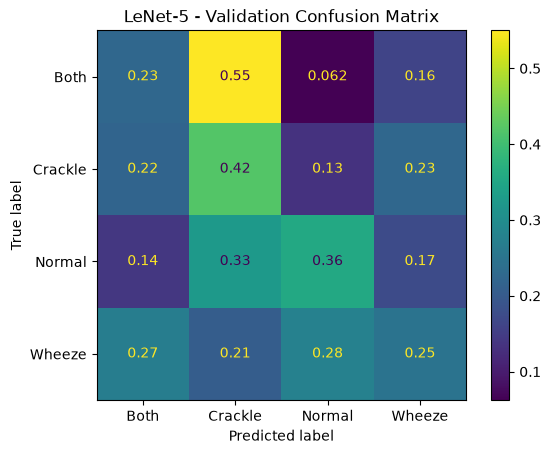

In [26]:
ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "LeNet-5 - Validation Confusion Matrix"
)

plt.show()

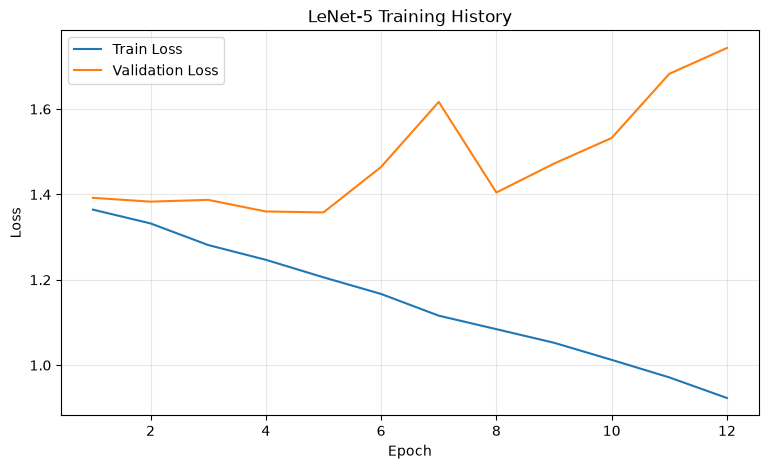

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    lenet_history["epoch"],
    lenet_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    lenet_history["epoch"],
    lenet_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet-5 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

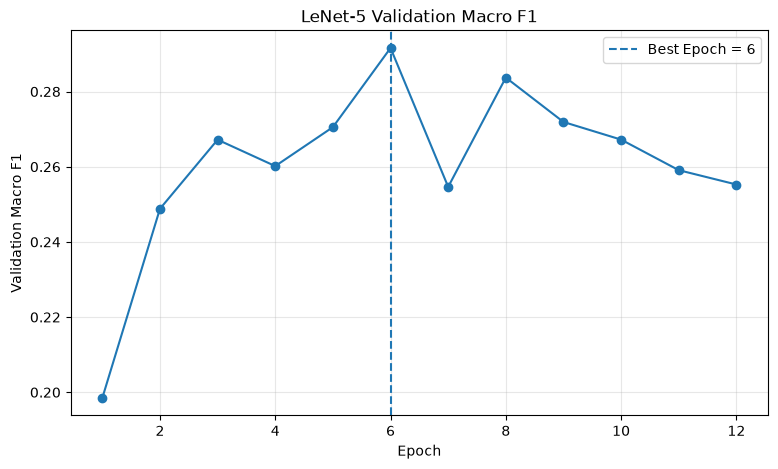

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    lenet_history["epoch"],
    lenet_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("LeNet-5 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [29]:
from torchvision import models
import torch.nn as nn

alexnet_model = models.alexnet(
    weights=models.AlexNet_Weights.IMAGENET1K_V1
)

# 마지막 분류층을 4-class로 교체
alexnet_model.classifier[6] = nn.Linear(
    alexnet_model.classifier[6].in_features,
    4
)

alexnet_model = alexnet_model.to(device)

print(alexnet_model.classifier)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to C:\Users\asia/.cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth
100%|██████████| 233M/233M [00:02<00:00, 111MB/s]  


Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=4096, out_features=4096, bias=True)
  (5): ReLU(inplace=True)
  (6): Linear(in_features=4096, out_features=4, bias=True)
)


In [30]:
x_alex = prepare_pretrained_input(
    batch_mel
).to(device)

with torch.no_grad():
    alex_logits = alexnet_model(x_alex)

print("Input shape :", x_alex.shape)
print("Output shape:", alex_logits.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 4])


In [31]:
alexnet_optimizer = torch.optim.Adam(
    alexnet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [32]:
alexnet_model, alexnet_history = train_model(
    model=alexnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=alexnet_optimizer,
    max_epochs=30,
    patience=6
)

Epoch 01 | Train Loss 1.3151 | Val Loss 1.3173 | Val Acc 0.4242 | Bal Acc 0.2934 | Macro F1 0.2712
Epoch 02 | Train Loss 1.1252 | Val Loss 1.4003 | Val Acc 0.3690 | Bal Acc 0.3712 | Macro F1 0.3301
Epoch 03 | Train Loss 1.0361 | Val Loss 1.2636 | Val Acc 0.4417 | Bal Acc 0.3543 | Macro F1 0.3251
Epoch 04 | Train Loss 0.9490 | Val Loss 1.3147 | Val Acc 0.5092 | Bal Acc 0.3647 | Macro F1 0.3659
Epoch 05 | Train Loss 0.8905 | Val Loss 1.3624 | Val Acc 0.4628 | Bal Acc 0.3917 | Macro F1 0.3793
Epoch 06 | Train Loss 0.7921 | Val Loss 1.4244 | Val Acc 0.4592 | Bal Acc 0.3711 | Macro F1 0.3631
Epoch 07 | Train Loss 0.7427 | Val Loss 1.4666 | Val Acc 0.4706 | Bal Acc 0.4008 | Macro F1 0.3830
Epoch 08 | Train Loss 0.7229 | Val Loss 1.4947 | Val Acc 0.4864 | Bal Acc 0.3726 | Macro F1 0.3565
Epoch 09 | Train Loss 0.6420 | Val Loss 1.3219 | Val Acc 0.5662 | Bal Acc 0.4736 | Macro F1 0.4562
Epoch 10 | Train Loss 0.5855 | Val Loss 1.5295 | Val Acc 0.5408 | Bal Acc 0.4422 | Macro F1 0.4354
Epoch 11 |

In [33]:
alexnet_val_metrics = evaluate_model(
    alexnet_model,
    val_loader,
    prepare_pretrained_input
)

print("===== AlexNet Validation Result =====")

for key, value in alexnet_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== AlexNet Validation Result =====
loss                : 1.3219
accuracy            : 0.5662
balanced_accuracy   : 0.4736
macro_f1            : 0.4562


              precision    recall  f1-score   support

        Both      0.235     0.100     0.140        80
     Crackle      0.480     0.601     0.534       336
      Normal      0.719     0.604     0.657       584
      Wheeze      0.426     0.589     0.494       141

    accuracy                          0.566      1141
   macro avg      0.465     0.474     0.456      1141
weighted avg      0.578     0.566     0.564      1141



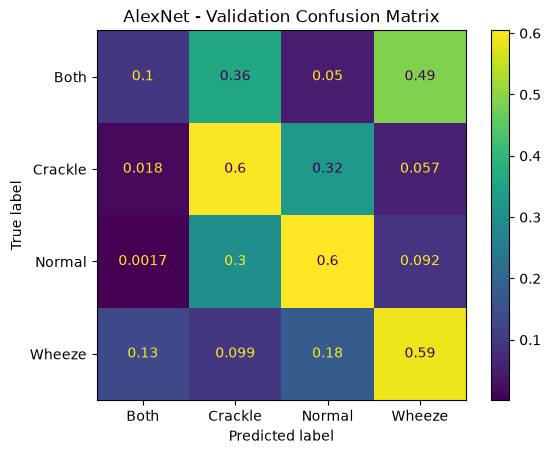

In [34]:
alexnet_model.eval()

alex_preds = []
alex_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = alexnet_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        alex_preds.extend(
            preds.cpu().numpy()
        )

        alex_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        alex_labels,
        alex_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    alex_labels,
    alex_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "AlexNet - Validation Confusion Matrix"
)

plt.show()

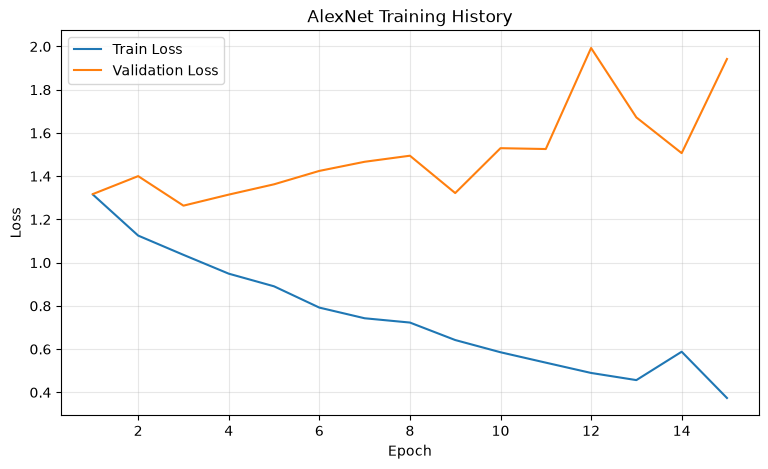

In [35]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_history["epoch"],
    alexnet_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    alexnet_history["epoch"],
    alexnet_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

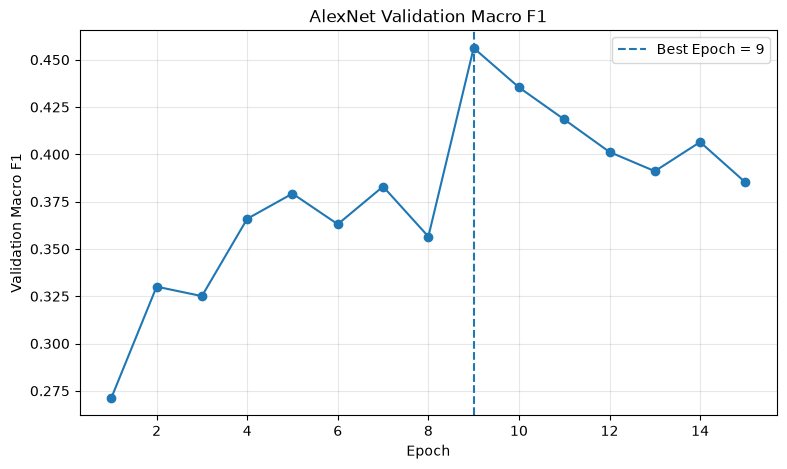

In [36]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_history["epoch"],
    alexnet_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=9,
    linestyle="--",
    label="Best Epoch = 9"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("AlexNet Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [37]:
from torchvision import models
import torch.nn as nn

vgg16_model = models.vgg16(
    weights=models.VGG16_Weights.IMAGENET1K_V1
)

# 마지막 분류층을 4-class로 변경
vgg16_model.classifier[6] = nn.Linear(
    vgg16_model.classifier[6].in_features,
    4
)

vgg16_model = vgg16_model.to(device)

print(vgg16_model.classifier)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\asia/.cache\torch\hub\checkpoints\vgg16-397923af.pth
100%|██████████| 528M/528M [00:05<00:00, 110MB/s]  


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=4, bias=True)
)


In [38]:
x_vgg = prepare_pretrained_input(
    batch_mel
).to(device)

with torch.no_grad():
    vgg_logits = vgg16_model(x_vgg)

print("Input shape :", x_vgg.shape)
print("Output shape:", vgg_logits.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 4])


In [39]:
vgg16_optimizer = torch.optim.Adam(
    vgg16_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [40]:
vgg16_model, vgg16_history = train_model(
    model=vgg16_model,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=vgg16_optimizer,
    max_epochs=30,
    patience=6
)

Epoch 01 | Train Loss 1.2106 | Val Loss 1.2538 | Val Acc 0.4785 | Bal Acc 0.3274 | Macro F1 0.2829
Epoch 02 | Train Loss 1.0288 | Val Loss 1.1396 | Val Acc 0.5381 | Bal Acc 0.3924 | Macro F1 0.4001
Epoch 03 | Train Loss 0.9119 | Val Loss 1.1353 | Val Acc 0.4566 | Bal Acc 0.4150 | Macro F1 0.3840
Epoch 04 | Train Loss 0.7966 | Val Loss 1.2742 | Val Acc 0.4294 | Bal Acc 0.3671 | Macro F1 0.3495
Epoch 05 | Train Loss 0.7050 | Val Loss 1.3618 | Val Acc 0.4715 | Bal Acc 0.3507 | Macro F1 0.3552
Epoch 06 | Train Loss 0.6085 | Val Loss 1.4909 | Val Acc 0.4741 | Bal Acc 0.3780 | Macro F1 0.3620
Epoch 07 | Train Loss 0.5387 | Val Loss 1.3013 | Val Acc 0.5592 | Bal Acc 0.4430 | Macro F1 0.4387
Epoch 08 | Train Loss 0.4674 | Val Loss 1.3514 | Val Acc 0.5364 | Bal Acc 0.4420 | Macro F1 0.4395
Epoch 09 | Train Loss 0.3694 | Val Loss 1.6908 | Val Acc 0.4961 | Bal Acc 0.4102 | Macro F1 0.4136
Epoch 10 | Train Loss 0.3421 | Val Loss 1.9002 | Val Acc 0.5443 | Bal Acc 0.4197 | Macro F1 0.4151
Epoch 11 |

In [41]:
vgg16_val_metrics = evaluate_model(
    vgg16_model,
    val_loader,
    prepare_pretrained_input
)

print("===== VGG16 Validation Result =====")

for key, value in vgg16_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== VGG16 Validation Result =====
loss                : 2.1621
accuracy            : 0.5933
balanced_accuracy   : 0.4501
macro_f1            : 0.4531


              precision    recall  f1-score   support

        Both      0.167     0.075     0.103        80
     Crackle      0.492     0.458     0.475       336
      Normal      0.678     0.764     0.718       584
      Wheeze      0.530     0.504     0.516       141

    accuracy                          0.593      1141
   macro avg      0.467     0.450     0.453      1141
weighted avg      0.569     0.593     0.578      1141



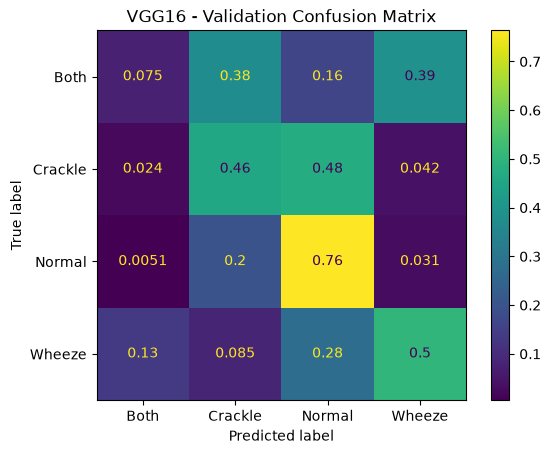

In [42]:
vgg16_model.eval()

vgg16_preds = []
vgg16_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = vgg16_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        vgg16_preds.extend(
            preds.cpu().numpy()
        )

        vgg16_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        vgg16_labels,
        vgg16_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    vgg16_labels,
    vgg16_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "VGG16 - Validation Confusion Matrix"
)

plt.show()

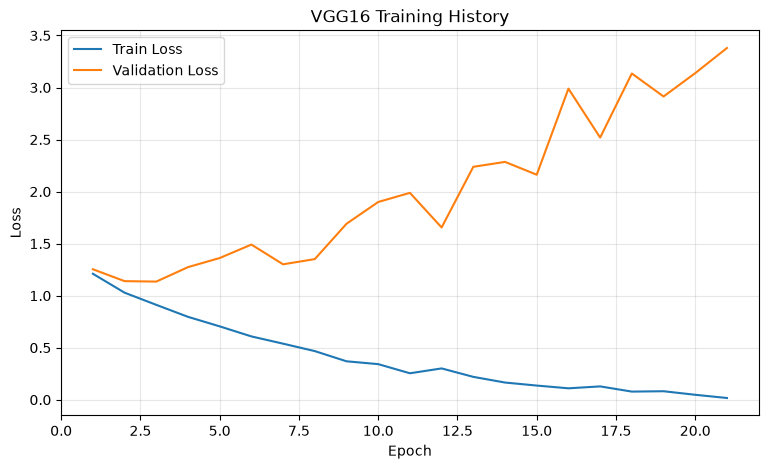

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_history["epoch"],
    vgg16_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    vgg16_history["epoch"],
    vgg16_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

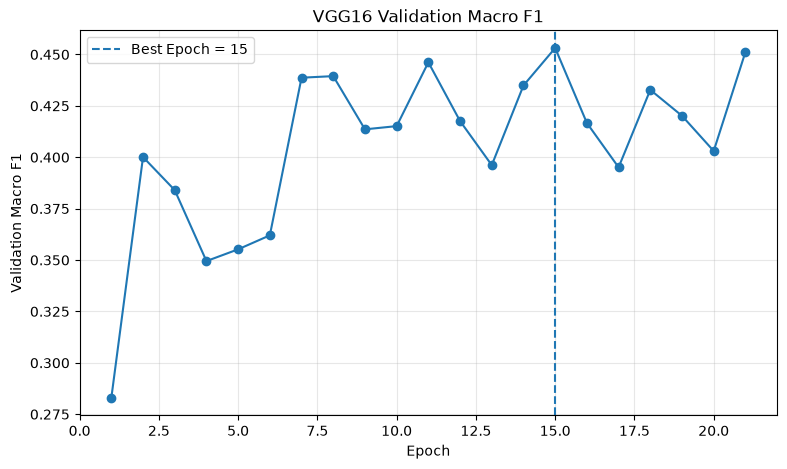

In [44]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_history["epoch"],
    vgg16_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=15,
    linestyle="--",
    label="Best Epoch = 15"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("VGG16 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [45]:
from torchvision import models
import torch.nn as nn

vgg19_model = models.vgg19(
    weights=models.VGG19_Weights.IMAGENET1K_V1
)

vgg19_model.classifier[6] = nn.Linear(
    vgg19_model.classifier[6].in_features,
    4
)

vgg19_model = vgg19_model.to(device)

print(vgg19_model.classifier)

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to C:\Users\asia/.cache\torch\hub\checkpoints\vgg19-dcbb9e9d.pth
100%|██████████| 548M/548M [00:05<00:00, 112MB/s]  


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=4, bias=True)
)


In [46]:
x_vgg19 = prepare_pretrained_input(
    batch_mel
).to(device)

with torch.no_grad():
    vgg19_logits = vgg19_model(x_vgg19)

print("Input shape :", x_vgg19.shape)
print("Output shape:", vgg19_logits.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 4])


In [47]:
vgg19_optimizer = torch.optim.Adam(
    vgg19_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [48]:
vgg19_model, vgg19_history = train_model(
    model=vgg19_model,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=vgg19_optimizer,
    max_epochs=30,
    patience=6
)

Epoch 01 | Train Loss 1.2501 | Val Loss 1.3392 | Val Acc 0.4890 | Bal Acc 0.3161 | Macro F1 0.3226
Epoch 02 | Train Loss 1.0804 | Val Loss 1.3119 | Val Acc 0.4531 | Bal Acc 0.2878 | Macro F1 0.2890
Epoch 03 | Train Loss 1.0376 | Val Loss 1.2579 | Val Acc 0.3804 | Bal Acc 0.3705 | Macro F1 0.3267
Epoch 04 | Train Loss 0.9340 | Val Loss 1.1569 | Val Acc 0.4259 | Bal Acc 0.4097 | Macro F1 0.3752
Epoch 05 | Train Loss 0.8516 | Val Loss 1.2703 | Val Acc 0.4023 | Bal Acc 0.4229 | Macro F1 0.3567
Epoch 06 | Train Loss 0.7769 | Val Loss 1.2493 | Val Acc 0.4461 | Bal Acc 0.3991 | Macro F1 0.3735
Epoch 07 | Train Loss 0.6888 | Val Loss 1.4871 | Val Acc 0.4470 | Bal Acc 0.4059 | Macro F1 0.3673
Epoch 08 | Train Loss 0.6100 | Val Loss 1.3321 | Val Acc 0.4961 | Bal Acc 0.4234 | Macro F1 0.4118
Epoch 09 | Train Loss 0.5529 | Val Loss 1.5062 | Val Acc 0.5153 | Bal Acc 0.4351 | Macro F1 0.4189
Epoch 10 | Train Loss 0.4972 | Val Loss 1.9080 | Val Acc 0.5372 | Bal Acc 0.4352 | Macro F1 0.4191
Epoch 11 |

In [50]:
vgg19_val_metrics = evaluate_model(
    vgg19_model,
    val_loader,
    prepare_pretrained_input
)

print("===== VGG19 Validation Result =====")

for key, value in vgg19_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== VGG19 Validation Result =====
loss                : 1.9080
accuracy            : 0.5372
balanced_accuracy   : 0.4352
macro_f1            : 0.4191


              precision    recall  f1-score   support

        Both      0.071     0.062     0.067        80
     Crackle      0.487     0.551     0.517       336
      Normal      0.697     0.596     0.643       584
      Wheeze      0.391     0.532     0.450       141

    accuracy                          0.537      1141
   macro avg      0.412     0.435     0.419      1141
weighted avg      0.554     0.537     0.541      1141



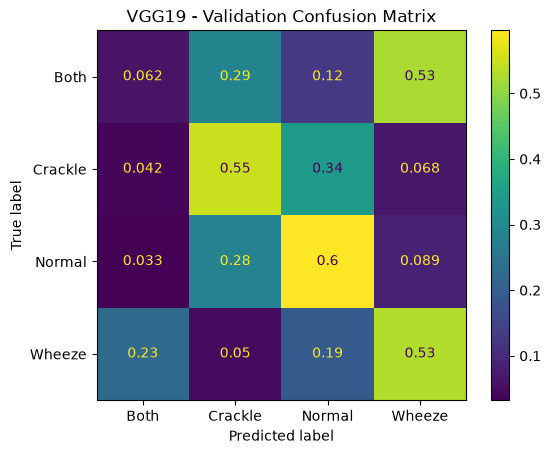

In [51]:
vgg19_model.eval()

vgg19_preds = []
vgg19_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = vgg19_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        vgg19_preds.extend(
            preds.cpu().numpy()
        )

        vgg19_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        vgg19_labels,
        vgg19_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    vgg19_labels,
    vgg19_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "VGG19 - Validation Confusion Matrix"
)

plt.show()

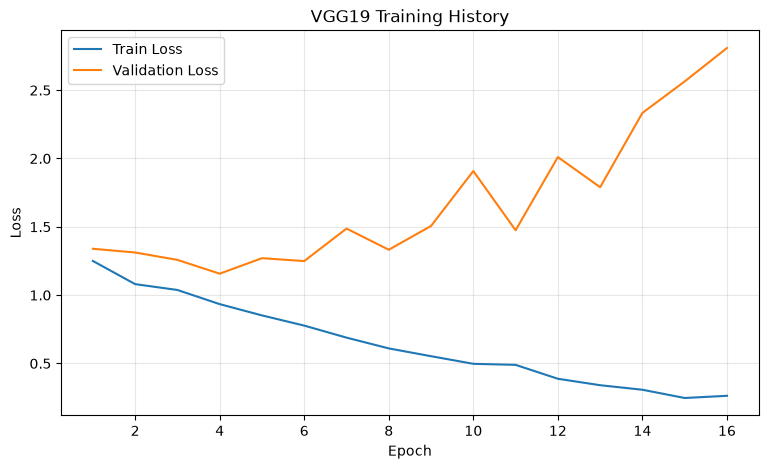

In [52]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg19_history["epoch"],
    vgg19_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    vgg19_history["epoch"],
    vgg19_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG19 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

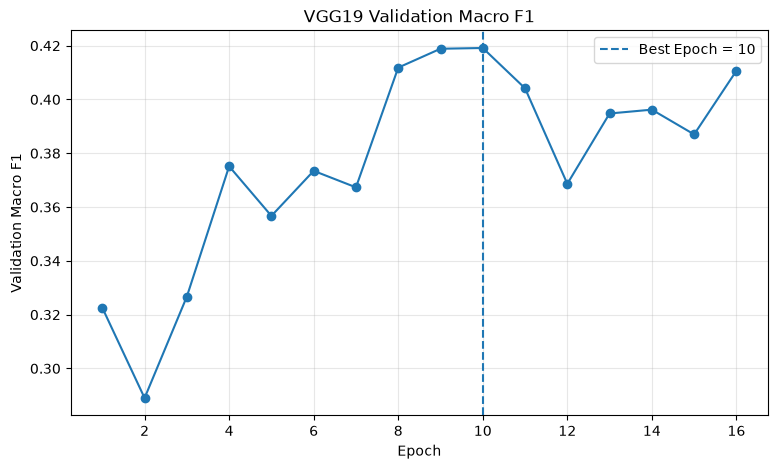

In [53]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg19_history["epoch"],
    vgg19_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=10,
    linestyle="--",
    label="Best Epoch = 10"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("VGG19 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [54]:
from torchvision import models
import torch.nn as nn

resnet50_model = models.resnet50(
    weights=models.ResNet50_Weights.IMAGENET1K_V2
)

resnet50_model.fc = nn.Linear(
    resnet50_model.fc.in_features,
    4
)

resnet50_model = resnet50_model.to(device)

print(resnet50_model.fc)

Linear(in_features=2048, out_features=4, bias=True)


In [55]:
x_resnet50 = prepare_pretrained_input(
    batch_mel
).to(device)

with torch.no_grad():
    resnet50_logits = resnet50_model(
        x_resnet50
    )

print("Input shape :", x_resnet50.shape)
print("Output shape:", resnet50_logits.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 4])


In [56]:
resnet50_optimizer = torch.optim.Adam(
    resnet50_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [57]:
resnet50_model, resnet50_history = train_model(
    model=resnet50_model,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet50_optimizer,
    max_epochs=30,
    patience=6
)

Epoch 01 | Train Loss 1.2389 | Val Loss 1.2698 | Val Acc 0.4706 | Bal Acc 0.3413 | Macro F1 0.3458
Epoch 02 | Train Loss 0.9023 | Val Loss 1.1939 | Val Acc 0.4864 | Bal Acc 0.3924 | Macro F1 0.3775
Epoch 03 | Train Loss 0.6050 | Val Loss 1.4741 | Val Acc 0.5294 | Bal Acc 0.3249 | Macro F1 0.3179
Epoch 04 | Train Loss 0.3917 | Val Loss 1.6896 | Val Acc 0.4689 | Bal Acc 0.3678 | Macro F1 0.3625
Epoch 05 | Train Loss 0.2053 | Val Loss 1.7058 | Val Acc 0.5118 | Bal Acc 0.3687 | Macro F1 0.3680
Epoch 06 | Train Loss 0.1181 | Val Loss 2.1683 | Val Acc 0.5557 | Bal Acc 0.3428 | Macro F1 0.3421
Epoch 07 | Train Loss 0.1151 | Val Loss 2.0152 | Val Acc 0.5451 | Bal Acc 0.4081 | Macro F1 0.4107
Epoch 08 | Train Loss 0.1203 | Val Loss 1.8872 | Val Acc 0.6030 | Bal Acc 0.4533 | Macro F1 0.4478
Epoch 09 | Train Loss 0.1209 | Val Loss 2.1815 | Val Acc 0.5960 | Bal Acc 0.4351 | Macro F1 0.4355
Epoch 10 | Train Loss 0.0497 | Val Loss 2.4206 | Val Acc 0.5670 | Bal Acc 0.3957 | Macro F1 0.3996
Epoch 11 |

In [58]:
resnet50_val_metrics = evaluate_model(
    resnet50_model,
    val_loader,
    prepare_pretrained_input
)

print("===== ResNet50 Validation Result =====")

for key, value in resnet50_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== ResNet50 Validation Result =====
loss                : 2.1883
accuracy            : 0.5793
balanced_accuracy   : 0.4491
macro_f1            : 0.4568


              precision    recall  f1-score   support

        Both      0.308     0.100     0.151        80
     Crackle      0.489     0.551     0.518       336
      Normal      0.659     0.692     0.675       584
      Wheeze      0.516     0.454     0.483       141

    accuracy                          0.579      1141
   macro avg      0.493     0.449     0.457      1141
weighted avg      0.567     0.579     0.568      1141



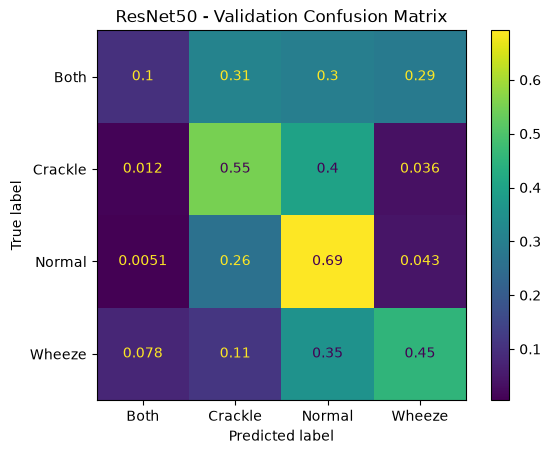

In [59]:
resnet50_model.eval()

resnet50_preds = []
resnet50_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = resnet50_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        resnet50_preds.extend(
            preds.cpu().numpy()
        )

        resnet50_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        resnet50_labels,
        resnet50_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    resnet50_labels,
    resnet50_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "ResNet50 - Validation Confusion Matrix"
)

plt.show()

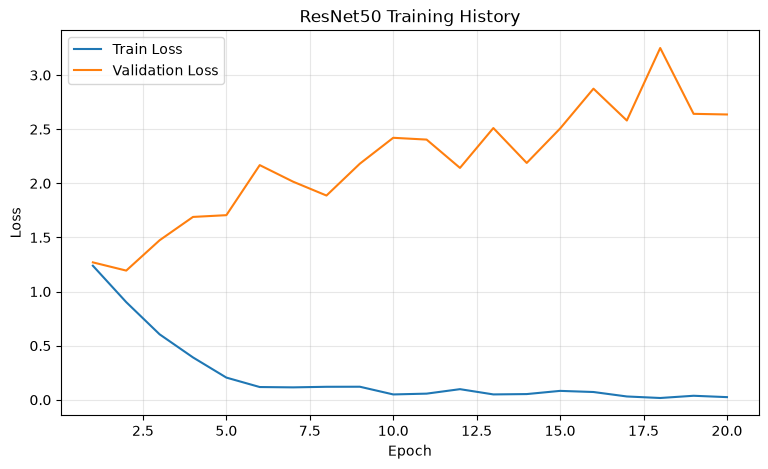

In [60]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_history["epoch"],
    resnet50_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    resnet50_history["epoch"],
    resnet50_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

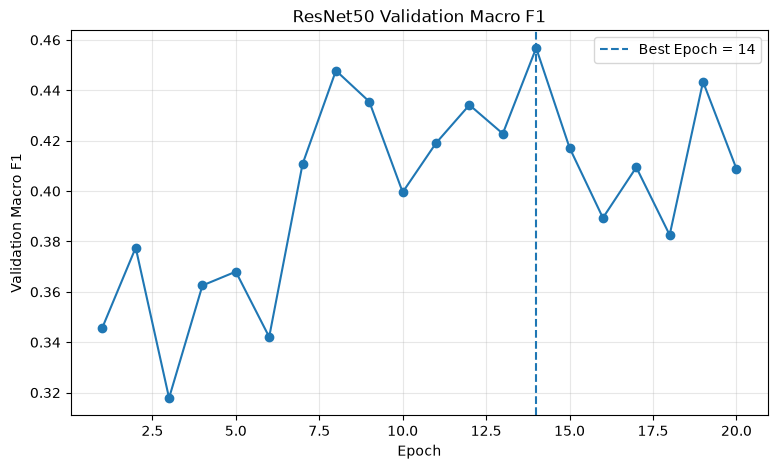

In [61]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_history["epoch"],
    resnet50_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=14,
    linestyle="--",
    label="Best Epoch = 14"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("ResNet50 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [62]:
from torchvision import models
import torch.nn as nn

resnet152_model = models.resnet152(
    weights=models.ResNet152_Weights.IMAGENET1K_V2
)

resnet152_model.fc = nn.Linear(
    resnet152_model.fc.in_features,
    4
)

resnet152_model = resnet152_model.to(device)

print(resnet152_model.fc)

Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to C:\Users\asia/.cache\torch\hub\checkpoints\resnet152-f82ba261.pth
100%|██████████| 230M/230M [00:02<00:00, 115MB/s]  


Linear(in_features=2048, out_features=4, bias=True)


In [63]:
x_resnet152 = prepare_pretrained_input(
    batch_mel
).to(device)

with torch.no_grad():
    resnet152_logits = resnet152_model(
        x_resnet152
    )

print("Input shape :", x_resnet152.shape)
print("Output shape:", resnet152_logits.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 4])


In [64]:
resnet152_optimizer = torch.optim.Adam(
    resnet152_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [65]:
resnet152_model, resnet152_history = train_model(
    model=resnet152_model,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet152_optimizer,
    max_epochs=30,
    patience=6
)

Epoch 01 | Train Loss 1.2102 | Val Loss 1.2314 | Val Acc 0.4882 | Bal Acc 0.3746 | Macro F1 0.3794
Epoch 02 | Train Loss 0.8334 | Val Loss 1.2914 | Val Acc 0.4435 | Bal Acc 0.3933 | Macro F1 0.3609
Epoch 03 | Train Loss 0.5003 | Val Loss 1.4996 | Val Acc 0.5223 | Bal Acc 0.3948 | Macro F1 0.4019
Epoch 04 | Train Loss 0.2826 | Val Loss 2.0236 | Val Acc 0.5399 | Bal Acc 0.3712 | Macro F1 0.3728
Epoch 05 | Train Loss 0.1476 | Val Loss 2.2556 | Val Acc 0.5101 | Bal Acc 0.3727 | Macro F1 0.3703
Epoch 06 | Train Loss 0.1088 | Val Loss 2.0750 | Val Acc 0.5329 | Bal Acc 0.3753 | Macro F1 0.3785
Epoch 07 | Train Loss 0.1144 | Val Loss 2.3036 | Val Acc 0.5153 | Bal Acc 0.3963 | Macro F1 0.4018
Epoch 08 | Train Loss 0.0801 | Val Loss 2.2285 | Val Acc 0.5048 | Bal Acc 0.4290 | Macro F1 0.4145
Epoch 09 | Train Loss 0.0858 | Val Loss 2.1687 | Val Acc 0.5232 | Bal Acc 0.4215 | Macro F1 0.4237
Epoch 10 | Train Loss 0.0417 | Val Loss 2.5221 | Val Acc 0.5250 | Bal Acc 0.3863 | Macro F1 0.3923
Epoch 11 |

In [66]:
resnet152_val_metrics = evaluate_model(
    resnet152_model,
    val_loader,
    prepare_pretrained_input
)

print("===== ResNet152 Validation Result =====")

for key, value in resnet152_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== ResNet152 Validation Result =====
loss                : 2.7337
accuracy            : 0.5583
balanced_accuracy   : 0.4255
macro_f1            : 0.4372


              precision    recall  f1-score   support

        Both      0.231     0.150     0.182        80
     Crackle      0.485     0.476     0.480       336
      Normal      0.634     0.707     0.669       584
      Wheeze      0.481     0.369     0.418       141

    accuracy                          0.558      1141
   macro avg      0.458     0.426     0.437      1141
weighted avg      0.543     0.558     0.548      1141



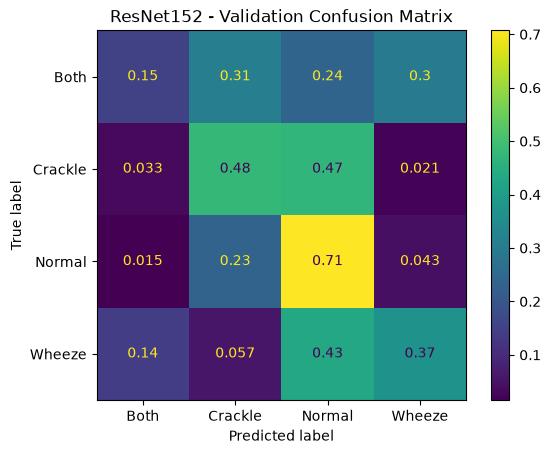

In [67]:
resnet152_model.eval()

resnet152_preds = []
resnet152_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = resnet152_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        resnet152_preds.extend(
            preds.cpu().numpy()
        )

        resnet152_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        resnet152_labels,
        resnet152_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    resnet152_labels,
    resnet152_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "ResNet152 - Validation Confusion Matrix"
)

plt.show()

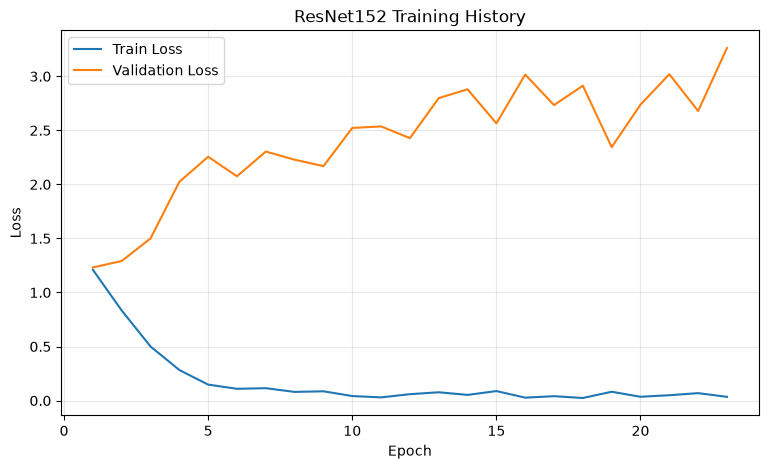

In [68]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet152_history["epoch"],
    resnet152_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    resnet152_history["epoch"],
    resnet152_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet152 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

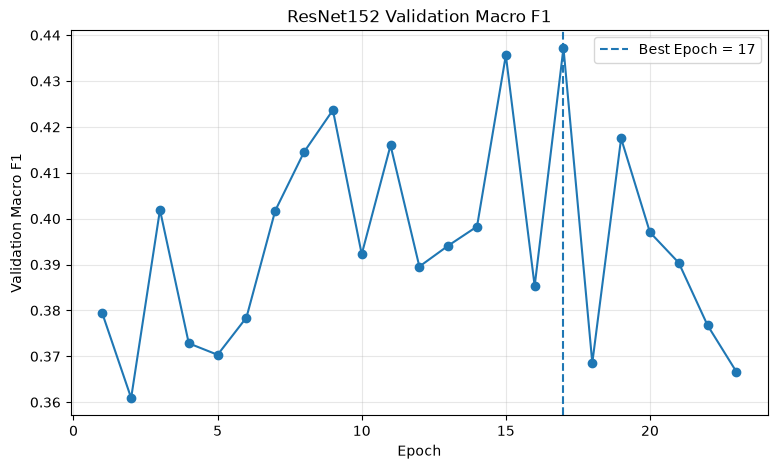

In [69]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet152_history["epoch"],
    resnet152_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=17,
    linestyle="--",
    label="Best Epoch = 17"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("ResNet152 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [70]:
screening_results = pd.DataFrame([
    {
        "Model": "LeNet-5",
        "Best_Epoch": 6,
        "Accuracy": 0.3523,
        "Balanced_Accuracy": 0.3123,
        "Macro_F1": 0.2916
    },
    {
        "Model": "AlexNet",
        "Best_Epoch": 9,
        "Accuracy": 0.5662,
        "Balanced_Accuracy": 0.4736,
        "Macro_F1": 0.4562
    },
    {
        "Model": "VGG16",
        "Best_Epoch": 15,
        "Accuracy": 0.5933,
        "Balanced_Accuracy": 0.4501,
        "Macro_F1": 0.4531
    },
    {
        "Model": "VGG19",
        "Best_Epoch": 10,
        "Accuracy": 0.5372,
        "Balanced_Accuracy": 0.4352,
        "Macro_F1": 0.4191
    },
    {
        "Model": "ResNet50",
        "Best_Epoch": 14,
        "Accuracy": 0.5793,
        "Balanced_Accuracy": 0.4491,
        "Macro_F1": 0.4568
    },
    {
        "Model": "ResNet152",
        "Best_Epoch": 17,
        "Accuracy": 0.5583,
        "Balanced_Accuracy": 0.4255,
        "Macro_F1": 0.4372
    }
])

screening_results = screening_results.sort_values(
    "Macro_F1",
    ascending=False
)

screening_results

,Model,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1
4,ResNet50,14,0.5793,0.4491,0.4568
1,AlexNet,9,0.5662,0.4736,0.4562
2,VGG16,15,0.5933,0.4501,0.4531
5,ResNet152,17,0.5583,0.4255,0.4372
3,VGG19,10,0.5372,0.4352,0.4191
0,LeNet-5,6,0.3523,0.3123,0.2916


In [71]:
screening_results = pd.DataFrame([
    {
        "Model": "LeNet-5",
        "Best_Epoch": 6,
        "Accuracy": 0.3523,
        "Balanced_Accuracy": 0.3123,
        "Macro_F1": 0.2916,
        "Both_Recall": 0.225,
        "Crackle_Recall": 0.420,
        "Normal_Recall": 0.356,
        "Wheeze_Recall": 0.248
    },
    {
        "Model": "AlexNet",
        "Best_Epoch": 9,
        "Accuracy": 0.5662,
        "Balanced_Accuracy": 0.4736,
        "Macro_F1": 0.4562,
        "Both_Recall": 0.100,
        "Crackle_Recall": 0.601,
        "Normal_Recall": 0.604,
        "Wheeze_Recall": 0.589
    },
    {
        "Model": "VGG16",
        "Best_Epoch": 15,
        "Accuracy": 0.5933,
        "Balanced_Accuracy": 0.4501,
        "Macro_F1": 0.4531,
        "Both_Recall": 0.075,
        "Crackle_Recall": 0.458,
        "Normal_Recall": 0.764,
        "Wheeze_Recall": 0.504
    },
    {
        "Model": "VGG19",
        "Best_Epoch": 10,
        "Accuracy": 0.5372,
        "Balanced_Accuracy": 0.4352,
        "Macro_F1": 0.4191,
        "Both_Recall": 0.062,
        "Crackle_Recall": 0.551,
        "Normal_Recall": 0.596,
        "Wheeze_Recall": 0.532
    },
    {
        "Model": "ResNet50",
        "Best_Epoch": 14,
        "Accuracy": 0.5793,
        "Balanced_Accuracy": 0.4491,
        "Macro_F1": 0.4568,
        "Both_Recall": 0.100,
        "Crackle_Recall": 0.551,
        "Normal_Recall": 0.692,
        "Wheeze_Recall": 0.454
    },
    {
        "Model": "ResNet152",
        "Best_Epoch": 17,
        "Accuracy": 0.5583,
        "Balanced_Accuracy": 0.4255,
        "Macro_F1": 0.4372,
        "Both_Recall": 0.150,
        "Crackle_Recall": 0.476,
        "Normal_Recall": 0.707,
        "Wheeze_Recall": 0.369
    }
])

screening_results = screening_results.sort_values(
    "Macro_F1",
    ascending=False
).reset_index(drop=True)

screening_results

,Model,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,ResNet50,14,0.5793,0.4491,0.4568,0.100,0.551,0.692,0.454
1,AlexNet,9,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589
2,VGG16,15,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504
3,ResNet152,17,0.5583,0.4255,0.4372,0.150,0.476,0.707,0.369
4,VGG19,10,0.5372,0.4352,0.4191,0.062,0.551,0.596,0.532
5,LeNet-5,6,0.3523,0.3123,0.2916,0.225,0.420,0.356,0.248


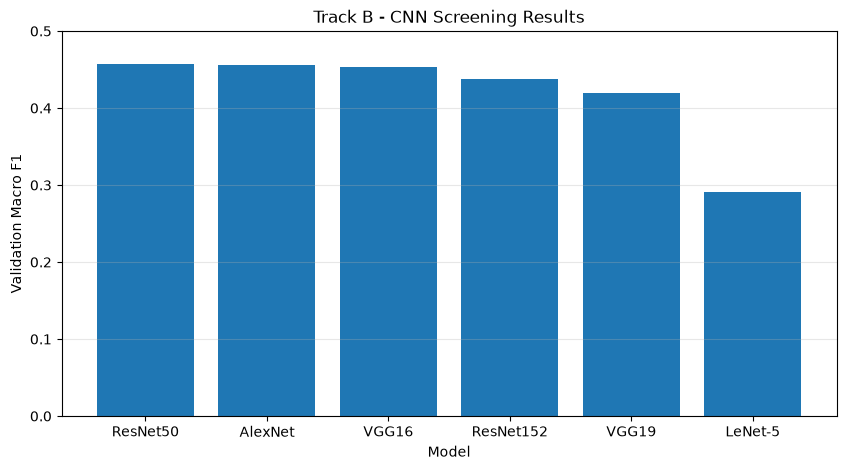

In [72]:
plt.figure(figsize=(10, 5))

plt.bar(
    screening_results["Model"],
    screening_results["Macro_F1"]
)

plt.ylabel("Validation Macro F1")
plt.xlabel("Model")
plt.title("Track B - CNN Screening Results")

plt.ylim(0, 0.5)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [73]:
import torchaudio

freq_masking = torchaudio.transforms.FrequencyMasking(
    freq_mask_param=8,
    iid_masks=True
)

time_masking = torchaudio.transforms.TimeMasking(
    time_mask_param=10,
    iid_masks=True
)

def apply_specaugment(x):
    """
    x shape:
        [B, 1, 128, 126]

    Train에서만 사용
    """

    x = freq_masking(x)
    x = time_masking(x)

    return x

In [74]:
augmented_batch = apply_specaugment(
    batch_mel.clone()
)

print(
    "Original shape :",
    batch_mel.shape
)

print(
    "Augmented shape:",
    augmented_batch.shape
)

print(
    "Original range :",
    batch_mel.min().item(),
    batch_mel.max().item()
)

print(
    "Augmented range:",
    augmented_batch.min().item(),
    augmented_batch.max().item()
)

Original shape : torch.Size([32, 1, 128, 126])
Augmented shape: torch.Size([32, 1, 128, 126])
Original range : 0.0 1.0
Augmented range: 0.0 1.0


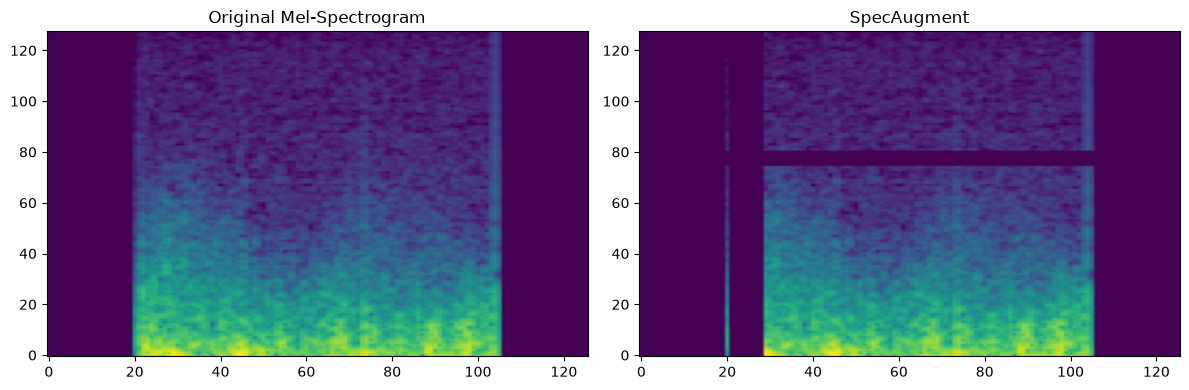

In [75]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].imshow(
    batch_mel[0, 0].numpy(),
    origin="lower",
    aspect="auto"
)

axes[0].set_title(
    "Original Mel-Spectrogram"
)

axes[1].imshow(
    augmented_batch[0, 0].numpy(),
    origin="lower",
    aspect="auto"
)

axes[1].set_title(
    "SpecAugment"
)

plt.tight_layout()
plt.show()

In [76]:
import copy

def train_model_v2(
    model,
    train_loader,
    val_loader,
    input_prepare_fn,
    optimizer,
    scheduler,
    augmentation_fn=None,
    max_epochs=30,
    patience=6
):

    best_state = None
    best_macro_f1 = -1.0
    best_epoch = 0

    patience_counter = 0

    history = []

    for epoch in range(
        1,
        max_epochs + 1
    ):

        # =========================
        # TRAIN
        # =========================

        model.train()

        running_loss = 0.0

        for x, y in train_loader:

            # Train에만 augmentation
            if augmentation_fn is not None:

                x = augmentation_fn(x)

            x = input_prepare_fn(x).to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            logits = model(x)

            loss = criterion(
                logits,
                y
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * x.size(0)
            )

        train_loss = (
            running_loss
            / len(train_loader.dataset)
        )

        # =========================
        # VALIDATION
        # =========================

        val_metrics = evaluate_model(
            model,
            val_loader,
            input_prepare_fn
        )

        current_lr = (
            optimizer
            .param_groups[0]["lr"]
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss":
                val_metrics["loss"],
            "val_accuracy":
                val_metrics["accuracy"],
            "val_balanced_accuracy":
                val_metrics[
                    "balanced_accuracy"
                ],
            "val_macro_f1":
                val_metrics["macro_f1"],
            "learning_rate":
                current_lr
        })

        print(
            f"Epoch {epoch:02d} | "
            f"LR {current_lr:.2e} | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_metrics['loss']:.4f} | "
            f"Val Acc {val_metrics['accuracy']:.4f} | "
            f"Bal Acc {val_metrics['balanced_accuracy']:.4f} | "
            f"Macro F1 {val_metrics['macro_f1']:.4f}"
        )

        # =========================
        # LR SCHEDULER
        # =========================

        scheduler.step(
            val_metrics["macro_f1"]
        )

        # =========================
        # BEST MODEL
        # =========================

        if (
            val_metrics["macro_f1"]
            > best_macro_f1
        ):

            best_macro_f1 = (
                val_metrics["macro_f1"]
            )

            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        # =========================
        # EARLY STOPPING
        # =========================

        if patience_counter >= patience:

            print(
                "\nEarly stopping:",
                f"no Macro F1 improvement "
                f"for {patience} epochs."
            )

            break

    model.load_state_dict(
        best_state
    )

    print(
        "\nBest epoch:",
        best_epoch
    )

    print(
        "Best Validation Macro F1:",
        round(best_macro_f1, 4)
    )

    history_df = pd.DataFrame(
        history
    )

    return model, history_df

In [77]:
alexnet_v2 = models.alexnet(
    weights=models.AlexNet_Weights.IMAGENET1K_V1
)

alexnet_v2.classifier[6] = nn.Linear(
    alexnet_v2.classifier[6].in_features,
    4
)

alexnet_v2 = alexnet_v2.to(device)

In [78]:
alexnet_v2_optimizer = torch.optim.Adam(
    alexnet_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [79]:
alexnet_v2_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        alexnet_v2_optimizer,
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
)

In [80]:
alexnet_v2, alexnet_v2_history = train_model_v2(
    model=alexnet_v2,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=alexnet_v2_optimizer,
    scheduler=alexnet_v2_scheduler,
    augmentation_fn=apply_specaugment,
    max_epochs=30,
    patience=6
)

Epoch 01 | LR 1.00e-04 | Train Loss 1.3576 | Val Loss 1.4488 | Val Acc 0.2699 | Bal Acc 0.2814 | Macro F1 0.2227
Epoch 02 | LR 1.00e-04 | Train Loss 1.2535 | Val Loss 1.3223 | Val Acc 0.3550 | Bal Acc 0.3227 | Macro F1 0.2545
Epoch 03 | LR 1.00e-04 | Train Loss 1.1533 | Val Loss 1.1928 | Val Acc 0.4733 | Bal Acc 0.3895 | Macro F1 0.3590
Epoch 04 | LR 1.00e-04 | Train Loss 1.0779 | Val Loss 1.2344 | Val Acc 0.4084 | Bal Acc 0.3376 | Macro F1 0.2981
Epoch 05 | LR 1.00e-04 | Train Loss 1.0224 | Val Loss 1.3180 | Val Acc 0.4601 | Bal Acc 0.3601 | Macro F1 0.3368
Epoch 06 | LR 1.00e-04 | Train Loss 0.9876 | Val Loss 1.3470 | Val Acc 0.4373 | Bal Acc 0.3581 | Macro F1 0.3336
Epoch 07 | LR 5.00e-05 | Train Loss 0.8876 | Val Loss 1.3054 | Val Acc 0.4785 | Bal Acc 0.3767 | Macro F1 0.3696
Epoch 08 | LR 5.00e-05 | Train Loss 0.8697 | Val Loss 1.2214 | Val Acc 0.4741 | Bal Acc 0.4021 | Macro F1 0.3864
Epoch 09 | LR 5.00e-05 | Train Loss 0.8341 | Val Loss 1.3075 | Val Acc 0.4619 | Bal Acc 0.4142 |

In [81]:
alexnet_v2_val_metrics = evaluate_model(
    alexnet_v2,
    val_loader,
    prepare_pretrained_input
)

print("===== AlexNet v2 Validation Result =====")

for key, value in alexnet_v2_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== AlexNet v2 Validation Result =====
loss                : 1.4796
accuracy            : 0.5355
balanced_accuracy   : 0.4478
macro_f1            : 0.4412


              precision    recall  f1-score   support

        Both      0.214     0.275     0.240        80
     Crackle      0.453     0.613     0.521       336
      Normal      0.714     0.577     0.638       584
      Wheeze      0.414     0.326     0.365       141

    accuracy                          0.535      1141
   macro avg      0.449     0.448     0.441      1141
weighted avg      0.565     0.535     0.542      1141



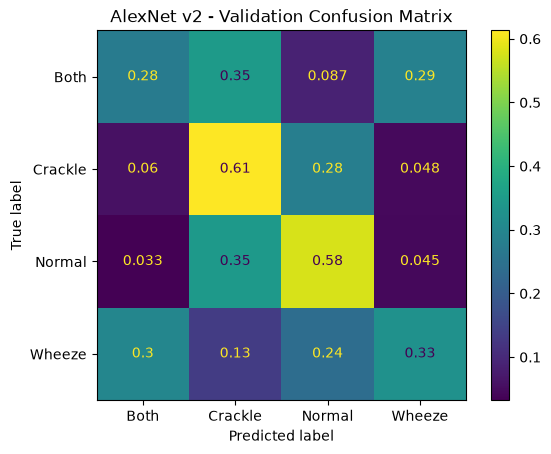

In [82]:
alexnet_v2.eval()

alexnet_v2_preds = []
alexnet_v2_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = alexnet_v2(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        alexnet_v2_preds.extend(
            preds.cpu().numpy()
        )

        alexnet_v2_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        alexnet_v2_labels,
        alexnet_v2_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    alexnet_v2_labels,
    alexnet_v2_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "AlexNet v2 - Validation Confusion Matrix"
)

plt.show()

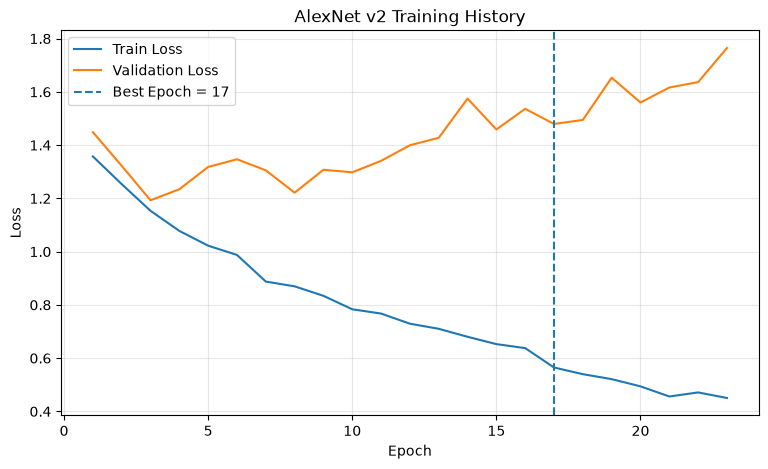

In [83]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2_history["epoch"],
    alexnet_v2_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    alexnet_v2_history["epoch"],
    alexnet_v2_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=17,
    linestyle="--",
    label="Best Epoch = 17"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet v2 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

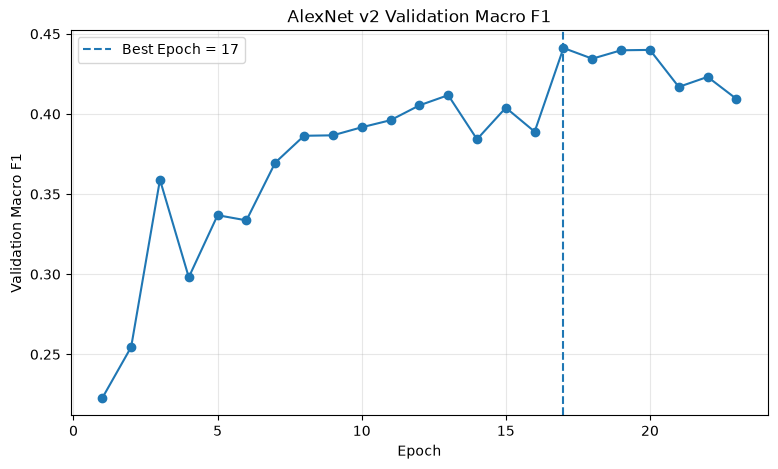

In [84]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2_history["epoch"],
    alexnet_v2_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=17,
    linestyle="--",
    label="Best Epoch = 17"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("AlexNet v2 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

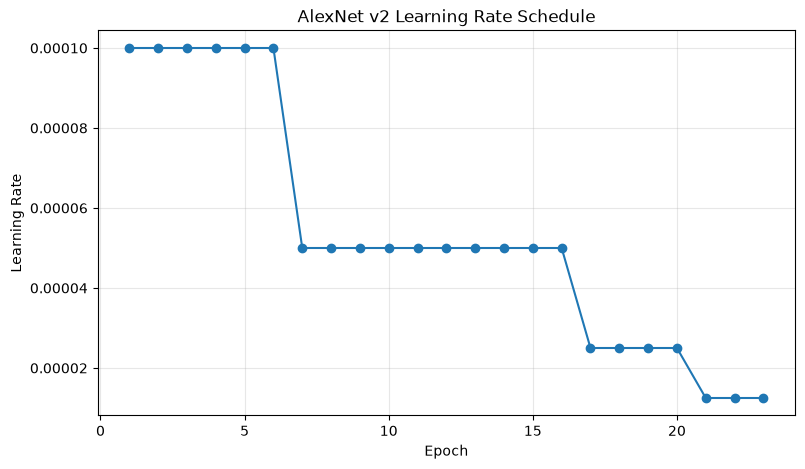

In [85]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2_history["epoch"],
    alexnet_v2_history["learning_rate"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("AlexNet v2 Learning Rate Schedule")
plt.grid(alpha=0.3)

plt.show()

In [86]:
alexnet_v2b = models.alexnet(
    weights=models.AlexNet_Weights.IMAGENET1K_V1
)

alexnet_v2b.classifier[6] = nn.Linear(
    alexnet_v2b.classifier[6].in_features,
    4
)

alexnet_v2b = alexnet_v2b.to(device)

In [87]:
alexnet_v2b_optimizer = torch.optim.Adam(
    alexnet_v2b.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [88]:
alexnet_v2b_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        alexnet_v2b_optimizer,
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
)

In [89]:
alexnet_v2b, alexnet_v2b_history = train_model_v2(
    model=alexnet_v2b,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=alexnet_v2b_optimizer,
    scheduler=alexnet_v2b_scheduler,
    augmentation_fn=None,
    max_epochs=30,
    patience=6
)

Epoch 01 | LR 1.00e-04 | Train Loss 1.3209 | Val Loss 1.3234 | Val Acc 0.4268 | Bal Acc 0.3081 | Macro F1 0.2864
Epoch 02 | LR 1.00e-04 | Train Loss 1.1583 | Val Loss 1.2971 | Val Acc 0.4058 | Bal Acc 0.3451 | Macro F1 0.3076
Epoch 03 | LR 1.00e-04 | Train Loss 0.9969 | Val Loss 1.2048 | Val Acc 0.4636 | Bal Acc 0.3809 | Macro F1 0.3663
Epoch 04 | LR 1.00e-04 | Train Loss 0.9194 | Val Loss 1.3615 | Val Acc 0.3970 | Bal Acc 0.3845 | Macro F1 0.3447
Epoch 05 | LR 1.00e-04 | Train Loss 0.8214 | Val Loss 1.2871 | Val Acc 0.5206 | Bal Acc 0.4272 | Macro F1 0.4146
Epoch 06 | LR 1.00e-04 | Train Loss 0.7670 | Val Loss 1.1921 | Val Acc 0.4917 | Bal Acc 0.4296 | Macro F1 0.4008
Epoch 07 | LR 1.00e-04 | Train Loss 0.6856 | Val Loss 1.3830 | Val Acc 0.4785 | Bal Acc 0.3796 | Macro F1 0.3714
Epoch 08 | LR 1.00e-04 | Train Loss 0.6219 | Val Loss 1.4343 | Val Acc 0.4777 | Bal Acc 0.4030 | Macro F1 0.3844
Epoch 09 | LR 5.00e-05 | Train Loss 0.4855 | Val Loss 1.7511 | Val Acc 0.5425 | Bal Acc 0.4148 |

In [90]:
alexnet_v2c = models.alexnet(
    weights=models.AlexNet_Weights.IMAGENET1K_V1
)

alexnet_v2c.classifier[6] = nn.Linear(
    alexnet_v2c.classifier[6].in_features,
    4
)

alexnet_v2c = alexnet_v2c.to(device)

In [91]:
alexnet_v2c_optimizer = torch.optim.Adam(
    alexnet_v2c.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [92]:
import copy

def train_model_specaug_only(
    model,
    train_loader,
    val_loader,
    input_prepare_fn,
    optimizer,
    augmentation_fn,
    max_epochs=30,
    patience=6
):

    best_state = None
    best_macro_f1 = -1.0
    best_epoch = 0
    patience_counter = 0

    history = []

    for epoch in range(1, max_epochs + 1):

        model.train()
        running_loss = 0.0

        for x, y in train_loader:

            x = augmentation_fn(x)

            x = input_prepare_fn(x).to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            logits = model(x)

            loss = criterion(
                logits,
                y
            )

            loss.backward()
            optimizer.step()

            running_loss += (
                loss.item() * x.size(0)
            )

        train_loss = (
            running_loss
            / len(train_loader.dataset)
        )

        val_metrics = evaluate_model(
            model,
            val_loader,
            input_prepare_fn
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],
            "val_macro_f1":
                val_metrics["macro_f1"]
        })

        print(
            f"Epoch {epoch:02d} | "
            f"LR 1.00e-04 | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_metrics['loss']:.4f} | "
            f"Val Acc {val_metrics['accuracy']:.4f} | "
            f"Bal Acc {val_metrics['balanced_accuracy']:.4f} | "
            f"Macro F1 {val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_macro_f1:

            best_macro_f1 = val_metrics["macro_f1"]
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= patience:

            print(
                "\nEarly stopping:",
                f"no Macro F1 improvement for {patience} epochs."
            )
            break

    model.load_state_dict(best_state)

    print("\nBest epoch:", best_epoch)
    print(
        "Best Validation Macro F1:",
        round(best_macro_f1, 4)
    )

    history_df = pd.DataFrame(history)

    return model, history_df

In [93]:
alexnet_v2c, alexnet_v2c_history = train_model_specaug_only(
    model=alexnet_v2c,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=alexnet_v2c_optimizer,
    augmentation_fn=apply_specaugment,
    max_epochs=30,
    patience=6
)

Epoch 01 | LR 1.00e-04 | Train Loss 1.3461 | Val Loss 1.3393 | Val Acc 0.3786 | Bal Acc 0.3045 | Macro F1 0.2735
Epoch 02 | LR 1.00e-04 | Train Loss 1.2405 | Val Loss 1.5297 | Val Acc 0.2279 | Bal Acc 0.2404 | Macro F1 0.2034
Epoch 03 | LR 1.00e-04 | Train Loss 1.1765 | Val Loss 1.2880 | Val Acc 0.4487 | Bal Acc 0.3423 | Macro F1 0.3244
Epoch 04 | LR 1.00e-04 | Train Loss 1.1156 | Val Loss 1.3234 | Val Acc 0.4181 | Bal Acc 0.3097 | Macro F1 0.3065
Epoch 05 | LR 1.00e-04 | Train Loss 1.0472 | Val Loss 1.2730 | Val Acc 0.4487 | Bal Acc 0.3104 | Macro F1 0.3192
Epoch 06 | LR 1.00e-04 | Train Loss 1.0179 | Val Loss 1.3198 | Val Acc 0.4233 | Bal Acc 0.3792 | Macro F1 0.3528
Epoch 07 | LR 1.00e-04 | Train Loss 0.9759 | Val Loss 1.5309 | Val Acc 0.4671 | Bal Acc 0.3646 | Macro F1 0.3452
Epoch 08 | LR 1.00e-04 | Train Loss 0.9374 | Val Loss 1.2891 | Val Acc 0.4654 | Bal Acc 0.4116 | Macro F1 0.3860
Epoch 09 | LR 1.00e-04 | Train Loss 0.9039 | Val Loss 1.4034 | Val Acc 0.4522 | Bal Acc 0.3546 |

In [94]:
alexnet_v2b_val_metrics = evaluate_model(
    alexnet_v2b,
    val_loader,
    prepare_pretrained_input
)

print("===== AlexNet v2B Validation Result =====")

for key, value in alexnet_v2b_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== AlexNet v2B Validation Result =====
loss                : 1.5766
accuracy            : 0.5434
balanced_accuracy   : 0.4204
macro_f1            : 0.4150


              precision    recall  f1-score   support

        Both      0.224     0.275     0.247        80
     Crackle      0.446     0.622     0.519       336
      Normal      0.699     0.628     0.662       584
      Wheeze      0.449     0.156     0.232       141

    accuracy                          0.543      1141
   macro avg      0.455     0.420     0.415      1141
weighted avg      0.560     0.543     0.538      1141



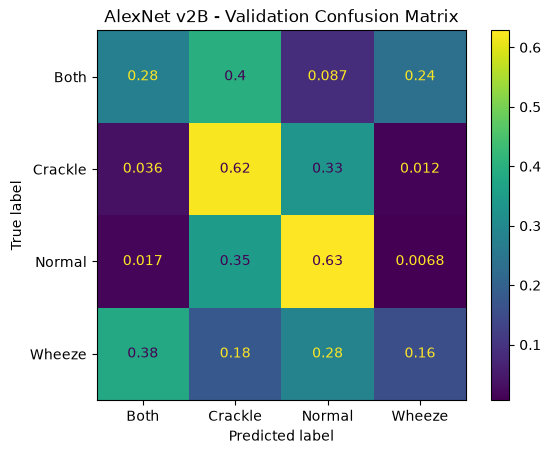

In [95]:
alexnet_v2b.eval()

alexnet_v2b_preds = []
alexnet_v2b_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = alexnet_v2b(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        alexnet_v2b_preds.extend(
            preds.cpu().numpy()
        )

        alexnet_v2b_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        alexnet_v2b_labels,
        alexnet_v2b_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    alexnet_v2b_labels,
    alexnet_v2b_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "AlexNet v2B - Validation Confusion Matrix"
)

plt.show()

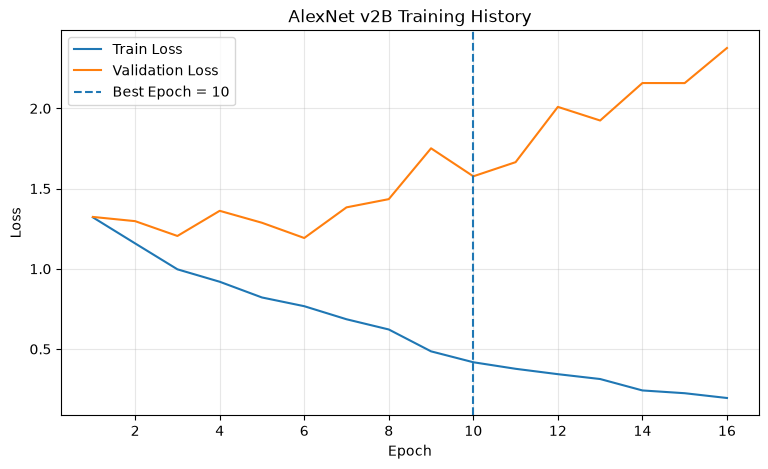

In [96]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2b_history["epoch"],
    alexnet_v2b_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    alexnet_v2b_history["epoch"],
    alexnet_v2b_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=10,
    linestyle="--",
    label="Best Epoch = 10"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet v2B Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

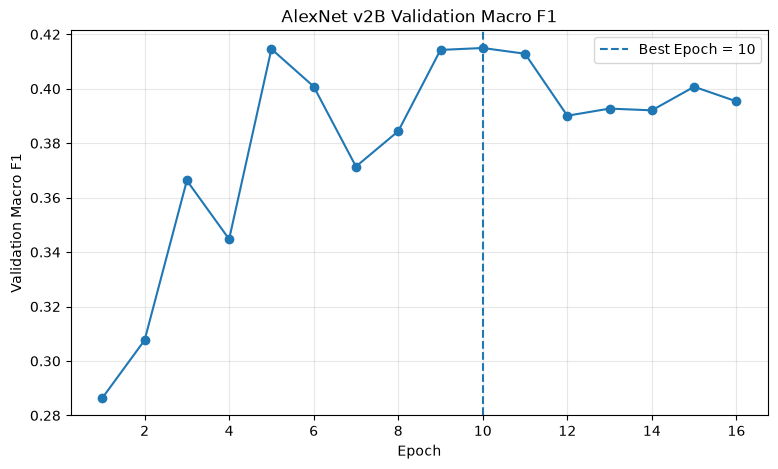

In [97]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2b_history["epoch"],
    alexnet_v2b_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=10,
    linestyle="--",
    label="Best Epoch = 10"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("AlexNet v2B Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

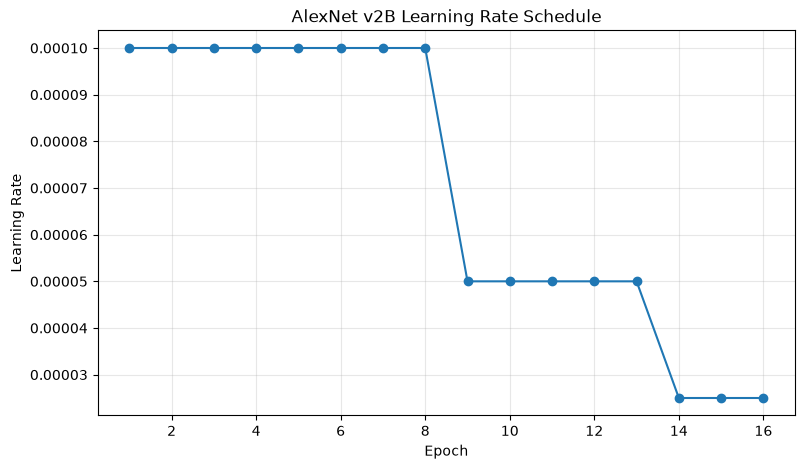

In [98]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2b_history["epoch"],
    alexnet_v2b_history["learning_rate"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("AlexNet v2B Learning Rate Schedule")
plt.grid(alpha=0.3)

plt.show()

In [99]:
alexnet_v2c_val_metrics = evaluate_model(
    alexnet_v2c,
    val_loader,
    prepare_pretrained_input
)

print("===== AlexNet v2C Validation Result =====")

for key, value in alexnet_v2c_val_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== AlexNet v2C Validation Result =====
loss                : 1.4339
accuracy            : 0.5066
balanced_accuracy   : 0.4326
macro_f1            : 0.4236


              precision    recall  f1-score   support

        Both      0.191     0.263     0.221        80
     Crackle      0.436     0.577     0.497       336
      Normal      0.676     0.536     0.598       584
      Wheeze      0.407     0.355     0.379       141

    accuracy                          0.507      1141
   macro avg      0.427     0.433     0.424      1141
weighted avg      0.538     0.507     0.515      1141



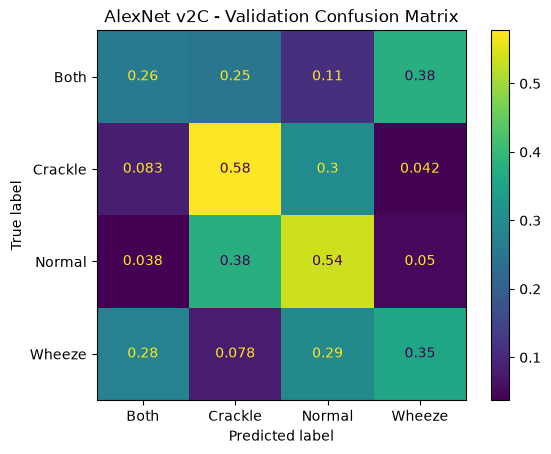

In [100]:
alexnet_v2c.eval()

alexnet_v2c_preds = []
alexnet_v2c_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = alexnet_v2c(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        alexnet_v2c_preds.extend(
            preds.cpu().numpy()
        )

        alexnet_v2c_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        alexnet_v2c_labels,
        alexnet_v2c_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    alexnet_v2c_labels,
    alexnet_v2c_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "AlexNet v2C - Validation Confusion Matrix"
)

plt.show()

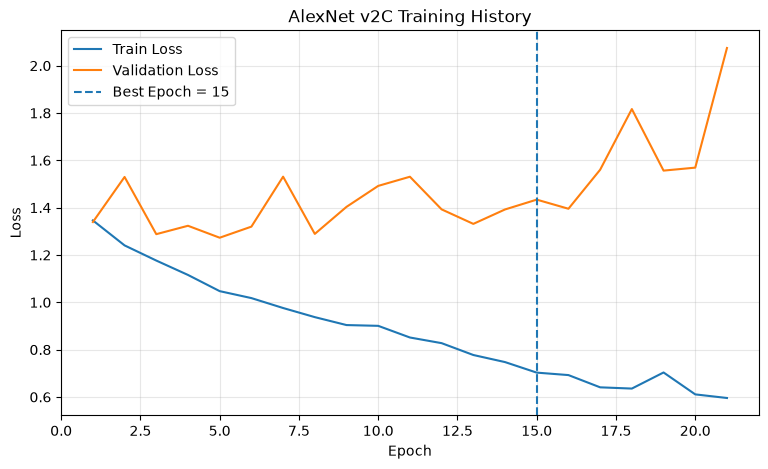

In [101]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2c_history["epoch"],
    alexnet_v2c_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    alexnet_v2c_history["epoch"],
    alexnet_v2c_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=15,
    linestyle="--",
    label="Best Epoch = 15"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet v2C Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

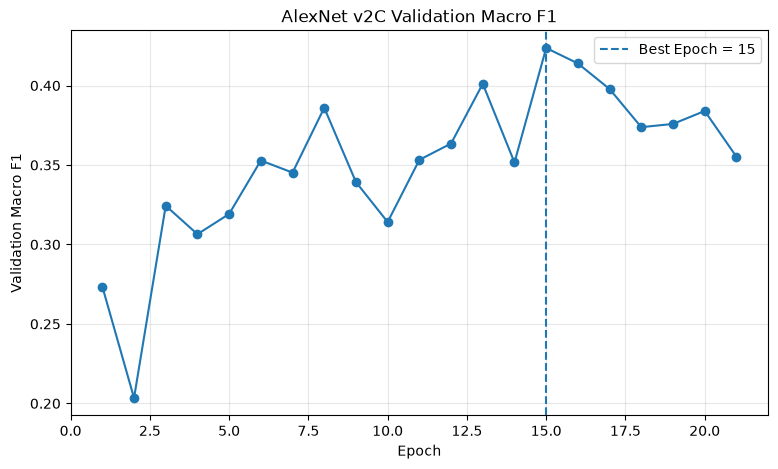

In [102]:
plt.figure(figsize=(9, 5))

plt.plot(
    alexnet_v2c_history["epoch"],
    alexnet_v2c_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=15,
    linestyle="--",
    label="Best Epoch = 15"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("AlexNet v2C Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [103]:
from torchvision import models
import torch.nn as nn

vgg16_ft = models.vgg16(
    weights=models.VGG16_Weights.IMAGENET1K_V1
)

vgg16_ft.classifier[6] = nn.Linear(
    vgg16_ft.classifier[6].in_features,
    4
)

vgg16_ft = vgg16_ft.to(device)

In [104]:
for param in vgg16_ft.features.parameters():
    param.requires_grad = False

print("Feature extractor frozen.")

Feature extractor frozen.


In [105]:
trainable_params = sum(
    p.numel()
    for p in vgg16_ft.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in vgg16_ft.parameters()
)

print("Trainable params:", trainable_params)
print("Total params    :", total_params)
print(
    "Trainable ratio :",
    round(trainable_params / total_params, 4)
)

Trainable params: 119562244
Total params    : 134276932
Trainable ratio : 0.8904


In [106]:
vgg16_stage1_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        vgg16_ft.parameters()
    ),
    lr=1e-4,
    weight_decay=1e-4
)

In [107]:
vgg16_ft, vgg16_stage1_history = train_model(
    model=vgg16_ft,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=vgg16_stage1_optimizer,
    max_epochs=10,
    patience=4
)

Epoch 01 | Train Loss 1.3163 | Val Loss 1.3424 | Val Acc 0.4575 | Bal Acc 0.2912 | Macro F1 0.2725
Epoch 02 | Train Loss 1.1276 | Val Loss 1.3708 | Val Acc 0.4680 | Bal Acc 0.3255 | Macro F1 0.3265
Epoch 03 | Train Loss 0.9541 | Val Loss 1.4453 | Val Acc 0.3839 | Bal Acc 0.3402 | Macro F1 0.3080
Epoch 04 | Train Loss 0.7889 | Val Loss 1.5487 | Val Acc 0.4750 | Bal Acc 0.3542 | Macro F1 0.3480
Epoch 05 | Train Loss 0.6611 | Val Loss 1.6525 | Val Acc 0.3804 | Bal Acc 0.3403 | Macro F1 0.2993
Epoch 06 | Train Loss 0.5658 | Val Loss 1.6309 | Val Acc 0.4470 | Bal Acc 0.3742 | Macro F1 0.3572
Epoch 07 | Train Loss 0.4602 | Val Loss 1.7404 | Val Acc 0.4452 | Bal Acc 0.3721 | Macro F1 0.3345
Epoch 08 | Train Loss 0.3806 | Val Loss 1.7602 | Val Acc 0.4654 | Bal Acc 0.4004 | Macro F1 0.3786
Epoch 09 | Train Loss 0.4150 | Val Loss 1.9753 | Val Acc 0.5399 | Bal Acc 0.3811 | Macro F1 0.3817
Epoch 10 | Train Loss 0.3044 | Val Loss 2.2266 | Val Acc 0.5039 | Bal Acc 0.3559 | Macro F1 0.3446

Best epoc

In [108]:
for param in vgg16_ft.features[24:].parameters():
    param.requires_grad = True

In [109]:
trainable_params_stage2 = sum(
    p.numel()
    for p in vgg16_ft.parameters()
    if p.requires_grad
)

print(
    "Stage 2 trainable params:",
    trainable_params_stage2
)

Stage 2 trainable params: 126641668


In [110]:
vgg16_ft2 = models.vgg16(
    weights=models.VGG16_Weights.IMAGENET1K_V1
)

vgg16_ft2.classifier[6] = nn.Linear(
    vgg16_ft2.classifier[6].in_features,
    4
)

# 전체 freeze
for param in vgg16_ft2.parameters():
    param.requires_grad = False

# 마지막 분류층만 학습
for param in vgg16_ft2.classifier[6].parameters():
    param.requires_grad = True

vgg16_ft2 = vgg16_ft2.to(device)

In [111]:
trainable_params = sum(
    p.numel()
    for p in vgg16_ft2.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in vgg16_ft2.parameters()
)

print("Trainable params :", trainable_params)
print("Total params     :", total_params)
print(
    "Trainable ratio  :",
    trainable_params / total_params
)

Trainable params : 16388
Total params     : 134276932
Trainable ratio  : 0.00012204627969903274


In [112]:
vgg16_ft2_stage1_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        vgg16_ft2.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

In [113]:
vgg16_ft2, vgg16_ft2_stage1_history = train_model(
    model=vgg16_ft2,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=vgg16_ft2_stage1_optimizer,
    max_epochs=10,
    patience=4
)

Epoch 01 | Train Loss 1.3734 | Val Loss 1.4690 | Val Acc 0.2752 | Bal Acc 0.2897 | Macro F1 0.2321
Epoch 02 | Train Loss 1.3059 | Val Loss 1.4252 | Val Acc 0.2910 | Bal Acc 0.2785 | Macro F1 0.1924
Epoch 03 | Train Loss 1.3003 | Val Loss 1.3700 | Val Acc 0.3996 | Bal Acc 0.2769 | Macro F1 0.2511
Epoch 04 | Train Loss 1.2991 | Val Loss 1.4198 | Val Acc 0.3216 | Bal Acc 0.2656 | Macro F1 0.1947
Epoch 05 | Train Loss 1.2802 | Val Loss 1.3421 | Val Acc 0.4461 | Bal Acc 0.2985 | Macro F1 0.2851
Epoch 06 | Train Loss 1.2916 | Val Loss 1.3642 | Val Acc 0.3672 | Bal Acc 0.3381 | Macro F1 0.3070
Epoch 07 | Train Loss 1.2892 | Val Loss 1.3796 | Val Acc 0.4032 | Bal Acc 0.2819 | Macro F1 0.2584
Epoch 08 | Train Loss 1.2843 | Val Loss 1.4804 | Val Acc 0.2918 | Bal Acc 0.2597 | Macro F1 0.1896
Epoch 09 | Train Loss 1.2666 | Val Loss 1.4572 | Val Acc 0.2603 | Bal Acc 0.2721 | Macro F1 0.2165
Epoch 10 | Train Loss 1.2773 | Val Loss 1.3712 | Val Acc 0.4198 | Bal Acc 0.2957 | Macro F1 0.2866

Early sto

In [114]:
vgg16_ft2_stage1_metrics = evaluate_model(
    vgg16_ft2,
    val_loader,
    prepare_pretrained_input
)

print("===== VGG16 FT2 Stage 1 Validation Result =====")

for key, value in vgg16_ft2_stage1_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== VGG16 FT2 Stage 1 Validation Result =====
loss                : 1.3642
accuracy            : 0.3672
balanced_accuracy   : 0.3381
macro_f1            : 0.3070


              precision    recall  f1-score   support

        Both      0.068     0.163     0.096        80
     Crackle      0.411     0.557     0.473       336
      Normal      0.681     0.293     0.410       584
      Wheeze      0.198     0.340     0.250       141

    accuracy                          0.367      1141
   macro avg      0.339     0.338     0.307      1141
weighted avg      0.499     0.367     0.386      1141



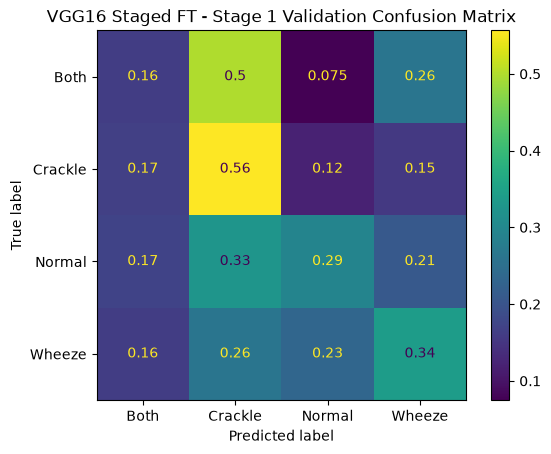

In [115]:
vgg16_ft2.eval()

vgg16_ft2_stage1_preds = []
vgg16_ft2_stage1_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = vgg16_ft2(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        vgg16_ft2_stage1_preds.extend(
            preds.cpu().numpy()
        )

        vgg16_ft2_stage1_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        vgg16_ft2_stage1_labels,
        vgg16_ft2_stage1_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    vgg16_ft2_stage1_labels,
    vgg16_ft2_stage1_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "VGG16 Staged FT - Stage 1 Validation Confusion Matrix"
)

plt.show()

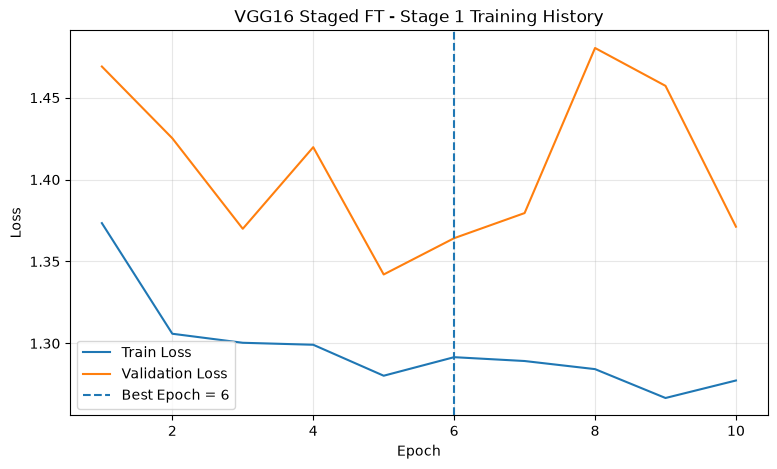

In [116]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_ft2_stage1_history["epoch"],
    vgg16_ft2_stage1_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    vgg16_ft2_stage1_history["epoch"],
    vgg16_ft2_stage1_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Staged FT - Stage 1 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

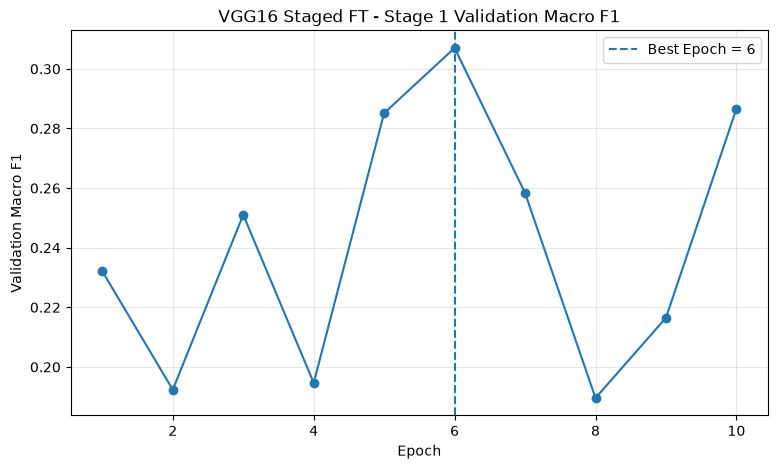

In [117]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_ft2_stage1_history["epoch"],
    vgg16_ft2_stage1_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("VGG16 Staged FT - Stage 1 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [118]:
for param in vgg16_ft2.features[24:].parameters():
    param.requires_grad = True

In [119]:
trainable_params_stage2 = sum(
    p.numel()
    for p in vgg16_ft2.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in vgg16_ft2.parameters()
)

print("Stage 2 trainable params :", trainable_params_stage2)
print("Total params             :", total_params)
print(
    "Trainable ratio          :",
    trainable_params_stage2 / total_params
)

Stage 2 trainable params : 7095812
Total params             : 134276932
Trainable ratio          : 0.052844609228932936


In [120]:
vgg16_ft2_stage2_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        vgg16_ft2.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-4
)

In [121]:
vgg16_ft2, vgg16_ft2_stage2_history = train_model(
    model=vgg16_ft2,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=vgg16_ft2_stage2_optimizer,
    max_epochs=20,
    patience=5
)

Epoch 01 | Train Loss 1.1812 | Val Loss 1.3175 | Val Acc 0.4163 | Bal Acc 0.3329 | Macro F1 0.3140
Epoch 02 | Train Loss 1.0842 | Val Loss 1.3221 | Val Acc 0.3830 | Bal Acc 0.3293 | Macro F1 0.2895
Epoch 03 | Train Loss 1.0387 | Val Loss 1.2982 | Val Acc 0.3900 | Bal Acc 0.3346 | Macro F1 0.2989
Epoch 04 | Train Loss 0.9763 | Val Loss 1.2936 | Val Acc 0.4163 | Bal Acc 0.3498 | Macro F1 0.3162
Epoch 05 | Train Loss 0.9553 | Val Loss 1.2995 | Val Acc 0.4102 | Bal Acc 0.3456 | Macro F1 0.3094
Epoch 06 | Train Loss 0.9040 | Val Loss 1.2977 | Val Acc 0.4294 | Bal Acc 0.3657 | Macro F1 0.3410
Epoch 07 | Train Loss 0.8790 | Val Loss 1.2742 | Val Acc 0.4277 | Bal Acc 0.3617 | Macro F1 0.3305
Epoch 08 | Train Loss 0.8549 | Val Loss 1.2790 | Val Acc 0.4303 | Bal Acc 0.3700 | Macro F1 0.3402
Epoch 09 | Train Loss 0.7950 | Val Loss 1.2832 | Val Acc 0.4286 | Bal Acc 0.3684 | Macro F1 0.3425
Epoch 10 | Train Loss 0.7765 | Val Loss 1.2801 | Val Acc 0.4435 | Bal Acc 0.3728 | Macro F1 0.3472
Epoch 11 |

In [122]:
vgg16_ft2_stage2_metrics = evaluate_model(
    vgg16_ft2,
    val_loader,
    prepare_pretrained_input
)

print("===== VGG16 FT2 Stage 2 Validation Result =====")

for key, value in vgg16_ft2_stage2_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== VGG16 FT2 Stage 2 Validation Result =====
loss                : 1.3210
accuracy            : 0.5162
balanced_accuracy   : 0.4012
macro_f1            : 0.3938


              precision    recall  f1-score   support

        Both      0.143     0.075     0.098        80
     Crackle      0.437     0.732     0.547       336
      Normal      0.664     0.507     0.575       584
      Wheeze      0.456     0.291     0.355       141

    accuracy                          0.516      1141
   macro avg      0.425     0.401     0.394      1141
weighted avg      0.535     0.516     0.506      1141



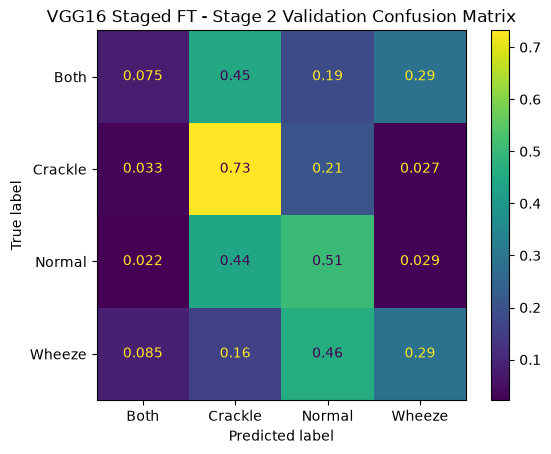

In [123]:
vgg16_ft2.eval()

vgg16_ft2_stage2_preds = []
vgg16_ft2_stage2_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = vgg16_ft2(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        vgg16_ft2_stage2_preds.extend(
            preds.cpu().numpy()
        )

        vgg16_ft2_stage2_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        vgg16_ft2_stage2_labels,
        vgg16_ft2_stage2_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    vgg16_ft2_stage2_labels,
    vgg16_ft2_stage2_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "VGG16 Staged FT - Stage 2 Validation Confusion Matrix"
)

plt.show()

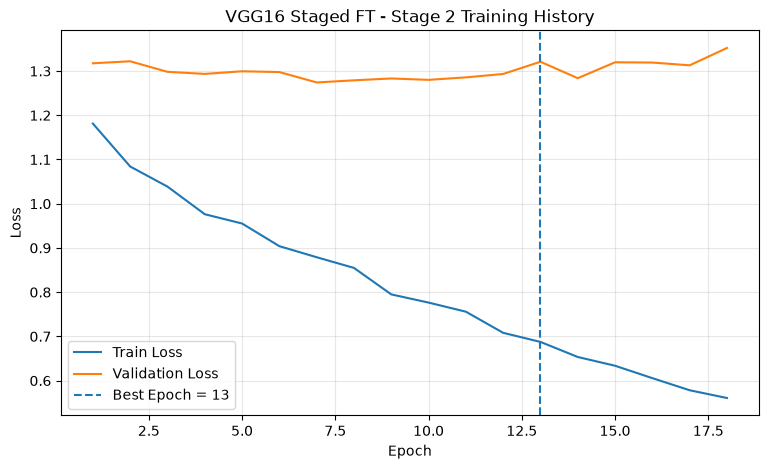

In [124]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_ft2_stage2_history["epoch"],
    vgg16_ft2_stage2_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    vgg16_ft2_stage2_history["epoch"],
    vgg16_ft2_stage2_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=13,
    linestyle="--",
    label="Best Epoch = 13"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Staged FT - Stage 2 Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

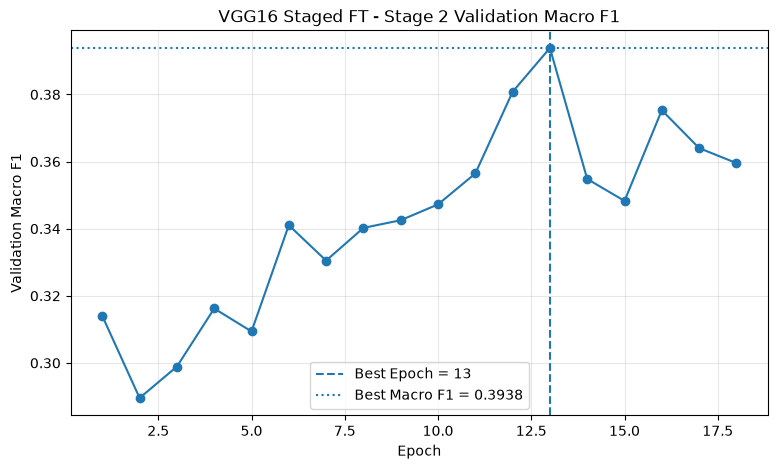

In [125]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_ft2_stage2_history["epoch"],
    vgg16_ft2_stage2_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=13,
    linestyle="--",
    label="Best Epoch = 13"
)

plt.axhline(
    y=0.3938,
    linestyle=":",
    label="Best Macro F1 = 0.3938"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title("VGG16 Staged FT - Stage 2 Validation Macro F1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [126]:
trackB_improvement_results = pd.DataFrame([
    {
        "Model": "AlexNet Base",
        "Strategy": "Full FT / No Aug / Fixed LR",
        "Best_Epoch": 9,
        "Accuracy": 0.5662,
        "Balanced_Accuracy": 0.4736,
        "Macro_F1": 0.4562,
        "Both_Recall": 0.100,
        "Crackle_Recall": 0.601,
        "Normal_Recall": 0.604,
        "Wheeze_Recall": 0.589
    },
    {
        "Model": "AlexNet 2A",
        "Strategy": "SpecAug + Scheduler",
        "Best_Epoch": 17,
        "Accuracy": 0.5355,
        "Balanced_Accuracy": 0.4478,
        "Macro_F1": 0.4412,
        "Both_Recall": 0.275,
        "Crackle_Recall": 0.613,
        "Normal_Recall": 0.577,
        "Wheeze_Recall": 0.326
    },
    {
        "Model": "AlexNet 2B",
        "Strategy": "Scheduler Only",
        "Best_Epoch": 10,
        "Accuracy": 0.5434,
        "Balanced_Accuracy": 0.4204,
        "Macro_F1": 0.4150,
        "Both_Recall": 0.275,
        "Crackle_Recall": 0.622,
        "Normal_Recall": 0.628,
        "Wheeze_Recall": 0.156
    },
    {
        "Model": "AlexNet 2C",
        "Strategy": "SpecAug Only",
        "Best_Epoch": 15,
        "Accuracy": 0.5066,
        "Balanced_Accuracy": 0.4326,
        "Macro_F1": 0.4236,
        "Both_Recall": 0.263,
        "Crackle_Recall": 0.577,
        "Normal_Recall": 0.536,
        "Wheeze_Recall": 0.355
    },
    {
        "Model": "VGG16 Original",
        "Strategy": "Full Fine-Tuning",
        "Best_Epoch": 15,
        "Accuracy": 0.5933,
        "Balanced_Accuracy": 0.4501,
        "Macro_F1": 0.4531,
        "Both_Recall": 0.075,
        "Crackle_Recall": 0.458,
        "Normal_Recall": 0.764,
        "Wheeze_Recall": 0.504
    },
    {
        "Model": "VGG16 Stage 1",
        "Strategy": "Head Only",
        "Best_Epoch": 6,
        "Accuracy": 0.3672,
        "Balanced_Accuracy": 0.3381,
        "Macro_F1": 0.3070,
        "Both_Recall": 0.163,
        "Crackle_Recall": 0.557,
        "Normal_Recall": 0.293,
        "Wheeze_Recall": 0.340
    },
    {
        "Model": "VGG16 Stage 2",
        "Strategy": "Last Conv Block + Head",
        "Best_Epoch": 13,
        "Accuracy": 0.5162,
        "Balanced_Accuracy": 0.4012,
        "Macro_F1": 0.3938,
        "Both_Recall": 0.075,
        "Crackle_Recall": 0.732,
        "Normal_Recall": 0.507,
        "Wheeze_Recall": 0.291
    }
])

trackB_improvement_results

,Model,Strategy,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,AlexNet Base,Full FT / No Aug / Fixed LR,9,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589
1,AlexNet 2A,SpecAug + Scheduler,17,0.5355,0.4478,0.4412,0.275,0.613,0.577,0.326
2,AlexNet 2B,Scheduler Only,10,0.5434,0.4204,0.4150,0.275,0.622,0.628,0.156
3,AlexNet 2C,SpecAug Only,15,0.5066,0.4326,0.4236,0.263,0.577,0.536,0.355
4,VGG16 Original,Full Fine-Tuning,15,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504
5,VGG16 Stage 1,Head Only,6,0.3672,0.3381,0.3070,0.163,0.557,0.293,0.340
6,VGG16 Stage 2,Last Conv Block + Head,13,0.5162,0.4012,0.3938,0.075,0.732,0.507,0.291


In [127]:
trackB_improvement_results_sorted = (
    trackB_improvement_results
    .sort_values("Macro_F1", ascending=False)
    .reset_index(drop=True)
)

trackB_improvement_results_sorted

,Model,Strategy,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,AlexNet Base,Full FT / No Aug / Fixed LR,9,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589
1,VGG16 Original,Full Fine-Tuning,15,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504
2,AlexNet 2A,SpecAug + Scheduler,17,0.5355,0.4478,0.4412,0.275,0.613,0.577,0.326
3,AlexNet 2C,SpecAug Only,15,0.5066,0.4326,0.4236,0.263,0.577,0.536,0.355
4,AlexNet 2B,Scheduler Only,10,0.5434,0.4204,0.4150,0.275,0.622,0.628,0.156
5,VGG16 Stage 2,Last Conv Block + Head,13,0.5162,0.4012,0.3938,0.075,0.732,0.507,0.291
6,VGG16 Stage 1,Head Only,6,0.3672,0.3381,0.3070,0.163,0.557,0.293,0.340


In [128]:
from pathlib import Path

results_dir = Path(
    r"D:\2026\final_project\results\trackB"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    results_dir
    / "TrackB_improvement_validation_results_v1.csv"
)

trackB_improvement_results_sorted.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", output_path)

Saved: D:\2026\final_project\results\trackB\TrackB_improvement_validation_results_v1.csv


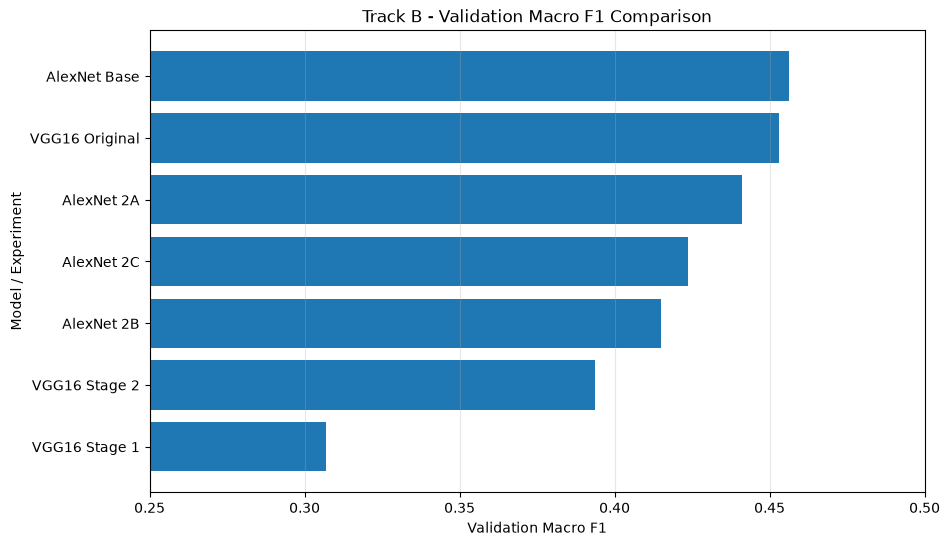

In [129]:
plt.figure(figsize=(10, 6))

plot_df = (
    trackB_improvement_results_sorted
    .sort_values("Macro_F1")
)

plt.barh(
    plot_df["Model"],
    plot_df["Macro_F1"]
)

plt.xlabel("Validation Macro F1")
plt.ylabel("Model / Experiment")
plt.title(
    "Track B - Validation Macro F1 Comparison"
)

plt.xlim(0.25, 0.50)
plt.grid(
    axis="x",
    alpha=0.3
)

plt.show()

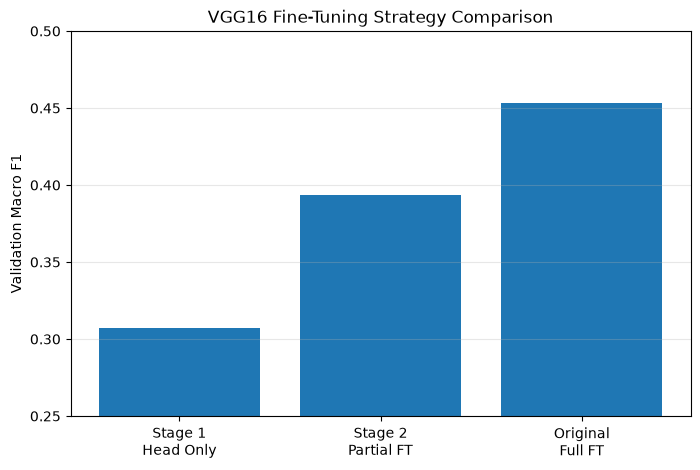

In [130]:
vgg16_compare = pd.DataFrame({
    "Strategy": [
        "Stage 1\nHead Only",
        "Stage 2\nPartial FT",
        "Original\nFull FT"
    ],
    "Macro_F1": [
        0.3070,
        0.3938,
        0.4531
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    vgg16_compare["Strategy"],
    vgg16_compare["Macro_F1"]
)

plt.ylabel("Validation Macro F1")
plt.title(
    "VGG16 Fine-Tuning Strategy Comparison"
)

plt.ylim(0.25, 0.50)
plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [131]:
from torchvision import models

# 1. ImageNet pretrained ResNet50 새로 로드
resnet50_ft = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# 2. 마지막 분류층을 4-class로 교체
resnet50_ft.fc = torch.nn.Linear(
    resnet50_ft.fc.in_features,
    len(CLASS_NAMES)
)

# 3. 모든 parameter freeze
for param in resnet50_ft.parameters():
    param.requires_grad = False

# 4. 마지막 FC layer만 학습 가능하게 설정
for param in resnet50_ft.fc.parameters():
    param.requires_grad = True

# GPU로 이동
resnet50_ft = resnet50_ft.to(device)

In [132]:
resnet50_stage1_trainable = sum(
    p.numel()
    for p in resnet50_ft.parameters()
    if p.requires_grad
)

resnet50_total = sum(
    p.numel()
    for p in resnet50_ft.parameters()
)

print("===== ResNet50 Stage 1 Parameter Check =====")
print("Trainable params :", resnet50_stage1_trainable)
print("Total params     :", resnet50_total)
print(
    "Trainable ratio  :",
    resnet50_stage1_trainable / resnet50_total
)

===== ResNet50 Stage 1 Parameter Check =====
Trainable params : 8196
Total params     : 23516228
Trainable ratio  : 0.00034852528220086996


In [133]:
resnet50_stage1_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet50_ft.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

resnet50_ft, resnet50_stage1_history = train_model(
    model=resnet50_ft,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet50_stage1_optimizer,
    max_epochs=10,
    patience=4
)

Epoch 01 | Train Loss 1.3216 | Val Loss 1.3576 | Val Acc 0.3365 | Bal Acc 0.2422 | Macro F1 0.2410
Epoch 02 | Train Loss 1.2317 | Val Loss 1.3625 | Val Acc 0.3602 | Bal Acc 0.3014 | Macro F1 0.2651
Epoch 03 | Train Loss 1.1967 | Val Loss 1.3496 | Val Acc 0.3576 | Bal Acc 0.2969 | Macro F1 0.2745
Epoch 04 | Train Loss 1.1450 | Val Loss 1.3435 | Val Acc 0.4154 | Bal Acc 0.2912 | Macro F1 0.2863
Epoch 05 | Train Loss 1.1070 | Val Loss 1.3524 | Val Acc 0.4058 | Bal Acc 0.3178 | Macro F1 0.2927
Epoch 06 | Train Loss 1.0949 | Val Loss 1.3509 | Val Acc 0.4040 | Bal Acc 0.3326 | Macro F1 0.3198
Epoch 07 | Train Loss 1.0593 | Val Loss 1.3730 | Val Acc 0.3988 | Bal Acc 0.3211 | Macro F1 0.3024
Epoch 08 | Train Loss 1.0345 | Val Loss 1.3619 | Val Acc 0.3961 | Bal Acc 0.2949 | Macro F1 0.2759
Epoch 09 | Train Loss 1.0170 | Val Loss 1.3625 | Val Acc 0.3926 | Bal Acc 0.3015 | Macro F1 0.2957
Epoch 10 | Train Loss 0.9991 | Val Loss 1.3717 | Val Acc 0.4102 | Bal Acc 0.3130 | Macro F1 0.3012

Early sto

In [134]:
resnet50_stage1_metrics = evaluate_model(
    resnet50_ft,
    val_loader,
    prepare_pretrained_input
)

print("===== ResNet50 Stage 1 Validation Result =====")

for key, value in resnet50_stage1_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== ResNet50 Stage 1 Validation Result =====
loss                : 1.3509
accuracy            : 0.4040
balanced_accuracy   : 0.3326
macro_f1            : 0.3198


              precision    recall  f1-score   support

        Both      0.094     0.163     0.119        80
     Crackle      0.370     0.488     0.421       336
      Normal      0.653     0.425     0.515       584
      Wheeze      0.200     0.255     0.224       141

    accuracy                          0.404      1141
   macro avg      0.329     0.333     0.320      1141
weighted avg      0.474     0.404     0.423      1141



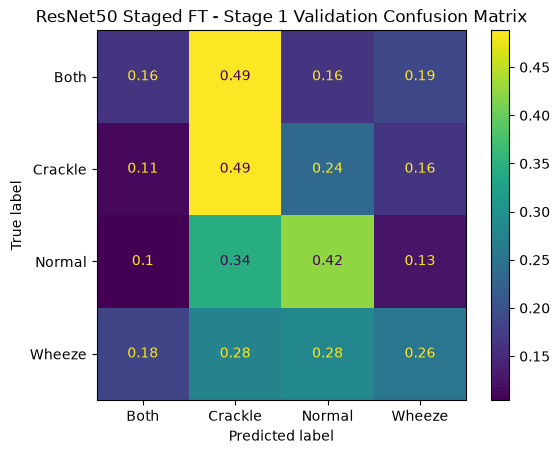

In [135]:
resnet50_ft.eval()

resnet50_stage1_preds = []
resnet50_stage1_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = resnet50_ft(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        resnet50_stage1_preds.extend(
            preds.cpu().numpy()
        )

        resnet50_stage1_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        resnet50_stage1_labels,
        resnet50_stage1_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    resnet50_stage1_labels,
    resnet50_stage1_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "ResNet50 Staged FT - Stage 1 Validation Confusion Matrix"
)

plt.show()

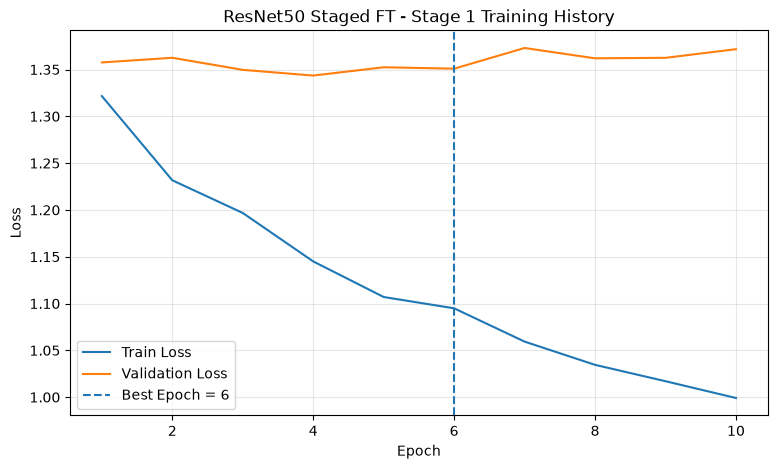

In [136]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage1_history["epoch"],
    resnet50_stage1_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    resnet50_stage1_history["epoch"],
    resnet50_stage1_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "ResNet50 Staged FT - Stage 1 Training History"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

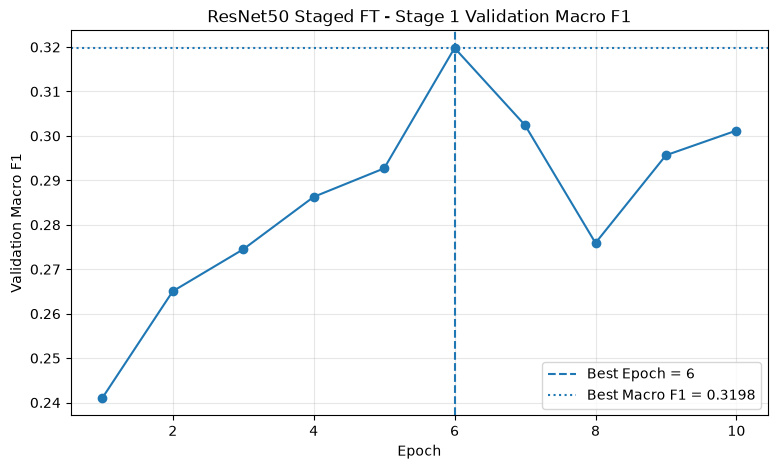

In [137]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage1_history["epoch"],
    resnet50_stage1_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.axhline(
    y=0.3198,
    linestyle=":",
    label="Best Macro F1 = 0.3198"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title(
    "ResNet50 Staged FT - Stage 1 Validation Macro F1"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [138]:
import random
import numpy as np
import torch
from torchvision import models

SEED = 777

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Fresh pretrained ResNet50
resnet50_ft_ext = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# 4-class classifier
resnet50_ft_ext.fc = torch.nn.Linear(
    resnet50_ft_ext.fc.in_features,
    len(CLASS_NAMES)
)

# Freeze all
for param in resnet50_ft_ext.parameters():
    param.requires_grad = False

# Unfreeze classifier only
for param in resnet50_ft_ext.fc.parameters():
    param.requires_grad = True

resnet50_ft_ext = resnet50_ft_ext.to(device)

In [139]:
resnet50_ext_trainable = sum(
    p.numel()
    for p in resnet50_ft_ext.parameters()
    if p.requires_grad
)

resnet50_ext_total = sum(
    p.numel()
    for p in resnet50_ft_ext.parameters()
)

print("===== ResNet50 Stage 1 Extended Parameter Check =====")
print("Trainable params :", resnet50_ext_trainable)
print("Total params     :", resnet50_ext_total)
print(
    "Trainable ratio  :",
    resnet50_ext_trainable / resnet50_ext_total
)

===== ResNet50 Stage 1 Extended Parameter Check =====
Trainable params : 8196
Total params     : 23516228
Trainable ratio  : 0.00034852528220086996


In [140]:
resnet50_stage1_ext_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet50_ft_ext.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

resnet50_ft_ext, resnet50_stage1_ext_history = train_model(
    model=resnet50_ft_ext,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet50_stage1_ext_optimizer,
    max_epochs=50,
    patience=10
)

Epoch 01 | Train Loss 1.3245 | Val Loss 1.3699 | Val Acc 0.3620 | Bal Acc 0.2491 | Macro F1 0.2422
Epoch 02 | Train Loss 1.2279 | Val Loss 1.3798 | Val Acc 0.3357 | Bal Acc 0.2805 | Macro F1 0.2652
Epoch 03 | Train Loss 1.1781 | Val Loss 1.3509 | Val Acc 0.3804 | Bal Acc 0.2923 | Macro F1 0.2830
Epoch 04 | Train Loss 1.1424 | Val Loss 1.3683 | Val Acc 0.3707 | Bal Acc 0.3133 | Macro F1 0.2748
Epoch 05 | Train Loss 1.1080 | Val Loss 1.3555 | Val Acc 0.3856 | Bal Acc 0.2882 | Macro F1 0.2773
Epoch 06 | Train Loss 1.0847 | Val Loss 1.3580 | Val Acc 0.3786 | Bal Acc 0.3117 | Macro F1 0.2892
Epoch 07 | Train Loss 1.0576 | Val Loss 1.3556 | Val Acc 0.3988 | Bal Acc 0.3142 | Macro F1 0.3065
Epoch 08 | Train Loss 1.0380 | Val Loss 1.3712 | Val Acc 0.3830 | Bal Acc 0.3237 | Macro F1 0.2974
Epoch 09 | Train Loss 1.0224 | Val Loss 1.3970 | Val Acc 0.3742 | Bal Acc 0.2983 | Macro F1 0.2841
Epoch 10 | Train Loss 1.0021 | Val Loss 1.3859 | Val Acc 0.3663 | Bal Acc 0.3311 | Macro F1 0.3080
Epoch 11 |

In [141]:
resnet50_stage1_ext_metrics = evaluate_model(
    resnet50_ft_ext,
    val_loader,
    prepare_pretrained_input
)

print("===== ResNet50 Stage 1 Extended Validation Result =====")

for key, value in resnet50_stage1_ext_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== ResNet50 Stage 1 Extended Validation Result =====
loss                : 1.3638
accuracy            : 0.4277
balanced_accuracy   : 0.3489
macro_f1            : 0.3332


              precision    recall  f1-score   support

        Both      0.123     0.163     0.140        80
     Crackle      0.369     0.634     0.466       336
      Normal      0.669     0.401     0.501       584
      Wheeze      0.262     0.199     0.226       141

    accuracy                          0.428      1141
   macro avg      0.355     0.349     0.333      1141
weighted avg      0.492     0.428     0.431      1141



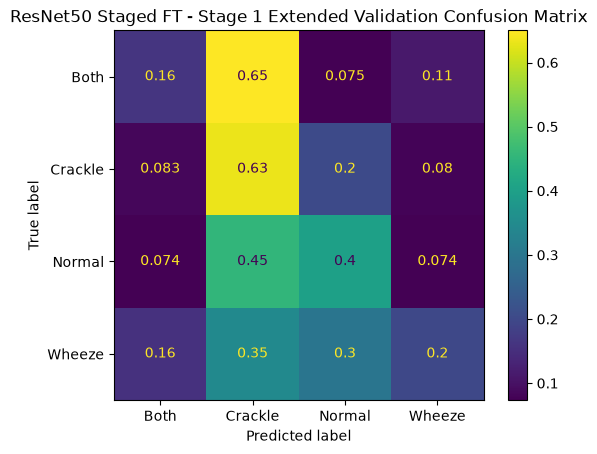

In [142]:
resnet50_ft_ext.eval()

resnet50_stage1_ext_preds = []
resnet50_stage1_ext_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = resnet50_ft_ext(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        resnet50_stage1_ext_preds.extend(
            preds.cpu().numpy()
        )

        resnet50_stage1_ext_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        resnet50_stage1_ext_labels,
        resnet50_stage1_ext_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    resnet50_stage1_ext_labels,
    resnet50_stage1_ext_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "ResNet50 Staged FT - Stage 1 Extended Validation Confusion Matrix"
)

plt.show()

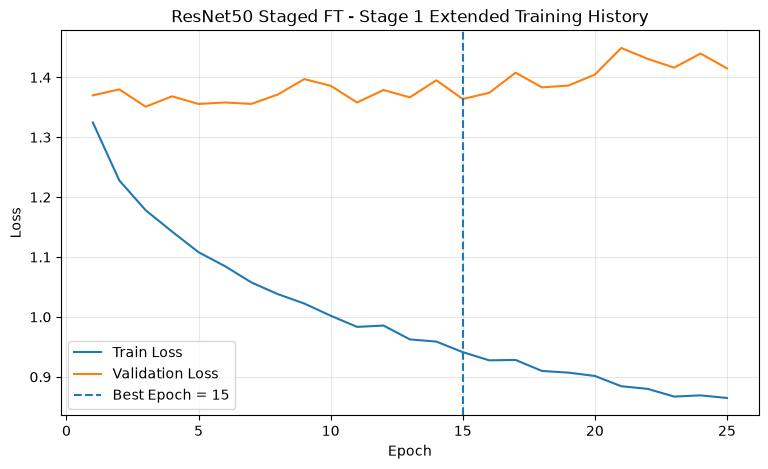

In [143]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage1_ext_history["epoch"],
    resnet50_stage1_ext_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    resnet50_stage1_ext_history["epoch"],
    resnet50_stage1_ext_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=15,
    linestyle="--",
    label="Best Epoch = 15"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Staged FT - Stage 1 Extended Training History"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

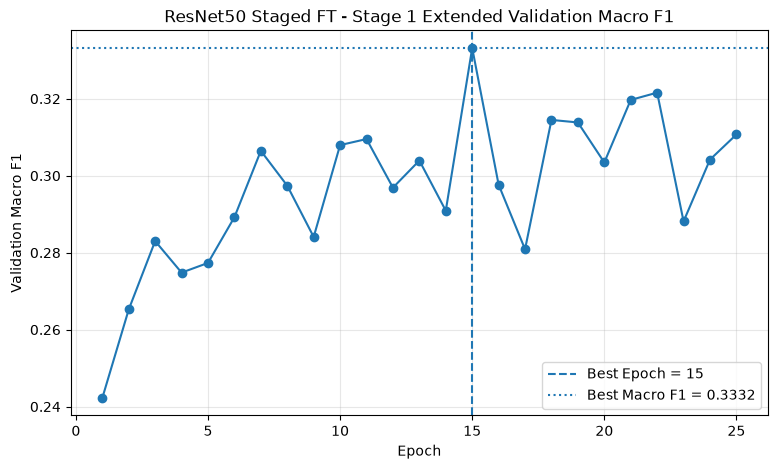

In [144]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage1_ext_history["epoch"],
    resnet50_stage1_ext_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=15,
    linestyle="--",
    label="Best Epoch = 15"
)

plt.axhline(
    y=0.3332,
    linestyle=":",
    label="Best Macro F1 = 0.3332"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")

plt.title(
    "ResNet50 Staged FT - Stage 1 Extended Validation Macro F1"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [145]:
# ==========================================
# ResNet50 Stage 2
# Unfreeze layer4 + fc
# ==========================================

# layer4를 학습 가능하게 설정
for param in resnet50_ft_ext.layer4.parameters():
    param.requires_grad = True

# fc는 이미 trainable이지만 명시적으로 다시 확인
for param in resnet50_ft_ext.fc.parameters():
    param.requires_grad = True

In [146]:
resnet50_stage2_trainable = sum(
    p.numel()
    for p in resnet50_ft_ext.parameters()
    if p.requires_grad
)

resnet50_total = sum(
    p.numel()
    for p in resnet50_ft_ext.parameters()
)

print("===== ResNet50 Stage 2 Parameter Check =====")
print("Trainable params :", resnet50_stage2_trainable)
print("Total params     :", resnet50_total)
print(
    "Trainable ratio  :",
    resnet50_stage2_trainable / resnet50_total
)

===== ResNet50 Stage 2 Parameter Check =====
Trainable params : 14972932
Total params     : 23516228
Trainable ratio  : 0.6367063629422202


In [147]:
resnet50_stage2_optimizer = torch.optim.Adam(
    [
        {
            "params": resnet50_ft_ext.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet50_ft_ext.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

In [148]:
resnet50_ft_ext, resnet50_stage2_history = train_model(
    model=resnet50_ft_ext,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet50_stage2_optimizer,
    max_epochs=50,
    patience=10
)

Epoch 01 | Train Loss 0.8994 | Val Loss 1.3922 | Val Acc 0.3979 | Bal Acc 0.3202 | Macro F1 0.3013
Epoch 02 | Train Loss 0.8114 | Val Loss 1.3502 | Val Acc 0.4356 | Bal Acc 0.3468 | Macro F1 0.3383
Epoch 03 | Train Loss 0.7411 | Val Loss 1.3773 | Val Acc 0.4233 | Bal Acc 0.3450 | Macro F1 0.3304
Epoch 04 | Train Loss 0.6767 | Val Loss 1.3866 | Val Acc 0.4303 | Bal Acc 0.3382 | Macro F1 0.3294
Epoch 05 | Train Loss 0.6117 | Val Loss 1.3907 | Val Acc 0.4023 | Bal Acc 0.3313 | Macro F1 0.3154
Epoch 06 | Train Loss 0.5591 | Val Loss 1.3925 | Val Acc 0.4303 | Bal Acc 0.3478 | Macro F1 0.3332
Epoch 07 | Train Loss 0.4935 | Val Loss 1.4085 | Val Acc 0.4540 | Bal Acc 0.3520 | Macro F1 0.3419
Epoch 08 | Train Loss 0.4456 | Val Loss 1.4380 | Val Acc 0.4487 | Bal Acc 0.3251 | Macro F1 0.3200
Epoch 09 | Train Loss 0.4084 | Val Loss 1.3954 | Val Acc 0.4566 | Bal Acc 0.3518 | Macro F1 0.3465
Epoch 10 | Train Loss 0.3751 | Val Loss 1.5226 | Val Acc 0.4724 | Bal Acc 0.3444 | Macro F1 0.3404
Epoch 11 |

In [149]:
resnet50_stage2_metrics = evaluate_model(
    resnet50_ft_ext,
    val_loader,
    prepare_pretrained_input
)

print("===== ResNet50 Stage 2 Validation Result =====")

for key, value in resnet50_stage2_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== ResNet50 Stage 2 Validation Result =====
loss                : 1.8724
accuracy            : 0.4926
balanced_accuracy   : 0.3539
macro_f1            : 0.3582


              precision    recall  f1-score   support

        Both      0.193     0.138     0.161        80
     Crackle      0.393     0.509     0.444       336
      Normal      0.609     0.613     0.611       584
      Wheeze      0.361     0.156     0.218       141

    accuracy                          0.493      1141
   macro avg      0.389     0.354     0.358      1141
weighted avg      0.485     0.493     0.481      1141



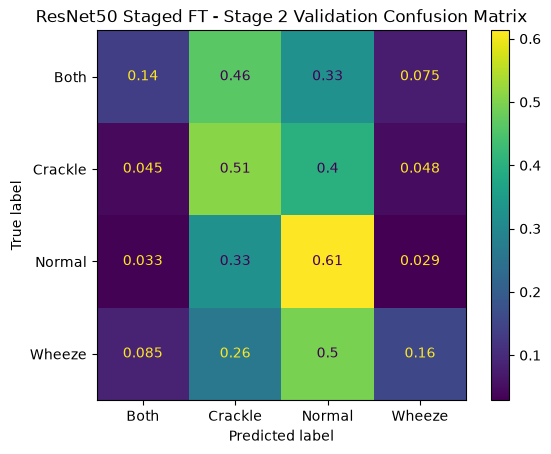

In [150]:
resnet50_ft_ext.eval()

resnet50_stage2_preds = []
resnet50_stage2_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = resnet50_ft_ext(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        resnet50_stage2_preds.extend(
            preds.cpu().numpy()
        )

        resnet50_stage2_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        resnet50_stage2_labels,
        resnet50_stage2_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    resnet50_stage2_labels,
    resnet50_stage2_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "ResNet50 Staged FT - Stage 2 Validation Confusion Matrix"
)

plt.show()

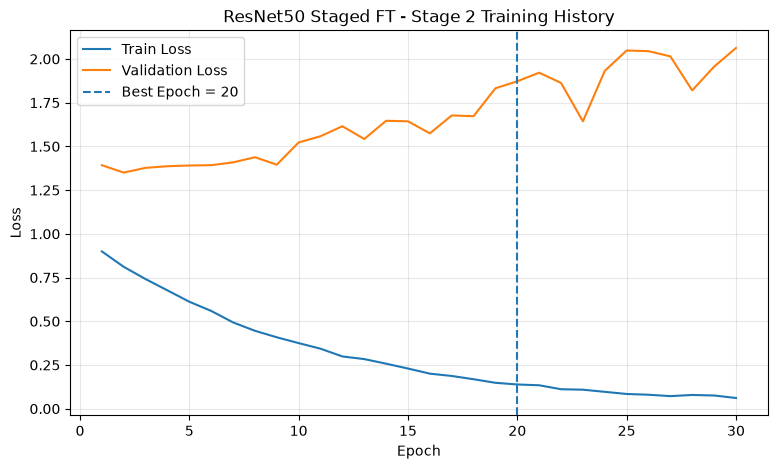

In [151]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage2_history["epoch"],
    resnet50_stage2_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    resnet50_stage2_history["epoch"],
    resnet50_stage2_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=20,
    linestyle="--",
    label="Best Epoch = 20"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Staged FT - Stage 2 Training History"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

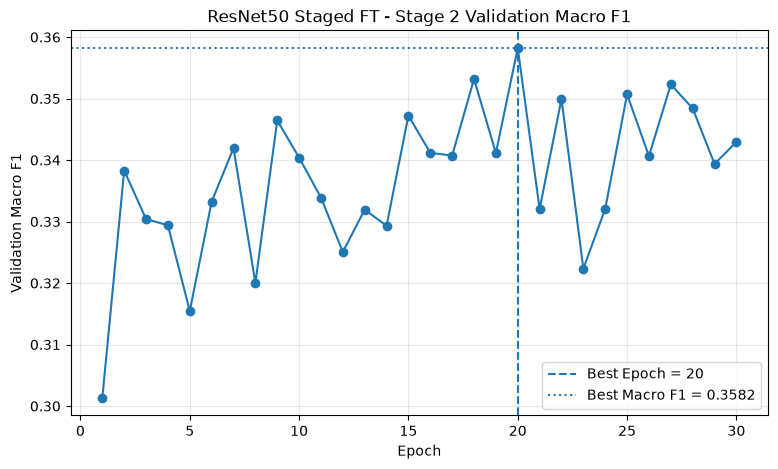

In [152]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage2_history["epoch"],
    resnet50_stage2_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=20,
    linestyle="--",
    label="Best Epoch = 20"
)

plt.axhline(
    y=0.3582,
    linestyle=":",
    label="Best Macro F1 = 0.3582"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")

plt.title(
    "ResNet50 Staged FT - Stage 2 Validation Macro F1"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [153]:
import random
import numpy as np
import torch
from torchvision import models
from pathlib import Path

SEED = 777

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [154]:
resnet50_stage2b = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

resnet50_stage2b.fc = torch.nn.Linear(
    resnet50_stage2b.fc.in_features,
    len(CLASS_NAMES)
)

# 전체 freeze
for param in resnet50_stage2b.parameters():
    param.requires_grad = False

# FC만 학습
for param in resnet50_stage2b.fc.parameters():
    param.requires_grad = True

resnet50_stage2b = resnet50_stage2b.to(device)

In [155]:
resnet50_stage2b_stage1_optimizer = torch.optim.Adam(
    resnet50_stage2b.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

resnet50_stage2b, resnet50_stage2b_stage1_history = train_model(
    model=resnet50_stage2b,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet50_stage2b_stage1_optimizer,
    max_epochs=50,
    patience=10
)

Epoch 01 | Train Loss 1.3245 | Val Loss 1.3699 | Val Acc 0.3620 | Bal Acc 0.2491 | Macro F1 0.2422
Epoch 02 | Train Loss 1.2279 | Val Loss 1.3798 | Val Acc 0.3357 | Bal Acc 0.2805 | Macro F1 0.2652
Epoch 03 | Train Loss 1.1781 | Val Loss 1.3509 | Val Acc 0.3804 | Bal Acc 0.2923 | Macro F1 0.2830
Epoch 04 | Train Loss 1.1424 | Val Loss 1.3683 | Val Acc 0.3707 | Bal Acc 0.3133 | Macro F1 0.2748
Epoch 05 | Train Loss 1.1080 | Val Loss 1.3555 | Val Acc 0.3856 | Bal Acc 0.2882 | Macro F1 0.2773
Epoch 06 | Train Loss 1.0847 | Val Loss 1.3580 | Val Acc 0.3786 | Bal Acc 0.3117 | Macro F1 0.2892
Epoch 07 | Train Loss 1.0576 | Val Loss 1.3556 | Val Acc 0.3988 | Bal Acc 0.3142 | Macro F1 0.3065
Epoch 08 | Train Loss 1.0380 | Val Loss 1.3712 | Val Acc 0.3830 | Bal Acc 0.3237 | Macro F1 0.2974
Epoch 09 | Train Loss 1.0224 | Val Loss 1.3970 | Val Acc 0.3742 | Bal Acc 0.2983 | Macro F1 0.2841
Epoch 10 | Train Loss 1.0021 | Val Loss 1.3859 | Val Acc 0.3663 | Bal Acc 0.3311 | Macro F1 0.3080
Epoch 11 |

In [156]:
checkpoint_dir = Path(
    r"D:\2026\final_project\results\trackB\checkpoints"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

stage1_ckpt_path = (
    checkpoint_dir
    / "ResNet50_Stage1_Extended_seed777.pth"
)

torch.save(
    resnet50_stage2b.state_dict(),
    stage1_ckpt_path
)

print("Saved:", stage1_ckpt_path)

Saved: D:\2026\final_project\results\trackB\checkpoints\ResNet50_Stage1_Extended_seed777.pth


In [157]:
for param in resnet50_stage2b.layer4.parameters():
    param.requires_grad = True

for param in resnet50_stage2b.fc.parameters():
    param.requires_grad = True

In [158]:
trainable_params = sum(
    p.numel()
    for p in resnet50_stage2b.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in resnet50_stage2b.parameters()
)

print("===== ResNet50 Stage 2B Parameter Check =====")
print("Trainable params :", trainable_params)
print("Total params     :", total_params)
print("Trainable ratio  :", trainable_params / total_params)

===== ResNet50 Stage 2B Parameter Check =====
Trainable params : 14972932
Total params     : 23516228
Trainable ratio  : 0.6367063629422202


In [159]:
resnet50_stage2b_optimizer = torch.optim.Adam(
    [
        {
            "params": resnet50_stage2b.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet50_stage2b.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-3
)

In [160]:
resnet50_stage2b, resnet50_stage2b_history = train_model(
    model=resnet50_stage2b,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=resnet50_stage2b_optimizer,
    max_epochs=50,
    patience=10
)

Epoch 01 | Train Loss 0.9132 | Val Loss 1.3522 | Val Acc 0.3786 | Bal Acc 0.3435 | Macro F1 0.3182
Epoch 02 | Train Loss 0.8166 | Val Loss 1.4084 | Val Acc 0.4268 | Bal Acc 0.3400 | Macro F1 0.3324
Epoch 03 | Train Loss 0.7517 | Val Loss 1.3968 | Val Acc 0.4207 | Bal Acc 0.3249 | Macro F1 0.3192
Epoch 04 | Train Loss 0.6825 | Val Loss 1.4224 | Val Acc 0.4540 | Bal Acc 0.3278 | Macro F1 0.3164
Epoch 05 | Train Loss 0.6323 | Val Loss 1.4533 | Val Acc 0.4382 | Bal Acc 0.3392 | Macro F1 0.3319
Epoch 06 | Train Loss 0.5621 | Val Loss 1.4748 | Val Acc 0.4496 | Bal Acc 0.3366 | Macro F1 0.3324
Epoch 07 | Train Loss 0.5123 | Val Loss 1.4510 | Val Acc 0.4505 | Bal Acc 0.3549 | Macro F1 0.3508
Epoch 08 | Train Loss 0.4565 | Val Loss 1.4183 | Val Acc 0.4382 | Bal Acc 0.3431 | Macro F1 0.3349
Epoch 09 | Train Loss 0.4102 | Val Loss 1.4354 | Val Acc 0.4750 | Bal Acc 0.3576 | Macro F1 0.3557
Epoch 10 | Train Loss 0.3933 | Val Loss 1.4786 | Val Acc 0.4689 | Bal Acc 0.3550 | Macro F1 0.3556
Epoch 11 |

In [161]:
resnet50_stage2b_metrics = evaluate_model(
    resnet50_stage2b,
    val_loader,
    prepare_pretrained_input
)

print("===== ResNet50 Stage 2B Validation Result =====")

for key, value in resnet50_stage2b_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== ResNet50 Stage 2B Validation Result =====
loss                : 1.5974
accuracy            : 0.4803
balanced_accuracy   : 0.3617
macro_f1            : 0.3643


              precision    recall  f1-score   support

        Both      0.180     0.138     0.156        80
     Crackle      0.390     0.500     0.438       336
      Normal      0.620     0.575     0.597       584
      Wheeze      0.308     0.234     0.266       141

    accuracy                          0.480      1141
   macro avg      0.375     0.362     0.364      1141
weighted avg      0.483     0.480     0.478      1141



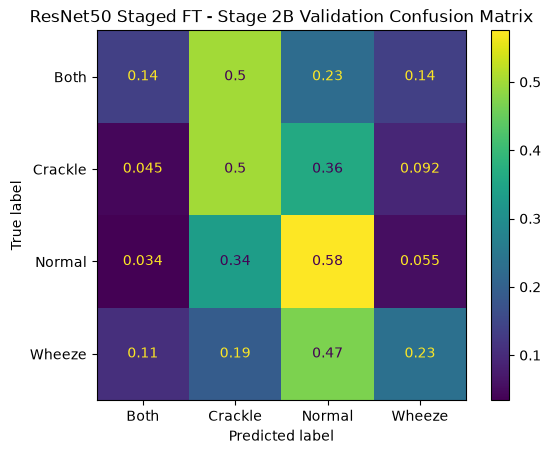

In [162]:
resnet50_stage2b.eval()

resnet50_stage2b_preds = []
resnet50_stage2b_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = resnet50_stage2b(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        resnet50_stage2b_preds.extend(
            preds.cpu().numpy()
        )

        resnet50_stage2b_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        resnet50_stage2b_labels,
        resnet50_stage2b_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    resnet50_stage2b_labels,
    resnet50_stage2b_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "ResNet50 Staged FT - Stage 2B Validation Confusion Matrix"
)

plt.show()

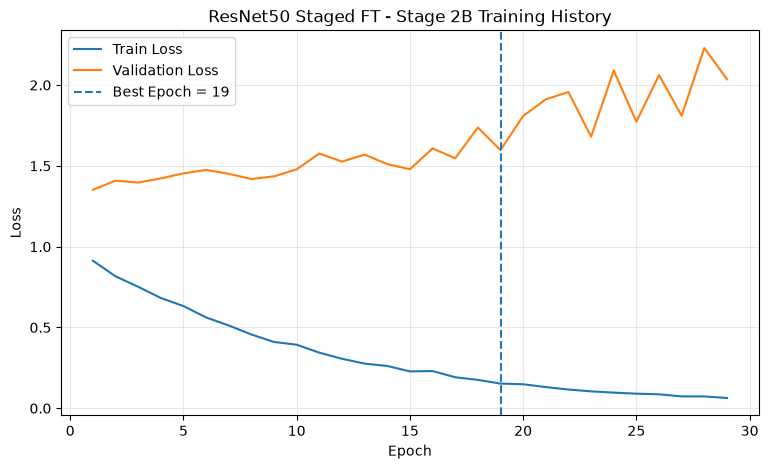

In [163]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage2b_history["epoch"],
    resnet50_stage2b_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    resnet50_stage2b_history["epoch"],
    resnet50_stage2b_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=19,
    linestyle="--",
    label="Best Epoch = 19"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Staged FT - Stage 2B Training History"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

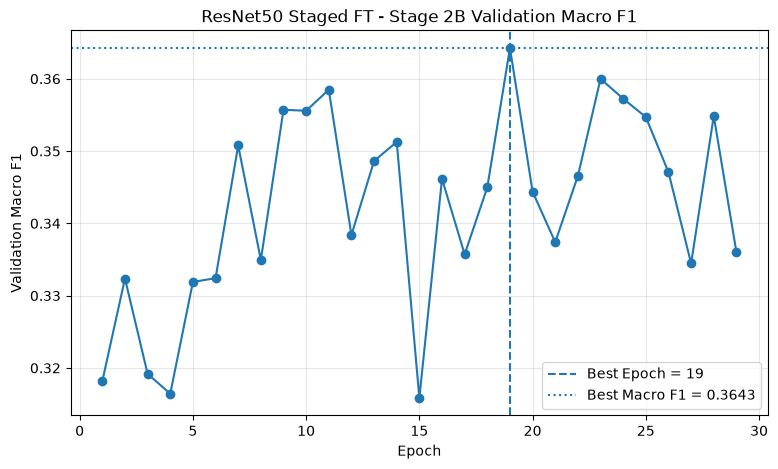

In [164]:
plt.figure(figsize=(9, 5))

plt.plot(
    resnet50_stage2b_history["epoch"],
    resnet50_stage2b_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=19,
    linestyle="--",
    label="Best Epoch = 19"
)

plt.axhline(
    y=0.3643,
    linestyle=":",
    label="Best Macro F1 = 0.3643"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")

plt.title(
    "ResNet50 Staged FT - Stage 2B Validation Macro F1"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

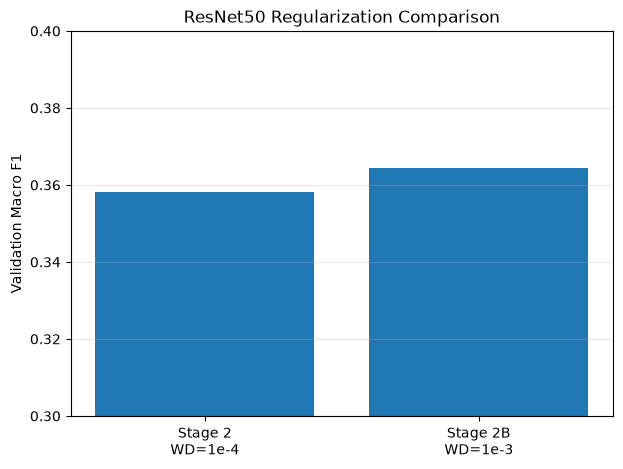

In [165]:
resnet50_reg_compare = pd.DataFrame({
    "Experiment": [
        "Stage 2\nWD=1e-4",
        "Stage 2B\nWD=1e-3"
    ],
    "Macro_F1": [
        0.3582,
        0.3643
    ]
})

plt.figure(figsize=(7, 5))

plt.bar(
    resnet50_reg_compare["Experiment"],
    resnet50_reg_compare["Macro_F1"]
)

plt.ylabel("Validation Macro F1")
plt.title(
    "ResNet50 Regularization Comparison"
)

plt.ylim(0.30, 0.40)
plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [166]:
from pathlib import Path

checkpoint_dir = Path(
    r"D:\2026\final_project\results\trackB\checkpoints"
)

stage2b_ckpt_path = (
    checkpoint_dir
    / "ResNet50_Stage2B_WD1e-3_seed777.pth"
)

torch.save(
    resnet50_stage2b.state_dict(),
    stage2b_ckpt_path
)

print("Saved:", stage2b_ckpt_path)

Saved: D:\2026\final_project\results\trackB\checkpoints\ResNet50_Stage2B_WD1e-3_seed777.pth


In [167]:
resnet50_stage2b_summary = pd.DataFrame([{
    "Model": "ResNet50 Stage 2B",
    "Strategy": "layer4 + FC / WD=1e-3",
    "Best_Epoch": 19,
    "Accuracy": 0.4803,
    "Balanced_Accuracy": 0.3617,
    "Macro_F1": 0.3643,
    "Both_Recall": 0.138,
    "Crackle_Recall": 0.500,
    "Normal_Recall": 0.575,
    "Wheeze_Recall": 0.234
}])

resnet50_stage2b_summary

,Model,Strategy,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,ResNet50 Stage 2B,layer4 + FC / WD=1e-3,19,0.4803,0.3617,0.3643,0.138,0.5,0.575,0.234


In [168]:
import random
import numpy as np
import torch
from torchvision import models

SEED = 777

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# Fresh pretrained VGG16
vgg16_stage1_ext = models.vgg16(
    weights=models.VGG16_Weights.DEFAULT
)

# 4-class classifier
vgg16_stage1_ext.classifier[6] = torch.nn.Linear(
    vgg16_stage1_ext.classifier[6].in_features,
    len(CLASS_NAMES)
)

# 전체 freeze
for param in vgg16_stage1_ext.parameters():
    param.requires_grad = False

# 마지막 classifier layer만 학습 가능
for param in vgg16_stage1_ext.classifier[6].parameters():
    param.requires_grad = True

vgg16_stage1_ext = vgg16_stage1_ext.to(device)

In [169]:
vgg16_stage1_ext_trainable = sum(
    p.numel()
    for p in vgg16_stage1_ext.parameters()
    if p.requires_grad
)

vgg16_stage1_ext_total = sum(
    p.numel()
    for p in vgg16_stage1_ext.parameters()
)

print("===== VGG16 Stage 1 Extended Parameter Check =====")
print("Trainable params :", vgg16_stage1_ext_trainable)
print("Total params     :", vgg16_stage1_ext_total)
print(
    "Trainable ratio  :",
    vgg16_stage1_ext_trainable / vgg16_stage1_ext_total
)

===== VGG16 Stage 1 Extended Parameter Check =====
Trainable params : 16388
Total params     : 134276932
Trainable ratio  : 0.00012204627969903274


In [170]:
vgg16_stage1_ext_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        vgg16_stage1_ext.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

vgg16_stage1_ext, vgg16_stage1_ext_history = train_model(
    model=vgg16_stage1_ext,
    train_loader=train_loader,
    val_loader=val_loader,
    input_prepare_fn=prepare_pretrained_input,
    optimizer=vgg16_stage1_ext_optimizer,
    max_epochs=50,
    patience=10
)

Epoch 01 | Train Loss 1.3664 | Val Loss 1.4072 | Val Acc 0.3725 | Bal Acc 0.2493 | Macro F1 0.2536
Epoch 02 | Train Loss 1.3231 | Val Loss 1.4675 | Val Acc 0.2533 | Bal Acc 0.2201 | Macro F1 0.1746
Epoch 03 | Train Loss 1.2926 | Val Loss 1.3921 | Val Acc 0.3260 | Bal Acc 0.2674 | Macro F1 0.1956
Epoch 04 | Train Loss 1.2900 | Val Loss 1.4363 | Val Acc 0.2796 | Bal Acc 0.2405 | Macro F1 0.2125
Epoch 05 | Train Loss 1.3013 | Val Loss 1.4312 | Val Acc 0.3067 | Bal Acc 0.2529 | Macro F1 0.2471
Epoch 06 | Train Loss 1.3055 | Val Loss 1.3763 | Val Acc 0.4172 | Bal Acc 0.3075 | Macro F1 0.2961
Epoch 07 | Train Loss 1.2946 | Val Loss 1.3677 | Val Acc 0.4067 | Bal Acc 0.2822 | Macro F1 0.2741
Epoch 08 | Train Loss 1.2878 | Val Loss 1.3824 | Val Acc 0.3760 | Bal Acc 0.3022 | Macro F1 0.2597
Epoch 09 | Train Loss 1.2659 | Val Loss 1.3688 | Val Acc 0.3506 | Bal Acc 0.2937 | Macro F1 0.2663
Epoch 10 | Train Loss 1.2828 | Val Loss 1.4016 | Val Acc 0.3655 | Bal Acc 0.3198 | Macro F1 0.2648
Epoch 11 |

In [176]:
vgg16_stage1_ext_metrics = evaluate_model(
    vgg16_stage1_ext,
    val_loader,
    prepare_pretrained_input
)

print("===== VGG16 Stage 1 Extended Validation Result =====")

for key, value in vgg16_stage1_ext_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== VGG16 Stage 1 Extended Validation Result =====
loss                : 1.3763
accuracy            : 0.4172
balanced_accuracy   : 0.3075
macro_f1            : 0.2961


              precision    recall  f1-score   support

        Both      0.000     0.000     0.000        80
     Crackle      0.386     0.571     0.461       336
      Normal      0.679     0.432     0.528       584
      Wheeze      0.172     0.227     0.196       141

    accuracy                          0.417      1141
   macro avg      0.309     0.307     0.296      1141
weighted avg      0.483     0.417     0.430      1141



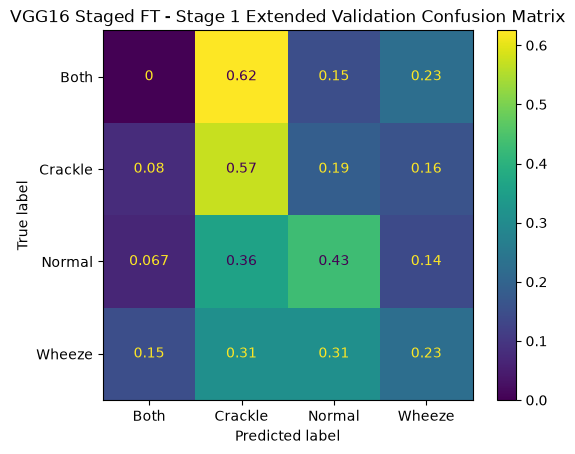

In [173]:
vgg16_stage1_ext.eval()

vgg16_stage1_ext_preds = []
vgg16_stage1_ext_labels = []

with torch.no_grad():

    for x, y in val_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = vgg16_stage1_ext(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        vgg16_stage1_ext_preds.extend(
            preds.cpu().numpy()
        )

        vgg16_stage1_ext_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        vgg16_stage1_ext_labels,
        vgg16_stage1_ext_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

ConfusionMatrixDisplay.from_predictions(
    vgg16_stage1_ext_labels,
    vgg16_stage1_ext_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "VGG16 Staged FT - Stage 1 Extended Validation Confusion Matrix"
)

plt.show()

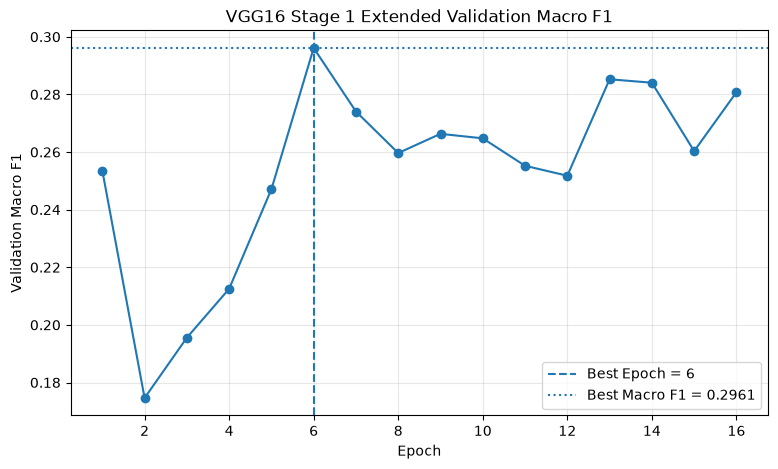

In [174]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_stage1_ext_history["epoch"],
    vgg16_stage1_ext_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.axhline(
    y=0.2961,
    linestyle=":",
    label="Best Macro F1 = 0.2961"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1")
plt.title(
    "VGG16 Stage 1 Extended Validation Macro F1"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

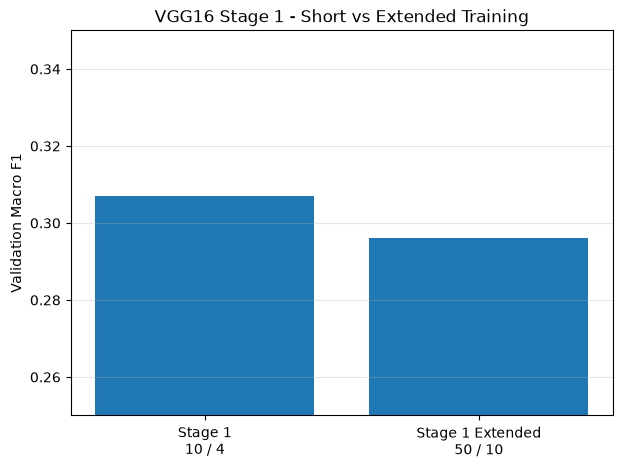

In [175]:
vgg16_stage1_compare = pd.DataFrame({
    "Experiment": [
        "Stage 1\n10 / 4",
        "Stage 1 Extended\n50 / 10"
    ],
    "Macro_F1": [
        0.3070,
        0.2961
    ]
})

plt.figure(figsize=(7, 5))

plt.bar(
    vgg16_stage1_compare["Experiment"],
    vgg16_stage1_compare["Macro_F1"]
)

plt.ylabel("Validation Macro F1")
plt.title(
    "VGG16 Stage 1 - Short vs Extended Training"
)

plt.ylim(0.25, 0.35)
plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

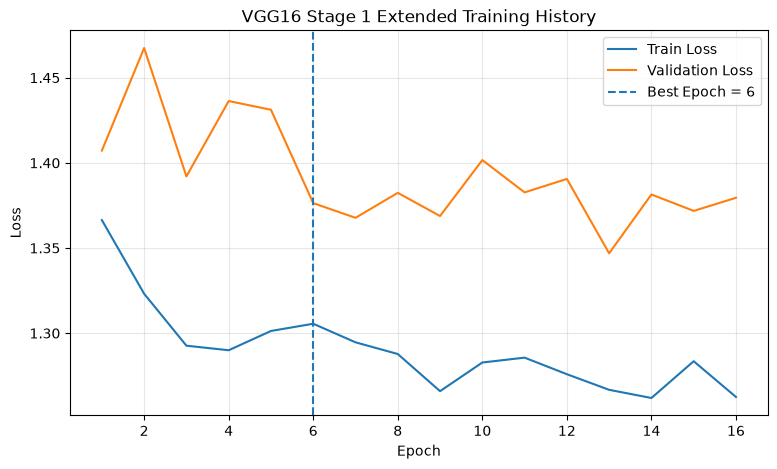

In [177]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg16_stage1_ext_history["epoch"],
    vgg16_stage1_ext_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    vgg16_stage1_ext_history["epoch"],
    vgg16_stage1_ext_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=6,
    linestyle="--",
    label="Best Epoch = 6"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "VGG16 Stage 1 Extended Training History"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [178]:
import pandas as pd

trackB_final_validation = pd.DataFrame([
    # =========================================================
    # 1. Initial CNN Screening
    # =========================================================
    {
        "Phase": "Initial Screening",
        "Model": "LeNet-5",
        "Strategy": "Baseline",
        "Best_Epoch": 6,
        "Accuracy": 0.3523,
        "Balanced_Accuracy": 0.3123,
        "Macro_F1": 0.2916,
        "Both_Recall": 0.225,
        "Crackle_Recall": 0.420,
        "Normal_Recall": 0.356,
        "Wheeze_Recall": 0.248,
        "Role": "Screening"
    },
    {
        "Phase": "Initial Screening",
        "Model": "AlexNet",
        "Strategy": "Full FT / Fixed LR",
        "Best_Epoch": 9,
        "Accuracy": 0.5662,
        "Balanced_Accuracy": 0.4736,
        "Macro_F1": 0.4562,
        "Both_Recall": 0.100,
        "Crackle_Recall": 0.601,
        "Normal_Recall": 0.604,
        "Wheeze_Recall": 0.589,
        "Role": "Candidate"
    },
    {
        "Phase": "Initial Screening",
        "Model": "VGG16",
        "Strategy": "Full Fine-Tuning",
        "Best_Epoch": 15,
        "Accuracy": 0.5933,
        "Balanced_Accuracy": 0.4501,
        "Macro_F1": 0.4531,
        "Both_Recall": 0.075,
        "Crackle_Recall": 0.458,
        "Normal_Recall": 0.764,
        "Wheeze_Recall": 0.504,
        "Role": "Candidate"
    },
    {
        "Phase": "Initial Screening",
        "Model": "VGG19",
        "Strategy": "Full Fine-Tuning",
        "Best_Epoch": 10,
        "Accuracy": 0.5372,
        "Balanced_Accuracy": 0.4352,
        "Macro_F1": 0.4191,
        "Both_Recall": 0.062,
        "Crackle_Recall": 0.551,
        "Normal_Recall": 0.596,
        "Wheeze_Recall": 0.532,
        "Role": "Screening"
    },
    {
        "Phase": "Initial Screening",
        "Model": "ResNet50",
        "Strategy": "Full Fine-Tuning",
        "Best_Epoch": 14,
        "Accuracy": 0.5793,
        "Balanced_Accuracy": 0.4491,
        "Macro_F1": 0.4568,
        "Both_Recall": 0.100,
        "Crackle_Recall": 0.551,
        "Normal_Recall": 0.692,
        "Wheeze_Recall": 0.454,
        "Role": "Candidate"
    },
    {
        "Phase": "Initial Screening",
        "Model": "ResNet152",
        "Strategy": "Full Fine-Tuning",
        "Best_Epoch": 17,
        "Accuracy": 0.5583,
        "Balanced_Accuracy": 0.4255,
        "Macro_F1": 0.4372,
        "Both_Recall": 0.150,
        "Crackle_Recall": 0.476,
        "Normal_Recall": 0.707,
        "Wheeze_Recall": 0.369,
        "Role": "Screening"
    },

    # =========================================================
    # 2. AlexNet Ablation
    # =========================================================
    {
        "Phase": "AlexNet Ablation",
        "Model": "AlexNet 2A",
        "Strategy": "SpecAug + Scheduler",
        "Best_Epoch": 17,
        "Accuracy": 0.5355,
        "Balanced_Accuracy": 0.4478,
        "Macro_F1": 0.4412,
        "Both_Recall": 0.275,
        "Crackle_Recall": 0.613,
        "Normal_Recall": 0.577,
        "Wheeze_Recall": 0.326,
        "Role": "Ablation"
    },
    {
        "Phase": "AlexNet Ablation",
        "Model": "AlexNet 2B",
        "Strategy": "Scheduler Only",
        "Best_Epoch": 10,
        "Accuracy": 0.5434,
        "Balanced_Accuracy": 0.4204,
        "Macro_F1": 0.4150,
        "Both_Recall": 0.275,
        "Crackle_Recall": 0.622,
        "Normal_Recall": 0.628,
        "Wheeze_Recall": 0.156,
        "Role": "Ablation"
    },
    {
        "Phase": "AlexNet Ablation",
        "Model": "AlexNet 2C",
        "Strategy": "SpecAug Only",
        "Best_Epoch": 15,
        "Accuracy": 0.5066,
        "Balanced_Accuracy": 0.4326,
        "Macro_F1": 0.4236,
        "Both_Recall": 0.263,
        "Crackle_Recall": 0.577,
        "Normal_Recall": 0.536,
        "Wheeze_Recall": 0.355,
        "Role": "Ablation"
    },

    # =========================================================
    # 3. VGG16 Staged Fine-Tuning
    # =========================================================
    {
        "Phase": "VGG16 Staged FT",
        "Model": "VGG16 Stage 1",
        "Strategy": "Head Only / 10-4",
        "Best_Epoch": 6,
        "Accuracy": 0.3672,
        "Balanced_Accuracy": 0.3381,
        "Macro_F1": 0.3070,
        "Both_Recall": 0.163,
        "Crackle_Recall": 0.557,
        "Normal_Recall": 0.293,
        "Wheeze_Recall": 0.340,
        "Role": "Diagnostic"
    },
    {
        "Phase": "VGG16 Staged FT",
        "Model": "VGG16 Stage 1 Extended",
        "Strategy": "Head Only / 50-10",
        "Best_Epoch": 6,
        "Accuracy": 0.4172,
        "Balanced_Accuracy": 0.3075,
        "Macro_F1": 0.2961,
        "Both_Recall": 0.000,
        "Crackle_Recall": 0.571,
        "Normal_Recall": 0.432,
        "Wheeze_Recall": 0.227,
        "Role": "Diagnostic"
    },
    {
        "Phase": "VGG16 Staged FT",
        "Model": "VGG16 Stage 2",
        "Strategy": "Last Conv Block + Head",
        "Best_Epoch": 13,
        "Accuracy": 0.5162,
        "Balanced_Accuracy": 0.4012,
        "Macro_F1": 0.3938,
        "Both_Recall": 0.075,
        "Crackle_Recall": 0.732,
        "Normal_Recall": 0.507,
        "Wheeze_Recall": 0.291,
        "Role": "Diagnostic"
    },

    # =========================================================
    # 4. ResNet50 Staged Fine-Tuning
    # =========================================================
    {
        "Phase": "ResNet50 Staged FT",
        "Model": "ResNet50 Stage 1 Pilot",
        "Strategy": "FC Only / 10-4",
        "Best_Epoch": 6,
        "Accuracy": 0.4040,
        "Balanced_Accuracy": 0.3326,
        "Macro_F1": 0.3198,
        "Both_Recall": 0.163,
        "Crackle_Recall": 0.488,
        "Normal_Recall": 0.425,
        "Wheeze_Recall": 0.255,
        "Role": "Pilot"
    },
    {
        "Phase": "ResNet50 Staged FT",
        "Model": "ResNet50 Stage 1 Extended",
        "Strategy": "FC Only / 50-10",
        "Best_Epoch": 15,
        "Accuracy": 0.4277,
        "Balanced_Accuracy": 0.3489,
        "Macro_F1": 0.3332,
        "Both_Recall": 0.163,
        "Crackle_Recall": 0.634,
        "Normal_Recall": 0.401,
        "Wheeze_Recall": 0.199,
        "Role": "Diagnostic"
    },
    {
        "Phase": "ResNet50 Staged FT",
        "Model": "ResNet50 Stage 2",
        "Strategy": "Layer4 + FC / WD=1e-4",
        "Best_Epoch": 20,
        "Accuracy": 0.4926,
        "Balanced_Accuracy": 0.3539,
        "Macro_F1": 0.3582,
        "Both_Recall": 0.138,
        "Crackle_Recall": 0.509,
        "Normal_Recall": 0.613,
        "Wheeze_Recall": 0.156,
        "Role": "Diagnostic"
    },
    {
        "Phase": "ResNet50 Staged FT",
        "Model": "ResNet50 Stage 2B",
        "Strategy": "Layer4 + FC / WD=1e-3",
        "Best_Epoch": 19,
        "Accuracy": 0.4803,
        "Balanced_Accuracy": 0.3617,
        "Macro_F1": 0.3643,
        "Both_Recall": 0.138,
        "Crackle_Recall": 0.500,
        "Normal_Recall": 0.575,
        "Wheeze_Recall": 0.234,
        "Role": "Diagnostic"
    }
])

trackB_final_validation

,Phase,Model,Strategy,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall,Role
0,Initial Screening,LeNet-5,Baseline,6,0.3523,0.3123,0.2916,0.225,0.420,0.356,0.248,Screening
1,Initial Screening,AlexNet,Full FT / Fixed LR,9,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589,Candidate
2,Initial Screening,VGG16,Full Fine-Tuning,15,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504,Candidate
3,Initial Screening,VGG19,Full Fine-Tuning,10,0.5372,0.4352,0.4191,0.062,0.551,0.596,0.532,Screening
4,Initial Screening,ResNet50,Full Fine-Tuning,14,0.5793,0.4491,0.4568,0.100,0.551,0.692,0.454,Candidate
5,Initial Screening,ResNet152,Full Fine-Tuning,17,0.5583,0.4255,0.4372,0.150,0.476,0.707,0.369,Screening
6,AlexNet Ablation,AlexNet 2A,SpecAug + Scheduler,17,0.5355,0.4478,0.4412,0.275,0.613,0.577,0.326,Ablation
7,AlexNet Ablation,AlexNet 2B,Scheduler Only,10,0.5434,0.4204,0.4150,0.275,0.622,0.628,0.156,Ablation
8,AlexNet Ablation,AlexNet 2C,SpecAug Only,15,0.5066,0.4326,0.4236,0.263,0.577,0.536,0.355,Ablation
9,VGG16 Staged FT,VGG16 Stage 1,Head Only / 10-4,6,0.3672,0.3381,0.3070,0.163,0.557,0.293,0.340,Diagnostic


In [179]:
trackB_final_validation_sorted = (
    trackB_final_validation
    .sort_values(
        by="Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

trackB_final_validation_sorted

,Phase,Model,Strategy,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall,Role
0,Initial Screening,ResNet50,Full Fine-Tuning,14,0.5793,0.4491,0.4568,0.100,0.551,0.692,0.454,Candidate
1,Initial Screening,AlexNet,Full FT / Fixed LR,9,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589,Candidate
2,Initial Screening,VGG16,Full Fine-Tuning,15,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504,Candidate
3,AlexNet Ablation,AlexNet 2A,SpecAug + Scheduler,17,0.5355,0.4478,0.4412,0.275,0.613,0.577,0.326,Ablation
4,Initial Screening,ResNet152,Full Fine-Tuning,17,0.5583,0.4255,0.4372,0.150,0.476,0.707,0.369,Screening
5,AlexNet Ablation,AlexNet 2C,SpecAug Only,15,0.5066,0.4326,0.4236,0.263,0.577,0.536,0.355,Ablation
6,Initial Screening,VGG19,Full Fine-Tuning,10,0.5372,0.4352,0.4191,0.062,0.551,0.596,0.532,Screening
7,AlexNet Ablation,AlexNet 2B,Scheduler Only,10,0.5434,0.4204,0.4150,0.275,0.622,0.628,0.156,Ablation
8,VGG16 Staged FT,VGG16 Stage 2,Last Conv Block + Head,13,0.5162,0.4012,0.3938,0.075,0.732,0.507,0.291,Diagnostic
9,ResNet50 Staged FT,ResNet50 Stage 2B,Layer4 + FC / WD=1e-3,19,0.4803,0.3617,0.3643,0.138,0.500,0.575,0.234,Diagnostic


In [180]:
trackB_candidate_models = (
    trackB_final_validation[
        trackB_final_validation["Role"] == "Candidate"
    ]
    .sort_values(
        by="Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

trackB_candidate_models

,Phase,Model,Strategy,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall,Role
0,Initial Screening,ResNet50,Full Fine-Tuning,14,0.5793,0.4491,0.4568,0.100,0.551,0.692,0.454,Candidate
1,Initial Screening,AlexNet,Full FT / Fixed LR,9,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589,Candidate
2,Initial Screening,VGG16,Full Fine-Tuning,15,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504,Candidate


In [181]:
candidate_metric_table = trackB_candidate_models[
    [
        "Model",
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "Both_Recall",
        "Crackle_Recall",
        "Normal_Recall",
        "Wheeze_Recall"
    ]
].copy()

candidate_metric_table

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,ResNet50,0.5793,0.4491,0.4568,0.100,0.551,0.692,0.454
1,AlexNet,0.5662,0.4736,0.4562,0.100,0.601,0.604,0.589
2,VGG16,0.5933,0.4501,0.4531,0.075,0.458,0.764,0.504


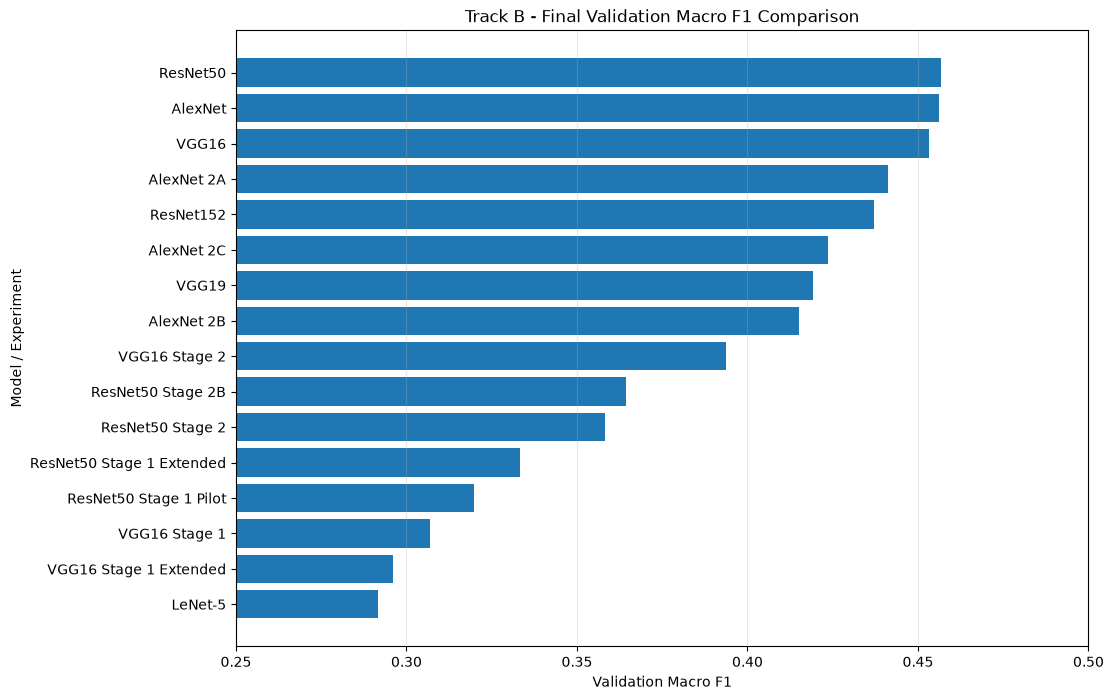

In [182]:
import matplotlib.pyplot as plt

plot_df = (
    trackB_final_validation_sorted
    .sort_values("Macro_F1")
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_df["Model"],
    plot_df["Macro_F1"]
)

plt.xlabel("Validation Macro F1")
plt.ylabel("Model / Experiment")

plt.title(
    "Track B - Final Validation Macro F1 Comparison"
)

plt.xlim(0.25, 0.50)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.show()

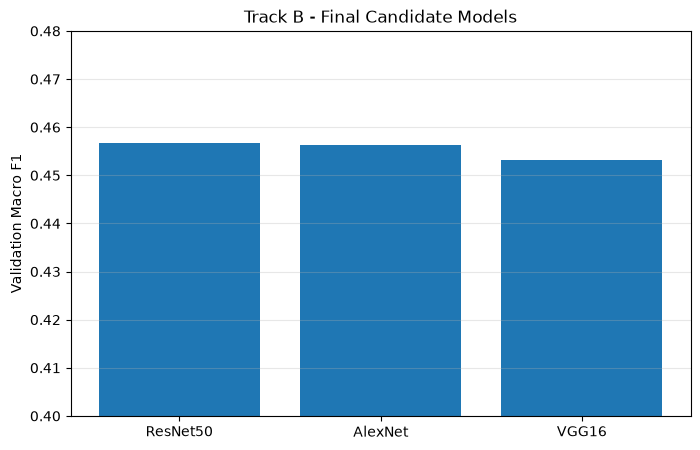

In [183]:
plt.figure(figsize=(8, 5))

plt.bar(
    trackB_candidate_models["Model"],
    trackB_candidate_models["Macro_F1"]
)

plt.ylabel("Validation Macro F1")

plt.title(
    "Track B - Final Candidate Models"
)

plt.ylim(0.40, 0.48)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [184]:
from pathlib import Path

results_dir = Path(
    r"D:\2026\final_project\results\trackB"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_csv_path = (
    results_dir
    / "TrackB_Final_Validation_Comparison_seed777.csv"
)

trackB_final_validation_sorted.to_csv(
    final_csv_path,
    index=False,
    encoding="utf-8-sig"
)

candidate_csv_path = (
    results_dir
    / "TrackB_Final_Candidates_seed777.csv"
)

trackB_candidate_models.to_csv(
    candidate_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(final_csv_path)
print(candidate_csv_path)

Saved:
D:\2026\final_project\results\trackB\TrackB_Final_Validation_Comparison_seed777.csv
D:\2026\final_project\results\trackB\TrackB_Final_Candidates_seed777.csv


In [185]:
candidate_analysis = trackB_candidate_models.copy()

# 이상 호흡음 3개 클래스 평균 Recall
candidate_analysis["Abnormal_Recall_Mean"] = (
    candidate_analysis[
        [
            "Both_Recall",
            "Crackle_Recall",
            "Wheeze_Recall"
        ]
    ]
    .mean(axis=1)
)

# 가장 취약한 클래스의 Recall
candidate_analysis["Min_Class_Recall"] = (
    candidate_analysis[
        [
            "Both_Recall",
            "Crackle_Recall",
            "Normal_Recall",
            "Wheeze_Recall"
        ]
    ]
    .min(axis=1)
)

candidate_analysis[
    [
        "Model",
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "Abnormal_Recall_Mean",
        "Min_Class_Recall",
        "Both_Recall",
        "Crackle_Recall",
        "Normal_Recall",
        "Wheeze_Recall"
    ]
]

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Abnormal_Recall_Mean,Min_Class_Recall,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,ResNet50,0.5793,0.4491,0.4568,0.368333,0.100,0.100,0.551,0.692,0.454
1,AlexNet,0.5662,0.4736,0.4562,0.430000,0.100,0.100,0.601,0.604,0.589
2,VGG16,0.5933,0.4501,0.4531,0.345667,0.075,0.075,0.458,0.764,0.504


In [186]:
from torchvision import models
import torch.nn as nn

# AlexNet
alexnet_temp = models.alexnet(
    weights=None
)

alexnet_temp.classifier[6] = nn.Linear(
    alexnet_temp.classifier[6].in_features,
    4
)

# VGG16
vgg16_temp = models.vgg16(
    weights=None
)

vgg16_temp.classifier[6] = nn.Linear(
    vgg16_temp.classifier[6].in_features,
    4
)

# ResNet50
resnet50_temp = models.resnet50(
    weights=None
)

resnet50_temp.fc = nn.Linear(
    resnet50_temp.fc.in_features,
    4
)

complexity_table = pd.DataFrame([
    {
        "Model": "AlexNet",
        "Parameters": sum(
            p.numel() for p in alexnet_temp.parameters()
        )
    },
    {
        "Model": "VGG16",
        "Parameters": sum(
            p.numel() for p in vgg16_temp.parameters()
        )
    },
    {
        "Model": "ResNet50",
        "Parameters": sum(
            p.numel() for p in resnet50_temp.parameters()
        )
    }
])

complexity_table["Parameters_M"] = (
    complexity_table["Parameters"] / 1_000_000
)

complexity_table

,Model,Parameters,Parameters_M
0,AlexNet,57020228,57.020228
1,VGG16,134276932,134.276932
2,ResNet50,23516228,23.516228


In [187]:
candidate_final_review = candidate_analysis.merge(
    complexity_table[
        ["Model", "Parameters_M"]
    ],
    on="Model",
    how="left"
)

candidate_final_review[
    [
        "Model",
        "Parameters_M",
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "Abnormal_Recall_Mean",
        "Min_Class_Recall"
    ]
]

,Model,Parameters_M,Accuracy,Balanced_Accuracy,Macro_F1,Abnormal_Recall_Mean,Min_Class_Recall
0,ResNet50,23.516228,0.5793,0.4491,0.4568,0.368333,0.100
1,AlexNet,57.020228,0.5662,0.4736,0.4562,0.430000,0.100
2,VGG16,134.276932,0.5933,0.4501,0.4531,0.345667,0.075


In [188]:
candidate_analysis = trackB_candidate_models.copy()

# 이상 호흡음(Both, Crackle, Wheeze) 평균 Recall
candidate_analysis["Abnormal_Recall_Mean"] = (
    candidate_analysis[
        ["Both_Recall", "Crackle_Recall", "Wheeze_Recall"]
    ].mean(axis=1)
)

# 4개 클래스 중 가장 낮은 Recall
candidate_analysis["Min_Class_Recall"] = (
    candidate_analysis[
        [
            "Both_Recall",
            "Crackle_Recall",
            "Normal_Recall",
            "Wheeze_Recall"
        ]
    ].min(axis=1)
)

candidate_analysis[
    [
        "Model",
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "Abnormal_Recall_Mean",
        "Min_Class_Recall",
        "Both_Recall",
        "Crackle_Recall",
        "Normal_Recall",
        "Wheeze_Recall"
    ]
]

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Abnormal_Recall_Mean,Min_Class_Recall,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,ResNet50,0.5793,0.4491,0.4568,0.368333,0.100,0.100,0.551,0.692,0.454
1,AlexNet,0.5662,0.4736,0.4562,0.430000,0.100,0.100,0.601,0.604,0.589
2,VGG16,0.5933,0.4501,0.4531,0.345667,0.075,0.075,0.458,0.764,0.504


In [189]:
from torchvision import models
import torch.nn as nn
import pandas as pd

# AlexNet
alexnet_temp = models.alexnet(weights=None)
alexnet_temp.classifier[6] = nn.Linear(
    alexnet_temp.classifier[6].in_features,
    4
)

# VGG16
vgg16_temp = models.vgg16(weights=None)
vgg16_temp.classifier[6] = nn.Linear(
    vgg16_temp.classifier[6].in_features,
    4
)

# ResNet50
resnet50_temp = models.resnet50(weights=None)
resnet50_temp.fc = nn.Linear(
    resnet50_temp.fc.in_features,
    4
)

complexity_table = pd.DataFrame([
    {
        "Model": "AlexNet",
        "Parameters": sum(
            p.numel() for p in alexnet_temp.parameters()
        )
    },
    {
        "Model": "VGG16",
        "Parameters": sum(
            p.numel() for p in vgg16_temp.parameters()
        )
    },
    {
        "Model": "ResNet50",
        "Parameters": sum(
            p.numel() for p in resnet50_temp.parameters()
        )
    }
])

complexity_table["Parameters_M"] = (
    complexity_table["Parameters"] / 1_000_000
)

complexity_table

,Model,Parameters,Parameters_M
0,AlexNet,57020228,57.020228
1,VGG16,134276932,134.276932
2,ResNet50,23516228,23.516228


In [190]:
candidate_final_review = candidate_analysis.merge(
    complexity_table[
        ["Model", "Parameters_M"]
    ],
    on="Model",
    how="left"
)

candidate_final_review = candidate_final_review[
    [
        "Model",
        "Parameters_M",
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "Abnormal_Recall_Mean",
        "Min_Class_Recall",
        "Both_Recall",
        "Crackle_Recall",
        "Normal_Recall",
        "Wheeze_Recall"
    ]
]

candidate_final_review

,Model,Parameters_M,Accuracy,Balanced_Accuracy,Macro_F1,Abnormal_Recall_Mean,Min_Class_Recall,Both_Recall,Crackle_Recall,Normal_Recall,Wheeze_Recall
0,ResNet50,23.516228,0.5793,0.4491,0.4568,0.368333,0.100,0.100,0.551,0.692,0.454
1,AlexNet,57.020228,0.5662,0.4736,0.4562,0.430000,0.100,0.100,0.601,0.604,0.589
2,VGG16,134.276932,0.5933,0.4501,0.4531,0.345667,0.075,0.075,0.458,0.764,0.504


In [191]:
from pathlib import Path

results_dir = Path(
    r"D:\2026\final_project\results\trackB"
)

review_path = (
    results_dir
    / "TrackB_Final_Candidate_Review_seed777.csv"
)

candidate_final_review.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", review_path)

Saved: D:\2026\final_project\results\trackB\TrackB_Final_Candidate_Review_seed777.csv


In [192]:
from pathlib import Path
import pandas as pd

results_dir = Path(
    r"D:\2026\final_project\results\trackB"
)

selection_record = pd.DataFrame([{
    "Selected_Model": "AlexNet Base",
    "Selection_Data": "Validation set only",
    "Primary_Metric": "Macro F1",
    "Validation_Accuracy": 0.5662,
    "Validation_Balanced_Accuracy": 0.4736,
    "Validation_Macro_F1": 0.4562,
    "Both_Recall": 0.100,
    "Crackle_Recall": 0.601,
    "Normal_Recall": 0.604,
    "Wheeze_Recall": 0.589,
    "Abnormal_Recall_Mean": 0.4300,
    "Selection_Rationale": (
        "Macro F1 was essentially tied with ResNet50 "
        "(0.4562 vs 0.4568), while AlexNet showed the "
        "highest balanced accuracy and abnormal-class "
        "mean recall among the final candidates."
    ),
    "Test_Set_Used_For_Selection": False
}])

selection_path = (
    results_dir
    / "TrackB_Final_Model_Selection_seed777.csv"
)

selection_record.to_csv(
    selection_path,
    index=False,
    encoding="utf-8-sig"
)

selection_record
print("\nSaved:", selection_path)


Saved: D:\2026\final_project\results\trackB\TrackB_Final_Model_Selection_seed777.csv


In [193]:
selection_txt = results_dir / "TrackB_Final_Model_Selection_NOTE.txt"

note = """
Track B Final Model Selection
=============================

Selected model: AlexNet Base

Selection was performed using the validation set only.

Validation results:
- Accuracy: 0.5662
- Balanced Accuracy: 0.4736
- Macro F1: 0.4562
- Both Recall: 0.100
- Crackle Recall: 0.601
- Normal Recall: 0.604
- Wheeze Recall: 0.589
- Abnormal Recall Mean: 0.4300

Rationale:
ResNet50 achieved a slightly higher Macro F1
(0.4568 vs 0.4562), but the difference was only 0.0006.

AlexNet showed:
- the highest Balanced Accuracy,
- the highest mean recall across abnormal sound classes,
- relatively strong recall for both Crackle and Wheeze.

Therefore, AlexNet Base was selected as the final Track B
model before opening the independent test set.

The test set was NOT used for model selection.
"""

selection_txt.write_text(
    note.strip(),
    encoding="utf-8"
)

print("Saved:", selection_txt)

Saved: D:\2026\final_project\results\trackB\TrackB_Final_Model_Selection_NOTE.txt


In [194]:
[
    name
    for name in globals().keys()
    if "alex" in name.lower()
]

['alexnet_model',
 'x_alex',
 'alex_logits',
 'alexnet_optimizer',
 'alexnet_history',
 'alexnet_val_metrics',
 'alex_preds',
 'alex_labels',
 'alexnet_v2',
 'alexnet_v2_optimizer',
 'alexnet_v2_scheduler',
 'alexnet_v2_history',
 'alexnet_v2_val_metrics',
 'alexnet_v2_preds',
 'alexnet_v2_labels',
 'alexnet_v2b',
 'alexnet_v2b_optimizer',
 'alexnet_v2b_scheduler',
 'alexnet_v2b_history',
 'alexnet_v2c',
 'alexnet_v2c_optimizer',
 'alexnet_v2c_history',
 'alexnet_v2b_val_metrics',
 'alexnet_v2b_preds',
 'alexnet_v2b_labels',
 'alexnet_v2c_val_metrics',
 'alexnet_v2c_preds',
 'alexnet_v2c_labels',
 'alexnet_temp']

In [195]:
alexnet_base_check = evaluate_model(
    alexnet_model,
    val_loader,
    prepare_pretrained_input
)

print("===== AlexNet Base Identity Check =====")

for key, value in alexnet_base_check.items():
    print(f"{key:20s}: {value:.4f}")

===== AlexNet Base Identity Check =====
loss                : 1.3219
accuracy            : 0.5662
balanced_accuracy   : 0.4736
macro_f1            : 0.4562


In [196]:
from pathlib import Path
import torch

checkpoint_dir = Path(
    r"D:\2026\final_project\results\trackB\checkpoints"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

alexnet_final_ckpt = (
    checkpoint_dir
    / "AlexNet_Base_Final_Selected_seed777.pth"
)

torch.save(
    alexnet_model.state_dict(),
    alexnet_final_ckpt
)

print("Saved:", alexnet_final_ckpt)

Saved: D:\2026\final_project\results\trackB\checkpoints\AlexNet_Base_Final_Selected_seed777.pth


In [197]:
# ============================================================
# 1. Final selected AlexNet Base identity check
# ============================================================

alexnet_base_check = evaluate_model(
    alexnet_model,
    val_loader,
    prepare_pretrained_input
)

print("===== AlexNet Base Identity Check =====")

for key, value in alexnet_base_check.items():
    print(f"{key:20s}: {value:.4f}")

expected_val_macro_f1 = 0.4562

if abs(
    alexnet_base_check["macro_f1"]
    - expected_val_macro_f1
) < 0.001:

    print("\n[OK] AlexNet Base checkpoint confirmed.")

else:

    raise RuntimeError(
        "AlexNet Base validation result does not match "
        "the expected checkpoint. Stop before Test evaluation."
    )

===== AlexNet Base Identity Check =====
loss                : 1.3219
accuracy            : 0.5662
balanced_accuracy   : 0.4736
macro_f1            : 0.4562

[OK] AlexNet Base checkpoint confirmed.


In [198]:
# ============================================================
# 2. Save final selected AlexNet checkpoint
# ============================================================

from pathlib import Path
import torch

checkpoint_dir = Path(
    r"D:\2026\final_project\results\trackB\checkpoints"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

alexnet_final_ckpt = (
    checkpoint_dir
    / "AlexNet_Base_Final_Selected_seed777.pth"
)

torch.save(
    alexnet_model.state_dict(),
    alexnet_final_ckpt
)

print("Saved:", alexnet_final_ckpt)

Saved: D:\2026\final_project\results\trackB\checkpoints\AlexNet_Base_Final_Selected_seed777.pth


In [199]:
# ============================================================
# 3. Independent Test Evaluation
# ============================================================

alexnet_test_metrics = evaluate_model(
    alexnet_model,
    test_loader,
    prepare_pretrained_input
)

print("===== AlexNet Final Independent Test Result =====")

for key, value in alexnet_test_metrics.items():
    print(f"{key:20s}: {value:.4f}")

===== AlexNet Final Independent Test Result =====
loss                : 1.6017
accuracy            : 0.5275
balanced_accuracy   : 0.4598
macro_f1            : 0.4247


In [200]:
# ============================================================
# 4. Classification Report + Predictions
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

alexnet_model.eval()

alexnet_test_preds = []
alexnet_test_labels = []

with torch.no_grad():

    for x, y in test_loader:

        x = prepare_pretrained_input(x).to(device)

        logits = alexnet_model(x)

        preds = torch.argmax(
            logits,
            dim=1
        )

        alexnet_test_preds.extend(
            preds.cpu().numpy()
        )

        alexnet_test_labels.extend(
            y.numpy()
        )

print(
    classification_report(
        alexnet_test_labels,
        alexnet_test_preds,
        target_names=CLASS_NAMES,
        digits=3
    )
)

alexnet_test_weighted_f1 = f1_score(
    alexnet_test_labels,
    alexnet_test_preds,
    average="weighted"
)

print(
    "Test Weighted F1:",
    round(alexnet_test_weighted_f1, 4)
)

              precision    recall  f1-score   support

        Both      0.108     0.052     0.070        77
     Crackle      0.629     0.524     0.572       269
      Normal      0.664     0.540     0.596       513
      Wheeze      0.338     0.723     0.461       159

    accuracy                          0.528      1018
   macro avg      0.435     0.460     0.425      1018
weighted avg      0.562     0.528     0.529      1018

Test Weighted F1: 0.5286


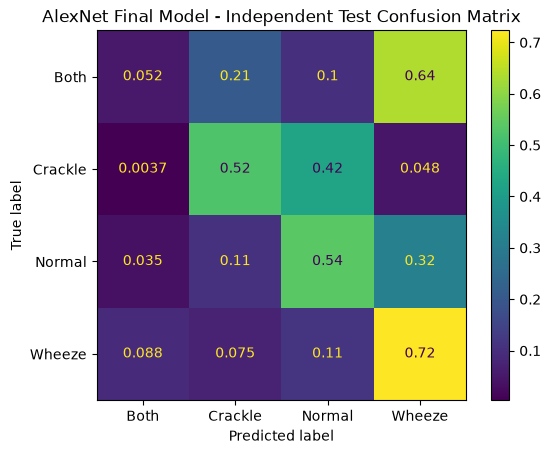

In [201]:
# ============================================================
# 5. Test Confusion Matrix
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    alexnet_test_labels,
    alexnet_test_preds,
    display_labels=CLASS_NAMES,
    normalize="true"
)

plt.title(
    "AlexNet Final Model - Independent Test Confusion Matrix"
)

plt.show()

In [202]:
# ============================================================
# 6. Validation vs Test Comparison
# ============================================================

import pandas as pd

alexnet_val_test_compare = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Accuracy": 0.5662,
        "Balanced_Accuracy": 0.4736,
        "Macro_F1": 0.4562
    },
    {
        "Dataset": "Independent Test",
        "Accuracy": alexnet_test_metrics["accuracy"],
        "Balanced_Accuracy": alexnet_test_metrics["balanced_accuracy"],
        "Macro_F1": alexnet_test_metrics["macro_f1"]
    }
])

alexnet_val_test_compare["Macro_F1_Difference_from_Validation"] = (
    alexnet_val_test_compare["Macro_F1"] - 0.4562
)

alexnet_val_test_compare

,Dataset,Accuracy,Balanced_Accuracy,Macro_F1,Macro_F1_Difference_from_Validation
0,Validation,0.566200,0.473600,0.456200,0.000000
1,Independent Test,0.527505,0.459836,0.424701,-0.031499


In [203]:
# ============================================================
# 7. Save final Test results
# ============================================================

results_dir = Path(
    r"D:\2026\final_project\results\trackB"
)

test_summary_path = (
    results_dir
    / "AlexNet_Final_Independent_Test_seed777.csv"
)

test_summary = pd.DataFrame([{
    "Model": "AlexNet Base",
    "Split": "Independent Test",
    "N": len(alexnet_test_labels),
    "Accuracy": alexnet_test_metrics["accuracy"],
    "Balanced_Accuracy": alexnet_test_metrics["balanced_accuracy"],
    "Macro_F1": alexnet_test_metrics["macro_f1"],
    "Weighted_F1": alexnet_test_weighted_f1
}])

test_summary.to_csv(
    test_summary_path,
    index=False,
    encoding="utf-8-sig"
)

comparison_path = (
    results_dir
    / "AlexNet_Validation_vs_Test_seed777.csv"
)

alexnet_val_test_compare.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(test_summary_path)
print(comparison_path)

Saved:
D:\2026\final_project\results\trackB\AlexNet_Final_Independent_Test_seed777.csv
D:\2026\final_project\results\trackB\AlexNet_Validation_vs_Test_seed777.csv


In [204]:
print(alexnet_model)

print("\n===== Grad-CAM Target Layer =====")
print(alexnet_model.features[10])

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [205]:
from torch.utils.data import Dataset, DataLoader

class IndexedDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]

        return x, y, idx

In [206]:
indexed_test_dataset = IndexedDataset(test_dataset)

indexed_test_loader = DataLoader(
    indexed_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Indexed Test samples:", len(indexed_test_dataset))

Indexed Test samples: 1018


In [207]:
import pandas as pd
import torch

alexnet_model.eval()

gradcam_records = []

with torch.no_grad():

    for x, y, idx in indexed_test_loader:

        x_input = prepare_pretrained_input(x).to(device)

        logits = alexnet_model(x_input)

        probs = torch.softmax(
            logits,
            dim=1
        )

        preds = torch.argmax(
            probs,
            dim=1
        )

        confidence = probs.max(
            dim=1
        ).values

        for i in range(len(y)):

            true_idx = int(y[i])
            pred_idx = int(preds[i].cpu())

            gradcam_records.append({
                "dataset_index": int(idx[i]),
                "true_idx": true_idx,
                "true_class": CLASS_NAMES[true_idx],
                "pred_idx": pred_idx,
                "pred_class": CLASS_NAMES[pred_idx],
                "confidence": float(
                    confidence[i].cpu()
                ),
                "correct": true_idx == pred_idx
            })

gradcam_cases = pd.DataFrame(
    gradcam_records
)

gradcam_cases.head()

,dataset_index,true_idx,true_class,pred_idx,pred_class,confidence,correct
0,0,1,Crackle,2,Normal,0.533806,False
1,1,1,Crackle,2,Normal,0.529710,False
2,2,1,Crackle,2,Normal,0.590131,False
3,3,1,Crackle,1,Crackle,0.472755,True
4,4,1,Crackle,1,Crackle,0.660586,True


In [208]:
print("Total samples :", len(gradcam_cases))
print(
    "Correct       :",
    gradcam_cases["correct"].sum()
)
print(
    "Incorrect     :",
    (~gradcam_cases["correct"]).sum()
)
print(
    "Accuracy      :",
    gradcam_cases["correct"].mean()
)

Total samples : 1018
Correct       : 537
Incorrect     : 481
Accuracy      : 0.5275049115913556


In [209]:
gradcam_case_summary = pd.crosstab(
    gradcam_cases["true_class"],
    gradcam_cases["correct"]
)

gradcam_case_summary.columns = [
    "Incorrect",
    "Correct"
]

gradcam_case_summary

,Incorrect,Correct
true_class,,
Both,73,4
Crackle,128,141
Normal,236,277
Wheeze,44,115


In [210]:
both_to_wheeze = (
    gradcam_cases[
        (gradcam_cases["true_class"] == "Both")
        &
        (gradcam_cases["pred_class"] == "Wheeze")
    ]
    .sort_values(
        "confidence",
        ascending=False
    )
)

both_to_wheeze.head(10)

,dataset_index,true_idx,true_class,pred_idx,pred_class,confidence,correct
1004,1004,0,Both,3,Wheeze,0.999660,False
956,956,0,Both,3,Wheeze,0.999605,False
248,248,0,Both,3,Wheeze,0.998994,False
958,958,0,Both,3,Wheeze,0.998973,False
1006,1006,0,Both,3,Wheeze,0.998503,False
969,969,0,Both,3,Wheeze,0.996029,False
1012,1012,0,Both,3,Wheeze,0.993449,False
1007,1007,0,Both,3,Wheeze,0.991774,False
984,984,0,Both,3,Wheeze,0.987443,False
1010,1010,0,Both,3,Wheeze,0.980851,False


In [211]:
high_conf_correct = (
    gradcam_cases[
        gradcam_cases["correct"]
    ]
    .sort_values(
        ["true_class", "confidence"],
        ascending=[True, False]
    )
    .groupby(
        "true_class",
        as_index=False
    )
    .head(3)
)

high_conf_correct[
    [
        "dataset_index",
        "true_class",
        "pred_class",
        "confidence"
    ]
]

,dataset_index,true_class,pred_class,confidence
45,45,Both,Both,0.782349
213,213,Both,Both,0.768612
159,159,Both,Both,0.640060
131,131,Crackle,Crackle,0.920510
22,22,Crackle,Crackle,0.918405
20,20,Crackle,Crackle,0.908750
711,711,Normal,Normal,0.944450
781,781,Normal,Normal,0.943270
918,918,Normal,Normal,0.927810
998,998,Wheeze,Wheeze,0.999871


In [212]:
import torch
import torch.nn.functional as F
import numpy as np


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._forward_hook
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._backward_hook
        )

    def _forward_hook(self, module, input, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, target_class=None):

        self.model.eval()
        self.model.zero_grad()

        output = self.model(input_tensor)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        score = output[:, target_class]

        score.backward()

        # Channel별 gradient 평균
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted combination
        cam = (
            weights * self.activations
        ).sum(dim=1, keepdim=True)

        # ReLU
        cam = F.relu(cam)

        # 입력 크기로 확대
        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze().cpu().numpy()

        # 0~1 normalization
        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max > cam_min:
            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        return cam, output.detach()

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

In [213]:
target_layer = alexnet_model.features[10]

gradcam = GradCAM(
    model=alexnet_model,
    target_layer=target_layer
)

print(target_layer)

Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [214]:
sample_idx = 998

x, y = test_dataset[sample_idx]

print("Dataset index :", sample_idx)
print("True class    :", CLASS_NAMES[int(y)])
print("Original shape:", x.shape)

Dataset index : 998
True class    : Wheeze
Original shape: torch.Size([1, 128, 126])


In [215]:
x_batch = x.unsqueeze(0)

x_input = prepare_pretrained_input(
    x_batch
).to(device)

cam, output = gradcam.generate(
    input_tensor=x_input
)

prob = torch.softmax(
    output,
    dim=1
)

pred_idx = int(
    prob.argmax(dim=1).item()
)

confidence = float(
    prob[0, pred_idx].item()
)

print("True class :", CLASS_NAMES[int(y)])
print("Pred class :", CLASS_NAMES[pred_idx])
print("Confidence :", round(confidence, 4))
print("CAM shape  :", cam.shape)
print(
    "CAM range  :",
    round(float(cam.min()), 4),
    "~",
    round(float(cam.max()), 4)
)

RuntimeError: Output 0 of BackwardHookFunctionBackward is a view and is being modified inplace. This view was created inside a custom Function (or because an input was returned as-is) and the autograd logic to handle view+inplace would override the custom backward associated with the custom Function, leading to incorrect gradients. This behavior is forbidden. You can fix this by cloning the output of the custom Function.

In [216]:
try:
    gradcam.remove_hooks()
    print("Old Grad-CAM hooks removed.")
except:
    print("No previous hooks to remove.")

Old Grad-CAM hooks removed.


In [217]:
import torch.nn as nn

for module in alexnet_model.modules():
    if isinstance(module, nn.ReLU):
        module.inplace = False

print("All AlexNet ReLU layers set to inplace=False.")

All AlexNet ReLU layers set to inplace=False.


In [218]:
print(alexnet_model.features[11])

ReLU()


In [219]:
class GradCAM:
    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )

    def _save_gradient(self, grad):
        self.gradients = grad.detach()

    def _forward_hook(self, module, inputs, output):

        self.activations = output.detach()

        # 해당 activation tensor의 gradient를 직접 저장
        if output.requires_grad:
            output.register_hook(
                self._save_gradient
            )

    def generate(
        self,
        input_tensor,
        target_class=None
    ):

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if target_class is None:
            target_class = int(
                output.argmax(dim=1).item()
            )

        score = output[
            0,
            target_class
        ]

        score.backward()

        if self.activations is None:
            raise RuntimeError(
                "Grad-CAM activations were not captured."
            )

        if self.gradients is None:
            raise RuntimeError(
                "Grad-CAM gradients were not captured."
            )

        # 각 channel gradient의 spatial mean
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * self.activations
        ).sum(
            dim=1,
            keepdim=True
        )

        cam = torch.relu(cam)

        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[
            0,
            0
        ].detach().cpu().numpy()

        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max > cam_min:
            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        return cam, output.detach()

    def remove_hooks(self):
        self.forward_handle.remove()

In [220]:
target_layer = alexnet_model.features[10]

gradcam = GradCAM(
    model=alexnet_model,
    target_layer=target_layer
)

print("Target layer:")
print(target_layer)

Target layer:
Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [221]:
sample_idx = 998

x, y = test_dataset[sample_idx]

x_batch = x.unsqueeze(0)

x_input = prepare_pretrained_input(
    x_batch
).to(device)

cam, output = gradcam.generate(
    input_tensor=x_input
)

prob = torch.softmax(
    output,
    dim=1
)

pred_idx = int(
    prob.argmax(dim=1).item()
)

confidence = float(
    prob[0, pred_idx].item()
)

print("Dataset index :", sample_idx)
print("True class    :", CLASS_NAMES[int(y)])
print("Pred class    :", CLASS_NAMES[pred_idx])
print("Confidence    :", round(confidence, 4))
print("CAM shape     :", cam.shape)
print(
    "CAM range     :",
    round(float(cam.min()), 4),
    "~",
    round(float(cam.max()), 4)
)

Dataset index : 998
True class    : Wheeze
Pred class    : Wheeze
Confidence    : 0.9999
CAM shape     : (224, 224)
CAM range     : 0.0 ~ 1.0


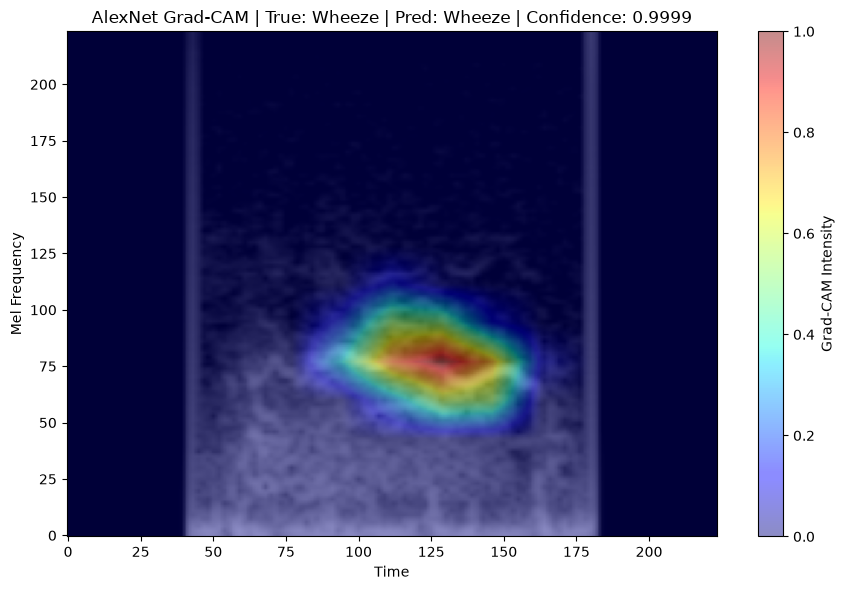

In [222]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

# 원본 Mel을 224x224로 확대
mel_224 = F.interpolate(
    x.unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze().cpu().numpy()

plt.figure(figsize=(9, 6))

# 배경: Mel-Spectrogram
plt.imshow(
    mel_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

# Grad-CAM overlay
plt.imshow(
    cam,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

plt.colorbar(
    label="Grad-CAM Intensity"
)

plt.title(
    f"AlexNet Grad-CAM | "
    f"True: {CLASS_NAMES[int(y)]} | "
    f"Pred: {CLASS_NAMES[pred_idx]} | "
    f"Confidence: {confidence:.4f}"
)

plt.xlabel("Time")
plt.ylabel("Mel Frequency")

plt.tight_layout()
plt.show()

In [223]:
# ============================================================
# Grad-CAM: Both -> Wheeze high-confidence misclassification
# ============================================================

sample_idx = 1004

x_both, y_both = test_dataset[sample_idx]

x_both_batch = x_both.unsqueeze(0)

x_both_input = prepare_pretrained_input(
    x_both_batch
).to(device)

cam_both, output_both = gradcam.generate(
    input_tensor=x_both_input
)

prob_both = torch.softmax(
    output_both,
    dim=1
)

pred_idx_both = int(
    prob_both.argmax(dim=1).item()
)

confidence_both = float(
    prob_both[0, pred_idx_both].item()
)

print("Dataset index :", sample_idx)
print("True class    :", CLASS_NAMES[int(y_both)])
print("Pred class    :", CLASS_NAMES[pred_idx_both])
print("Confidence    :", round(confidence_both, 4))
print("CAM shape     :", cam_both.shape)
print(
    "CAM range     :",
    round(float(cam_both.min()), 4),
    "~",
    round(float(cam_both.max()), 4)
)

Dataset index : 1004
True class    : Both
Pred class    : Wheeze
Confidence    : 0.9997
CAM shape     : (224, 224)
CAM range     : 0.0 ~ 1.0


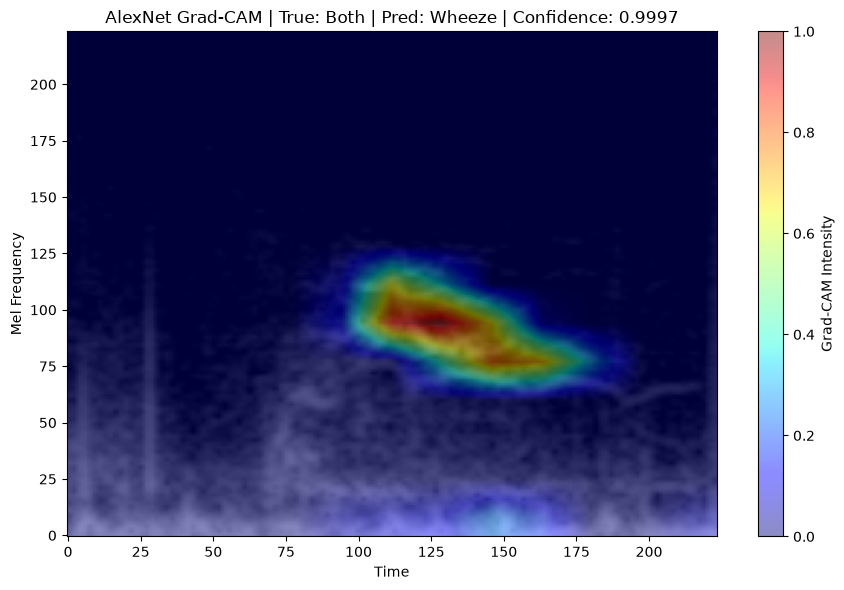

In [224]:
mel_both_224 = F.interpolate(
    x_both.unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze().cpu().numpy()

plt.figure(figsize=(9, 6))

plt.imshow(
    mel_both_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

plt.imshow(
    cam_both,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

plt.colorbar(
    label="Grad-CAM Intensity"
)

plt.title(
    f"AlexNet Grad-CAM | "
    f"True: {CLASS_NAMES[int(y_both)]} | "
    f"Pred: {CLASS_NAMES[pred_idx_both]} | "
    f"Confidence: {confidence_both:.4f}"
)

plt.xlabel("Time")
plt.ylabel("Mel Frequency")

plt.tight_layout()
plt.show()

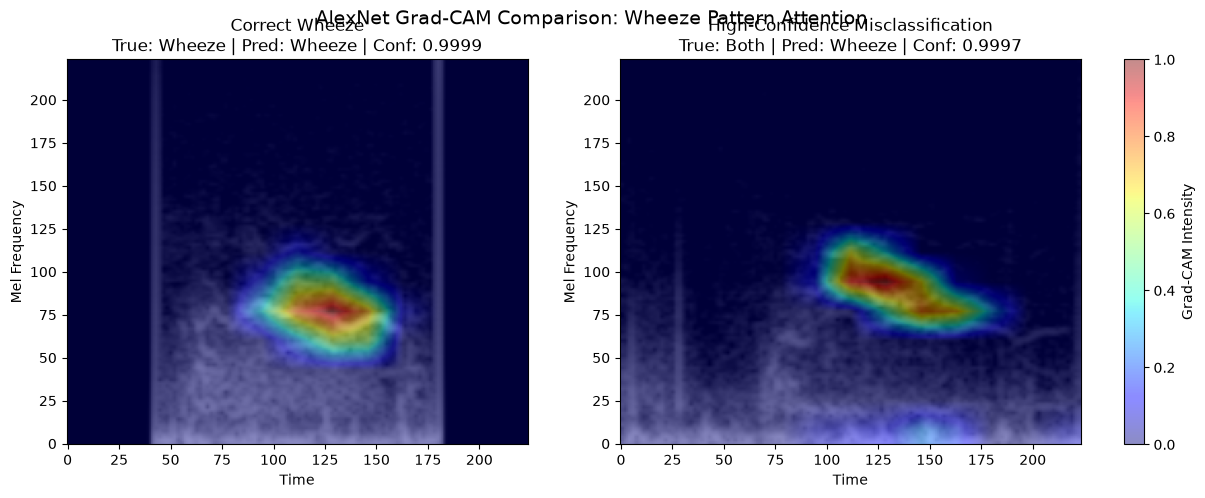

In [225]:
# ============================================================
# Grad-CAM comparison:
# Correct Wheeze vs Both -> Wheeze misclassification
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# 1. Correct Wheeze
# ------------------------------------------------------------
axes[0].imshow(
    mel_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

axes[0].imshow(
    cam,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[0].set_title(
    f"Correct Wheeze\n"
    f"True: Wheeze | Pred: Wheeze | "
    f"Conf: {confidence:.4f}"
)

axes[0].set_xlabel("Time")
axes[0].set_ylabel("Mel Frequency")


# ------------------------------------------------------------
# 2. Both -> Wheeze
# ------------------------------------------------------------
im = axes[1].imshow(
    mel_both_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

heat = axes[1].imshow(
    cam_both,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[1].set_title(
    f"High-Confidence Misclassification\n"
    f"True: Both | Pred: Wheeze | "
    f"Conf: {confidence_both:.4f}"
)

axes[1].set_xlabel("Time")
axes[1].set_ylabel("Mel Frequency")


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
fig.colorbar(
    heat,
    ax=axes,
    label="Grad-CAM Intensity",
    fraction=0.025,
    pad=0.04
)

fig.suptitle(
    "AlexNet Grad-CAM Comparison: Wheeze Pattern Attention",
    fontsize=14
)

plt.show()

In [226]:
from pathlib import Path

gradcam_dir = Path(
    r"D:\2026\final_project\results\trackB\gradcam"
)

gradcam_dir.mkdir(
    parents=True,
    exist_ok=True
)

save_path = (
    gradcam_dir
    / "GradCAM_Wheeze_correct_vs_Both_to_Wheeze.png"
)

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", save_path)

Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Wheeze_correct_vs_Both_to_Wheeze.png


In [227]:
# ============================================================
# 1. Correct Crackle case
# ============================================================

crackle_correct_idx = 131

x_crackle, y_crackle = test_dataset[crackle_correct_idx]

x_crackle_input = prepare_pretrained_input(
    x_crackle.unsqueeze(0)
).to(device)

cam_crackle, output_crackle = gradcam.generate(
    input_tensor=x_crackle_input
)

prob_crackle = torch.softmax(
    output_crackle,
    dim=1
)

pred_idx_crackle = int(
    prob_crackle.argmax(dim=1).item()
)

confidence_crackle = float(
    prob_crackle[0, pred_idx_crackle].item()
)

print("Dataset index :", crackle_correct_idx)
print("True class    :", CLASS_NAMES[int(y_crackle)])
print("Pred class    :", CLASS_NAMES[pred_idx_crackle])
print("Confidence    :", round(confidence_crackle, 4))

Dataset index : 131
True class    : Crackle
Pred class    : Crackle
Confidence    : 0.9205


In [228]:
mel_crackle_224 = F.interpolate(
    x_crackle.unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze().cpu().numpy()

In [229]:
# ============================================================
# 2. Find a high-confidence Crackle -> Normal case
# ============================================================

crackle_to_normal = (
    gradcam_cases[
        (gradcam_cases["true_class"] == "Crackle")
        &
        (gradcam_cases["pred_class"] == "Normal")
    ]
    .sort_values(
        "confidence",
        ascending=False
    )
)

crackle_to_normal.head(10)

,dataset_index,true_idx,true_class,pred_idx,pred_class,confidence,correct
911,911,1,Crackle,2,Normal,0.920604,False
907,907,1,Crackle,2,Normal,0.874408,False
588,588,1,Crackle,2,Normal,0.872991,False
55,55,1,Crackle,2,Normal,0.857079,False
784,784,1,Crackle,2,Normal,0.849932,False
909,909,1,Crackle,2,Normal,0.843595,False
783,783,1,Crackle,2,Normal,0.840485,False
901,901,1,Crackle,2,Normal,0.835180,False
585,585,1,Crackle,2,Normal,0.828650,False
941,941,1,Crackle,2,Normal,0.827690,False


In [230]:
crackle_mis_idx = int(
    crackle_to_normal.iloc[0]["dataset_index"]
)

print("Selected Crackle -> Normal index:", crackle_mis_idx)

Selected Crackle -> Normal index: 911


In [231]:
x_crackle_mis, y_crackle_mis = test_dataset[crackle_mis_idx]

x_crackle_mis_input = prepare_pretrained_input(
    x_crackle_mis.unsqueeze(0)
).to(device)

cam_crackle_mis, output_crackle_mis = gradcam.generate(
    input_tensor=x_crackle_mis_input
)

prob_crackle_mis = torch.softmax(
    output_crackle_mis,
    dim=1
)

pred_idx_crackle_mis = int(
    prob_crackle_mis.argmax(dim=1).item()
)

confidence_crackle_mis = float(
    prob_crackle_mis[0, pred_idx_crackle_mis].item()
)

print("Dataset index :", crackle_mis_idx)
print("True class    :", CLASS_NAMES[int(y_crackle_mis)])
print("Pred class    :", CLASS_NAMES[pred_idx_crackle_mis])
print("Confidence    :", round(confidence_crackle_mis, 4))

Dataset index : 911
True class    : Crackle
Pred class    : Normal
Confidence    : 0.9206


In [232]:
mel_crackle_mis_224 = F.interpolate(
    x_crackle_mis.unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze().cpu().numpy()

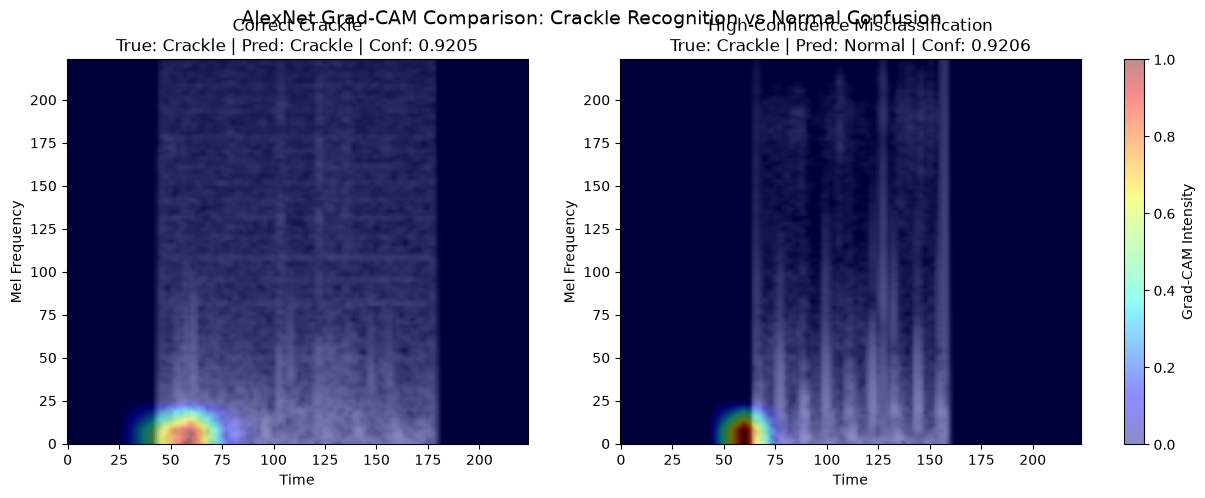

In [233]:
# ============================================================
# 3. Crackle Grad-CAM comparison
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Correct Crackle
axes[0].imshow(
    mel_crackle_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

axes[0].imshow(
    cam_crackle,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[0].set_title(
    f"Correct Crackle\n"
    f"True: Crackle | Pred: Crackle | "
    f"Conf: {confidence_crackle:.4f}"
)

axes[0].set_xlabel("Time")
axes[0].set_ylabel("Mel Frequency")


# Crackle -> Normal
heat = axes[1].imshow(
    mel_crackle_mis_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

heat = axes[1].imshow(
    cam_crackle_mis,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[1].set_title(
    f"High-Confidence Misclassification\n"
    f"True: Crackle | Pred: Normal | "
    f"Conf: {confidence_crackle_mis:.4f}"
)

axes[1].set_xlabel("Time")
axes[1].set_ylabel("Mel Frequency")


fig.colorbar(
    heat,
    ax=axes,
    label="Grad-CAM Intensity",
    fraction=0.025,
    pad=0.04
)

fig.suptitle(
    "AlexNet Grad-CAM Comparison: Crackle Recognition vs Normal Confusion",
    fontsize=14
)

plt.show()

In [234]:
save_path = (
    gradcam_dir
    / "GradCAM_Crackle_correct_vs_Crackle_to_Normal.png"
)

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", save_path)

Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Crackle_correct_vs_Crackle_to_Normal.png


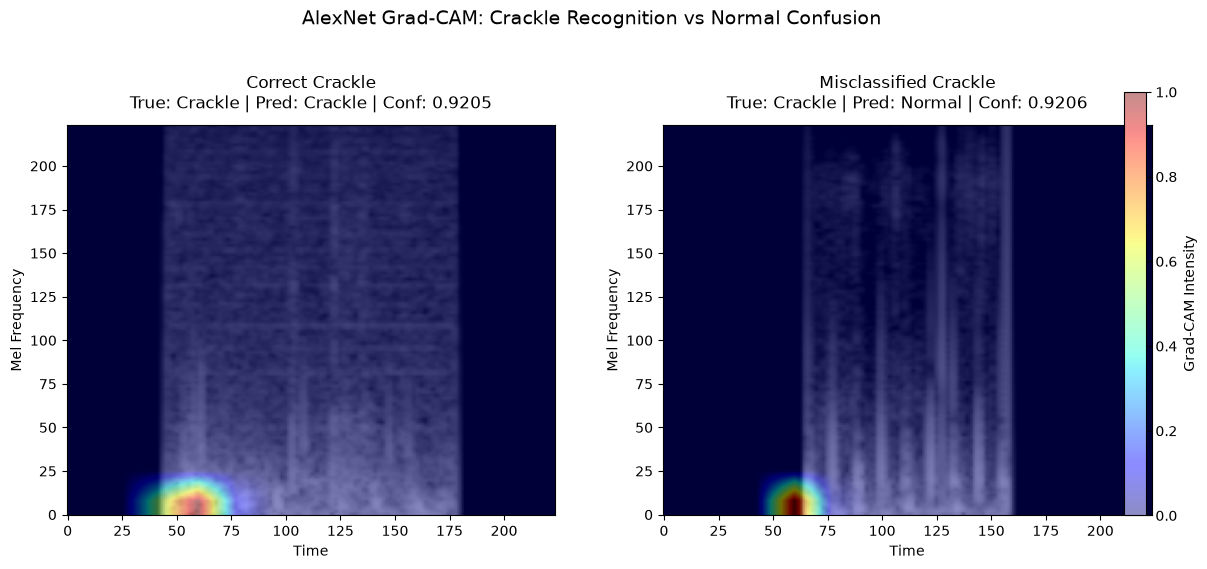

In [235]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.5)
)

# Correct Crackle
axes[0].imshow(
    mel_crackle_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

axes[0].imshow(
    cam_crackle,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[0].set_title(
    f"Correct Crackle\n"
    f"True: Crackle | Pred: Crackle | "
    f"Conf: {confidence_crackle:.4f}",
    pad=12
)

axes[0].set_xlabel("Time")
axes[0].set_ylabel("Mel Frequency")


# Crackle -> Normal
heat = axes[1].imshow(
    mel_crackle_mis_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

heat = axes[1].imshow(
    cam_crackle_mis,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[1].set_title(
    f"Misclassified Crackle\n"
    f"True: Crackle | Pred: Normal | "
    f"Conf: {confidence_crackle_mis:.4f}",
    pad=12
)

axes[1].set_xlabel("Time")
axes[1].set_ylabel("Mel Frequency")

fig.colorbar(
    heat,
    ax=axes,
    label="Grad-CAM Intensity",
    fraction=0.025,
    pad=0.04
)

fig.suptitle(
    "AlexNet Grad-CAM: Crackle Recognition vs Normal Confusion",
    fontsize=14,
    y=1.03
)

plt.subplots_adjust(
    top=0.82,
    wspace=0.22
)

plt.show()

In [236]:
save_path = (
    gradcam_dir
    / "GradCAM_Crackle_correct_vs_Crackle_to_Normal.png"
)

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", save_path)

Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Crackle_correct_vs_Crackle_to_Normal.png


In [237]:
import pandas as pd
from pathlib import Path

gradcam_summary = pd.DataFrame([
    {
        "Case": "Correct Wheeze",
        "Dataset_Index": 998,
        "True_Class": "Wheeze",
        "Pred_Class": "Wheeze",
        "Confidence": 0.9999,
        "Result": "Correct",
        "Key_Observation": (
            "Attention concentrated on a localized "
            "mid-frequency region within the valid signal."
        ),
        "Interpretation": (
            "The model used a relatively focused "
            "time-frequency pattern when correctly identifying Wheeze."
        )
    },
    {
        "Case": "Both -> Wheeze",
        "Dataset_Index": 1004,
        "True_Class": "Both",
        "Pred_Class": "Wheeze",
        "Confidence": 0.9997,
        "Result": "Misclassified",
        "Key_Observation": (
            "Strong localized attention appeared in a "
            "time-frequency region resembling the attention "
            "pattern observed in the correct Wheeze case."
        ),
        "Interpretation": (
            "The model may have responded strongly to "
            "Wheeze-related discriminative cues while failing "
            "to sufficiently incorporate additional cues needed "
            "to distinguish the combined Both class."
        )
    },
    {
        "Case": "Correct Crackle",
        "Dataset_Index": 131,
        "True_Class": "Crackle",
        "Pred_Class": "Crackle",
        "Confidence": 0.9205,
        "Result": "Correct",
        "Key_Observation": (
            "Attention was concentrated on a short, localized "
            "low-frequency region early in the respiratory cycle."
        ),
        "Interpretation": (
            "The model relied on a localized temporal-spectral "
            "pattern when correctly identifying Crackle."
        )
    },
    {
        "Case": "Crackle -> Normal",
        "Dataset_Index": 911,
        "True_Class": "Crackle",
        "Pred_Class": "Normal",
        "Confidence": 0.9206,
        "Result": "Misclassified",
        "Key_Observation": (
            "Attention was also localized in the early "
            "low-frequency region but appeared more restricted "
            "and did not cover broader signal characteristics."
        ),
        "Interpretation": (
            "The model may have failed to capture sufficient "
            "additional evidence for Crackle, resulting in "
            "a high-confidence Normal prediction."
        )
    }
])

gradcam_summary

,Case,Dataset_Index,True_Class,Pred_Class,Confidence,Result,Key_Observation,Interpretation
0,Correct Wheeze,998,Wheeze,Wheeze,0.9999,Correct,Attention concentrated on a localized mid-freq...,The model used a relatively focused time-frequ...
1,Both -> Wheeze,1004,Both,Wheeze,0.9997,Misclassified,Strong localized attention appeared in a time-...,The model may have responded strongly to Wheez...
2,Correct Crackle,131,Crackle,Crackle,0.9205,Correct,"Attention was concentrated on a short, localiz...",The model relied on a localized temporal-spect...
3,Crackle -> Normal,911,Crackle,Normal,0.9206,Misclassified,Attention was also localized in the early low-...,The model may have failed to capture sufficien...


In [238]:
gradcam_dir = Path(
    r"D:\2026\final_project\results\trackB\gradcam"
)

gradcam_dir.mkdir(
    parents=True,
    exist_ok=True
)

summary_path = (
    gradcam_dir
    / "GradCAM_Core_Case_Summary_seed777.csv"
)

gradcam_summary.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", summary_path)

Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Core_Case_Summary_seed777.csv


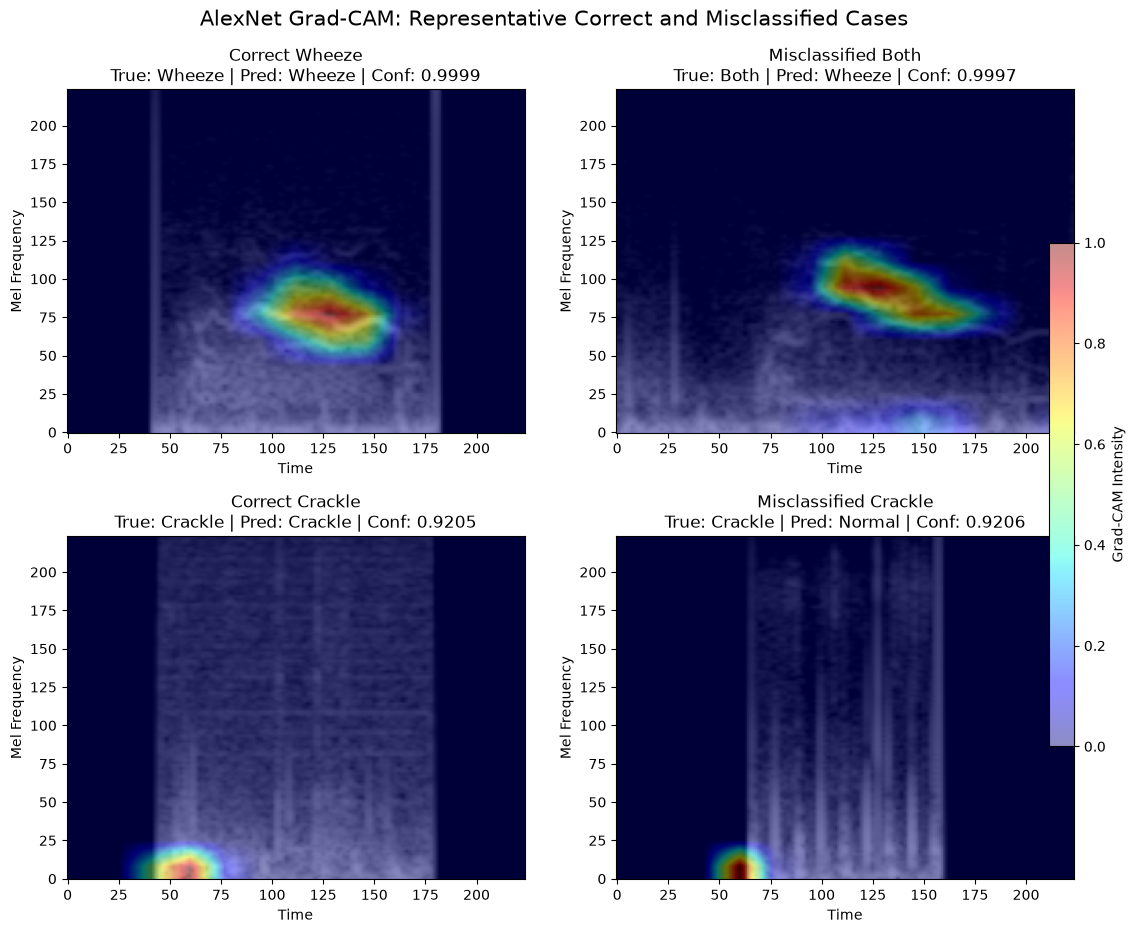

In [239]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10)
)

# 1. Correct Wheeze
axes[0, 0].imshow(
    mel_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

axes[0, 0].imshow(
    cam,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[0, 0].set_title(
    "Correct Wheeze\n"
    "True: Wheeze | Pred: Wheeze | Conf: 0.9999"
)

# 2. Both -> Wheeze
axes[0, 1].imshow(
    mel_both_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

axes[0, 1].imshow(
    cam_both,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[0, 1].set_title(
    "Misclassified Both\n"
    "True: Both | Pred: Wheeze | Conf: 0.9997"
)

# 3. Correct Crackle
axes[1, 0].imshow(
    mel_crackle_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

axes[1, 0].imshow(
    cam_crackle,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[1, 0].set_title(
    "Correct Crackle\n"
    "True: Crackle | Pred: Crackle | Conf: 0.9205"
)

# 4. Crackle -> Normal
axes[1, 1].imshow(
    mel_crackle_mis_224,
    origin="lower",
    aspect="auto",
    cmap="gray"
)

heat = axes[1, 1].imshow(
    cam_crackle_mis,
    origin="lower",
    aspect="auto",
    cmap="jet",
    alpha=0.45
)

axes[1, 1].set_title(
    "Misclassified Crackle\n"
    "True: Crackle | Pred: Normal | Conf: 0.9206"
)

for ax in axes.flat:
    ax.set_xlabel("Time")
    ax.set_ylabel("Mel Frequency")

fig.colorbar(
    heat,
    ax=axes.ravel().tolist(),
    label="Grad-CAM Intensity",
    fraction=0.025,
    pad=0.03
)

fig.suptitle(
    "AlexNet Grad-CAM: Representative Correct and Misclassified Cases",
    fontsize=15,
    y=0.98
)

plt.subplots_adjust(
    top=0.90,
    hspace=0.30,
    wspace=0.20
)

plt.show()

In [240]:
four_case_path = (
    gradcam_dir
    / "GradCAM_Representative_4_Cases.png"
)

fig.savefig(
    four_case_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", four_case_path)

Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Representative_4_Cases.png


In [241]:
from pathlib import Path
import pandas as pd

gradcam_dir = Path(
    r"D:\2026\final_project\results\trackB\gradcam"
)

gradcam_dir.mkdir(
    parents=True,
    exist_ok=True
)

gradcam_result_summary = pd.DataFrame([
    {
        "Case": "Correct Wheeze",
        "Dataset_Index": 998,
        "True_Class": "Wheeze",
        "Pred_Class": "Wheeze",
        "Confidence": 0.9999,
        "Result": "Correct",
        "Interpretation": (
            "Localized attention within the valid signal region. "
            "No dominant attention on zero-padding boundaries was observed."
        )
    },
    {
        "Case": "Both_to_Wheeze",
        "Dataset_Index": 1004,
        "True_Class": "Both",
        "Pred_Class": "Wheeze",
        "Confidence": 0.9997,
        "Result": "Misclassified",
        "Interpretation": (
            "Attention pattern overlapped with the Wheeze-like region. "
            "The model may have emphasized wheeze-related cues while "
            "underutilizing additional cues required for the Both class."
        )
    },
    {
        "Case": "Correct Crackle",
        "Dataset_Index": 131,
        "True_Class": "Crackle",
        "Pred_Class": "Crackle",
        "Confidence": 0.9205,
        "Result": "Correct",
        "Interpretation": (
            "Attention was concentrated on a short localized "
            "low-frequency time-frequency region."
        )
    },
    {
        "Case": "Crackle_to_Normal",
        "Dataset_Index": 911,
        "True_Class": "Crackle",
        "Pred_Class": "Normal",
        "Confidence": 0.9206,
        "Result": "Misclassified",
        "Interpretation": (
            "The model focused on a restricted region and may not have "
            "captured sufficient additional evidence for Crackle."
        )
    }
])

gradcam_summary_path = (
    gradcam_dir
    / "GradCAM_Core_Analysis_seed777.csv"
)

gradcam_result_summary.to_csv(
    gradcam_summary_path,
    index=False,
    encoding="utf-8-sig"
)

gradcam_result_summary
print("\nSaved:", gradcam_summary_path)


Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Core_Analysis_seed777.csv


In [242]:
four_case_path = (
    gradcam_dir
    / "GradCAM_Representative_4_Cases.png"
)

fig.savefig(
    four_case_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", four_case_path)

Saved: D:\2026\final_project\results\trackB\gradcam\GradCAM_Representative_4_Cases.png


In [8]:
import pandas as pd
import numpy as np

# 예시: 동일 개인의 반복 측정
personal_trend = pd.DataFrame({
    "day": [1, 3, 5, 7, 9],
    "Normal":  [0.82, 0.78, 0.70, 0.58, 0.49],
    "Crackle": [0.08, 0.10, 0.14, 0.20, 0.24],
    "Wheeze":  [0.07, 0.08, 0.11, 0.15, 0.18],
    "Both":    [0.03, 0.04, 0.05, 0.07, 0.09]
})

personal_trend

,day,Normal,Crackle,Wheeze,Both
0,1,0.82,0.08,0.07,0.03
1,3,0.78,0.10,0.08,0.04
2,5,0.70,0.14,0.11,0.05
3,7,0.58,0.20,0.15,0.07
4,9,0.49,0.24,0.18,0.09


In [244]:
personal_trend["prob_sum"] = (
    personal_trend[
        ["Normal", "Crackle", "Wheeze", "Both"]
    ].sum(axis=1)
)

personal_trend

,day,Normal,Crackle,Wheeze,Both,prob_sum
0,1,0.82,0.08,0.07,0.03,1.0
1,3,0.78,0.10,0.08,0.04,1.0
2,5,0.70,0.14,0.11,0.05,1.0
3,7,0.58,0.20,0.15,0.07,1.0
4,9,0.49,0.24,0.18,0.09,1.0


In [9]:
personal_trend["Abnormal_Probability"] = (
    personal_trend["Crackle"]
    + personal_trend["Wheeze"]
    + personal_trend["Both"]
)

personal_trend[
    [
        "day",
        "Normal",
        "Abnormal_Probability"
    ]
]

,day,Normal,Abnormal_Probability
0,1,0.82,0.18
1,3,0.78,0.22
2,5,0.70,0.30
3,7,0.58,0.42
4,9,0.49,0.51


In [10]:
baseline_abnormal = personal_trend.loc[
    0,
    "Abnormal_Probability"
]

print(
    "Personal baseline abnormal probability:",
    round(baseline_abnormal, 4)
)

Personal baseline abnormal probability: 0.18


In [11]:
personal_trend["Change_From_Baseline"] = (
    personal_trend["Abnormal_Probability"]
    - baseline_abnormal
)

personal_trend[
    [
        "day",
        "Abnormal_Probability",
        "Change_From_Baseline"
    ]
]

,day,Abnormal_Probability,Change_From_Baseline
0,1,0.18,0.00
1,3,0.22,0.04
2,5,0.30,0.12
3,7,0.42,0.24
4,9,0.51,0.33


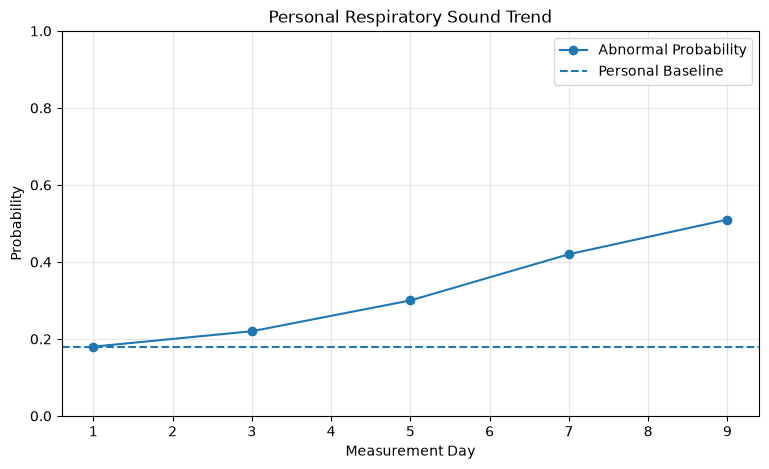

In [248]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    personal_trend["day"],
    personal_trend["Abnormal_Probability"],
    marker="o",
    label="Abnormal Probability"
)

plt.axhline(
    y=baseline_abnormal,
    linestyle="--",
    label="Personal Baseline"
)

plt.xlabel("Measurement Day")
plt.ylabel("Probability")
plt.title(
    "Personal Respiratory Sound Trend"
)

plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    personal_trend["day"],
    personal_trend["Crackle"],
    marker="o",
    label="Crackle"
)

plt.plot(
    personal_trend["day"],
    personal_trend["Wheeze"],
    marker="o",
    label="Wheeze"
)

plt.plot(
    personal_trend["day"],
    personal_trend["Both"],
    marker="o",
    label="Both"
)

plt.xlabel("Measurement Day")
plt.ylabel("Probability")
plt.title(
    "Personal Abnormal Sound Components"
)

plt.ylim(0, 0.4)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

NameError: name 'plt' is not defined

In [250]:
# ============================================================
# Personal baseline = mean of first 3 measurements
# ============================================================

BASELINE_N = 3

baseline_abnormal_mean = (
    personal_trend
    .iloc[:BASELINE_N]["Abnormal_Probability"]
    .mean()
)

print(
    "Baseline abnormal probability "
    f"(first {BASELINE_N} measurements mean):",
    round(baseline_abnormal_mean, 4)
)

Baseline abnormal probability (first 3 measurements mean): 0.2333


In [13]:
personal_trend["Baseline_Abnormal"] = baseline_abnormal_mean

personal_trend["Deviation_From_Baseline"] = (
    personal_trend["Abnormal_Probability"]
    - personal_trend["Baseline_Abnormal"]
)

personal_trend[
    [
        "day",
        "Abnormal_Probability",
        "Baseline_Abnormal",
        "Deviation_From_Baseline"
    ]
]

NameError: name 'baseline_abnormal_mean' is not defined

In [14]:
personal_trend["Abnormal_RollingMean_3"] = (
    personal_trend["Abnormal_Probability"]
    .rolling(window=3)
    .mean()
)

personal_trend[
    [
        "day",
        "Abnormal_Probability",
        "Abnormal_RollingMean_3"
    ]
]

,day,Abnormal_Probability,Abnormal_RollingMean_3
0,1,0.18,NaN
1,3,0.22,NaN
2,5,0.30,0.233333
3,7,0.42,0.313333
4,9,0.51,0.410000


In [15]:
import numpy as np

recent_n = 3

recent_data = personal_trend.tail(recent_n)

recent_slope = np.polyfit(
    recent_data["day"],
    recent_data["Abnormal_Probability"],
    1
)[0]

print(
    "Recent abnormal probability slope:",
    round(recent_slope, 4),
    "per day"
)

Recent abnormal probability slope: 0.0525 per day


In [16]:
if recent_slope > 0:
    trend_direction = "Increasing"

elif recent_slope < 0:
    trend_direction = "Decreasing"

else:
    trend_direction = "Stable"

print("Recent trend direction:", trend_direction)

Recent trend direction: Increasing


NameError: name 'baseline_abnormal_mean' is not defined

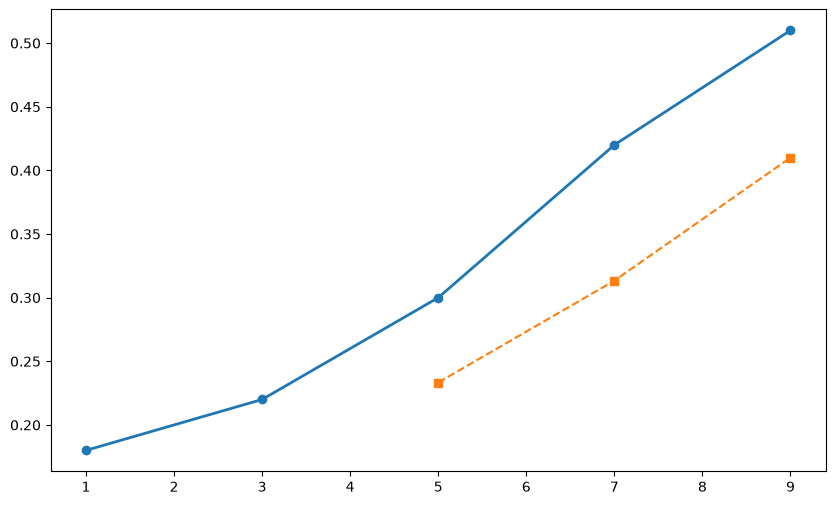

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    personal_trend["day"],
    personal_trend["Abnormal_Probability"],
    marker="o",
    linewidth=2,
    label="Abnormal Probability"
)

plt.plot(
    personal_trend["day"],
    personal_trend["Abnormal_RollingMean_3"],
    marker="s",
    linestyle="--",
    label="3-Measurement Rolling Mean"
)

plt.axhline(
    y=baseline_abnormal_mean,
    linestyle=":",
    linewidth=2,
    label="Personal Baseline (First 3 Mean)"
)

plt.axvspan(
    personal_trend.iloc[0]["day"],
    personal_trend.iloc[BASELINE_N - 1]["day"],
    alpha=0.1,
    label="Baseline Period"
)

plt.xlabel("Measurement Day")
plt.ylabel("Abnormal Probability")

plt.title(
    "Personal Respiratory Sound Change Monitoring"
)

plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
latest = personal_trend.iloc[-1]

personal_monitoring_summary = pd.DataFrame([{
    "Latest_Day": int(latest["day"]),
    "Latest_Abnormal_Probability": latest["Abnormal_Probability"],
    "Personal_Baseline": baseline_abnormal_mean,
    "Deviation_From_Baseline": latest["Deviation_From_Baseline"],
    "RollingMean_3": latest["Abnormal_RollingMean_3"],
    "Recent_Slope_Per_Day": recent_slope,
    "Trend_Direction": trend_direction
}])

personal_monitoring_summary

NameError: name 'baseline_abnormal_mean' is not defined

In [257]:
def predict_respiratory_probabilities(
    model,
    x,
    device
):
    """
    x:
        test_dataset 등에서 얻은
        [1, 128, 126] 형태의 Mel tensor

    return:
        4-class probability dictionary
    """

    model.eval()

    x_batch = x.unsqueeze(0)

    x_input = prepare_pretrained_input(
        x_batch
    ).to(device)

    with torch.no_grad():

        logits = model(x_input)

        probs = torch.softmax(
            logits,
            dim=1
        )[0].cpu().numpy()

    result = {
        CLASS_NAMES[i]: float(probs[i])
        for i in range(len(CLASS_NAMES))
    }

    return result

In [258]:
sample_idx = 998

x_sample, y_sample = test_dataset[sample_idx]

sample_probs = predict_respiratory_probabilities(
    model=alexnet_model,
    x=x_sample,
    device=device
)

print("Dataset index :", sample_idx)
print("True class    :", CLASS_NAMES[int(y_sample)])

sample_probs

Dataset index : 998
True class    : Wheeze


{'Both': 1.2694890472175757e-07,
 'Crackle': 1.1136841067127534e-06,
 'Normal': 0.00012744026025757194,
 'Wheeze': 0.9998713731765747}

In [259]:
print(
    "Probability sum:",
    sum(sample_probs.values())
)

Probability sum: 1.0000000540698437


In [260]:
def create_monitoring_record(
    measurement_id,
    probs
):
    normal_prob = probs["Normal"]

    abnormal_prob = (
        probs["Both"]
        + probs["Crackle"]
        + probs["Wheeze"]
    )

    return {
        "measurement_id": measurement_id,
        "Normal": probs["Normal"],
        "Crackle": probs["Crackle"],
        "Wheeze": probs["Wheeze"],
        "Both": probs["Both"],
        "Abnormal_Probability": abnormal_prob
    }

In [261]:
record_998 = create_monitoring_record(
    measurement_id=998,
    probs=sample_probs
)

pd.DataFrame([record_998])

,measurement_id,Normal,Crackle,Wheeze,Both,Abnormal_Probability
0,998,0.000127,0.000001,0.999871,1.269489e-07,0.999873


In [262]:
demo_indices = [
    711,   # Normal correct
    131,   # Crackle correct
    998,   # Wheeze correct
    1004   # Both -> Wheeze misclassified
]

model_output_records = []

for measurement_no, idx in enumerate(
    demo_indices,
    start=1
):

    x_i, y_i = test_dataset[idx]

    probs_i = predict_respiratory_probabilities(
        model=alexnet_model,
        x=x_i,
        device=device
    )

    record_i = create_monitoring_record(
        measurement_id=measurement_no,
        probs=probs_i
    )

    record_i["dataset_index"] = idx
    record_i["true_class"] = CLASS_NAMES[int(y_i)]

    model_output_records.append(
        record_i
    )

model_output_demo = pd.DataFrame(
    model_output_records
)

model_output_demo

,measurement_id,Normal,Crackle,Wheeze,Both,Abnormal_Probability,dataset_index,true_class
0,1,0.944447,0.053719,0.001826,7.880541e-06,0.055553,711,Normal
1,2,0.072559,0.920523,0.001670,5.247808e-03,0.927441,131,Crackle
2,3,0.000127,0.000001,0.999871,1.269489e-07,0.999873,998,Wheeze
3,4,0.000264,0.000008,0.999660,6.690600e-05,0.999736,1004,Both


In [1]:
import numpy as np
import pandas as pd


class PatientMonitoringEngine:

    def __init__(
        self,
        baseline_n=3,
        rolling_window=3
    ):
        self.baseline_n = baseline_n
        self.rolling_window = rolling_window
        self.records = []

    def add_measurement(
        self,
        measurement_id,
        probs
    ):

        abnormal_prob = (
            probs["Both"]
            + probs["Crackle"]
            + probs["Wheeze"]
        )

        record = {
            "measurement_id": measurement_id,
            "Normal": probs["Normal"],
            "Crackle": probs["Crackle"],
            "Wheeze": probs["Wheeze"],
            "Both": probs["Both"],
            "Abnormal_Probability": abnormal_prob
        }

        self.records.append(record)

    def get_dataframe(self):

        df = pd.DataFrame(self.records)

        if len(df) == 0:
            return df

        # -----------------------------------------
        # Baseline
        # -----------------------------------------
        baseline_count = min(
            self.baseline_n,
            len(df)
        )

        baseline_value = (
            df.iloc[:baseline_count][
                "Abnormal_Probability"
            ].mean()
        )

        df["Personal_Baseline"] = baseline_value

        df["Deviation_From_Baseline"] = (
            df["Abnormal_Probability"]
            - baseline_value
        )

        # -----------------------------------------
        # Rolling mean
        # -----------------------------------------
        df["RollingMean"] = (
            df["Abnormal_Probability"]
            .rolling(
                window=self.rolling_window
            )
            .mean()
        )

        return df

    def get_summary(self):

        df = self.get_dataframe()

        if len(df) == 0:
            return None

        latest = df.iloc[-1]

        # 최근 slope 계산
        recent_n = min(
            self.rolling_window,
            len(df)
        )

        recent = df.tail(recent_n)

        if len(recent) >= 2:

            x = np.arange(
                len(recent)
            )

            slope = np.polyfit(
                x,
                recent["Abnormal_Probability"],
                1
            )[0]

        else:
            slope = 0.0

        if slope > 0:
            direction = "Increasing"

        elif slope < 0:
            direction = "Decreasing"

        else:
            direction = "Stable"

        summary = {
            "Latest_Measurement":
                latest["measurement_id"],

            "Latest_Abnormal_Probability":
                latest["Abnormal_Probability"],

            "Personal_Baseline":
                latest["Personal_Baseline"],

            "Deviation_From_Baseline":
                latest["Deviation_From_Baseline"],

            "RollingMean":
                latest["RollingMean"],

            "Recent_Slope":
                slope,

            "Trend_Direction":
                direction
        }

        return pd.DataFrame(
            [summary]
        )

In [3]:
import pandas as pd

personal_trend = pd.DataFrame({
    "day": [1, 3, 5, 7, 9],
    "Normal":  [0.82, 0.78, 0.70, 0.58, 0.49],
    "Crackle": [0.08, 0.10, 0.14, 0.20, 0.24],
    "Wheeze":  [0.07, 0.08, 0.11, 0.15, 0.18],
    "Both":    [0.03, 0.04, 0.05, 0.07, 0.09]
})

personal_trend

,day,Normal,Crackle,Wheeze,Both
0,1,0.82,0.08,0.07,0.03
1,3,0.78,0.10,0.08,0.04
2,5,0.70,0.14,0.11,0.05
3,7,0.58,0.20,0.15,0.07
4,9,0.49,0.24,0.18,0.09


In [4]:
engine = PatientMonitoringEngine(
    baseline_n=3,
    rolling_window=3
)

for _, row in personal_trend.iterrows():

    probs = {
        "Normal": row["Normal"],
        "Crackle": row["Crackle"],
        "Wheeze": row["Wheeze"],
        "Both": row["Both"]
    }

    engine.add_measurement(
        measurement_id=int(row["day"]),
        probs=probs
    )

In [5]:
monitoring_df = engine.get_dataframe()
monitoring_df

,measurement_id,Normal,Crackle,Wheeze,Both,Abnormal_Probability,Personal_Baseline,Deviation_From_Baseline,RollingMean
0,1,0.82,0.08,0.07,0.03,0.18,0.233333,-0.053333,NaN
1,3,0.78,0.10,0.08,0.04,0.22,0.233333,-0.013333,NaN
2,5,0.70,0.14,0.11,0.05,0.30,0.233333,0.066667,0.233333
3,7,0.58,0.20,0.15,0.07,0.42,0.233333,0.186667,0.313333
4,9,0.49,0.24,0.18,0.09,0.51,0.233333,0.276667,0.410000


In [6]:
monitoring_summary = engine.get_summary()
monitoring_summary

,Latest_Measurement,Latest_Abnormal_Probability,Personal_Baseline,Deviation_From_Baseline,RollingMean,Recent_Slope,Trend_Direction
0,9.0,0.51,0.233333,0.276667,0.41,0.105,Increasing


In [19]:
if len(recent) >= 2:

    x = recent["measurement_id"].to_numpy()

    slope = np.polyfit(
        x,
        recent["Abnormal_Probability"],
        1
    )[0]

else:
    slope = 0.0

NameError: name 'recent' is not defined

In [20]:
import numpy as np
import pandas as pd

In [21]:
class PatientMonitoringEngine:

    def __init__(
        self,
        baseline_n=3,
        rolling_window=3
    ):
        self.baseline_n = baseline_n
        self.rolling_window = rolling_window
        self.records = []

    def add_measurement(
        self,
        measurement_id,
        probs
    ):

        abnormal_prob = (
            probs["Both"]
            + probs["Crackle"]
            + probs["Wheeze"]
        )

        record = {
            "measurement_id": measurement_id,
            "Normal": probs["Normal"],
            "Crackle": probs["Crackle"],
            "Wheeze": probs["Wheeze"],
            "Both": probs["Both"],
            "Abnormal_Probability": abnormal_prob
        }

        self.records.append(record)

    def get_dataframe(self):

        df = pd.DataFrame(self.records)

        if len(df) == 0:
            return df

        baseline_count = min(
            self.baseline_n,
            len(df)
        )

        baseline_value = (
            df.iloc[:baseline_count][
                "Abnormal_Probability"
            ].mean()
        )

        df["Personal_Baseline"] = baseline_value

        df["Deviation_From_Baseline"] = (
            df["Abnormal_Probability"]
            - baseline_value
        )

        df["RollingMean"] = (
            df["Abnormal_Probability"]
            .rolling(
                window=self.rolling_window
            )
            .mean()
        )

        return df

    def get_summary(self):

        df = self.get_dataframe()

        if len(df) == 0:
            return None

        latest = df.iloc[-1]

        recent_n = min(
            self.rolling_window,
            len(df)
        )

        recent = df.tail(recent_n)

        if len(recent) >= 2:

            x = recent[
                "measurement_id"
            ].to_numpy()

            slope = np.polyfit(
                x,
                recent[
                    "Abnormal_Probability"
                ],
                1
            )[0]

        else:
            slope = 0.0

        if slope > 0:
            direction = "Increasing"

        elif slope < 0:
            direction = "Decreasing"

        else:
            direction = "Stable"

        summary = {
            "Latest_Measurement":
                latest["measurement_id"],

            "Latest_Abnormal_Probability":
                latest["Abnormal_Probability"],

            "Personal_Baseline":
                latest["Personal_Baseline"],

            "Deviation_From_Baseline":
                latest["Deviation_From_Baseline"],

            "RollingMean":
                latest["RollingMean"],

            "Recent_Slope_Per_Day":
                slope,

            "Trend_Direction":
                direction
        }

        return pd.DataFrame(
            [summary]
        )

In [22]:
personal_trend = pd.DataFrame({
    "day": [1, 3, 5, 7, 9],
    "Normal":  [0.82, 0.78, 0.70, 0.58, 0.49],
    "Crackle": [0.08, 0.10, 0.14, 0.20, 0.24],
    "Wheeze":  [0.07, 0.08, 0.11, 0.15, 0.18],
    "Both":    [0.03, 0.04, 0.05, 0.07, 0.09]
})

In [23]:
engine = PatientMonitoringEngine(
    baseline_n=3,
    rolling_window=3
)

for _, row in personal_trend.iterrows():

    probs = {
        "Normal": row["Normal"],
        "Crackle": row["Crackle"],
        "Wheeze": row["Wheeze"],
        "Both": row["Both"]
    }

    engine.add_measurement(
        measurement_id=int(row["day"]),
        probs=probs
    )

In [24]:
monitoring_df = engine.get_dataframe()
monitoring_df

,measurement_id,Normal,Crackle,Wheeze,Both,Abnormal_Probability,Personal_Baseline,Deviation_From_Baseline,RollingMean
0,1,0.82,0.08,0.07,0.03,0.18,0.233333,-0.053333,NaN
1,3,0.78,0.10,0.08,0.04,0.22,0.233333,-0.013333,NaN
2,5,0.70,0.14,0.11,0.05,0.30,0.233333,0.066667,0.233333
3,7,0.58,0.20,0.15,0.07,0.42,0.233333,0.186667,0.313333
4,9,0.49,0.24,0.18,0.09,0.51,0.233333,0.276667,0.410000


In [25]:
monitoring_summary = engine.get_summary()
monitoring_summary

,Latest_Measurement,Latest_Abnormal_Probability,Personal_Baseline,Deviation_From_Baseline,RollingMean,Recent_Slope_Per_Day,Trend_Direction
0,9.0,0.51,0.233333,0.276667,0.41,0.0525,Increasing


In [26]:
def process_measurement_with_alexnet(
    model,
    x,
    measurement_id,
    engine,
    device
):
    """
    1개 Mel tensor 입력
    -> AlexNet 4-class probability
    -> Abnormal probability 계산
    -> PatientMonitoringEngine에 자동 추가
    """

    model.eval()

    x_batch = x.unsqueeze(0)

    x_input = prepare_pretrained_input(
        x_batch
    ).to(device)

    with torch.no_grad():

        logits = model(x_input)

        probs_tensor = torch.softmax(
            logits,
            dim=1
        )[0].cpu().numpy()

    probs = {
        CLASS_NAMES[i]: float(probs_tensor[i])
        for i in range(len(CLASS_NAMES))
    }

    engine.add_measurement(
        measurement_id=measurement_id,
        probs=probs
    )

    return probs

In [30]:
import torch
import torch.nn as nn
from torchvision import models

alexnet_model = models.alexnet(
    weights=None
)

alexnet_model.classifier[6] = nn.Linear(
    alexnet_model.classifier[6].in_features,
    len(CLASS_NAMES)
)

checkpoint_path = (
    r"D:\2026\final_project\results\trackB\checkpoints"
    r"\AlexNet_Base_Final_Selected_seed777.pth"
)

state_dict = torch.load(
    checkpoint_path,
    map_location=device
)

alexnet_model.load_state_dict(
    state_dict
)

alexnet_model = alexnet_model.to(device)

alexnet_model.eval()

print("AlexNet final checkpoint loaded.")

AlexNet final checkpoint loaded.


In [28]:
CLASS_NAMES = [
    "Both",
    "Crackle",
    "Normal",
    "Wheeze"
]

print(CLASS_NAMES)

['Both', 'Crackle', 'Normal', 'Wheeze']


In [29]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("device:", device)

device: cuda


In [31]:
print("test_dataset exists:", "test_dataset" in globals())
print(
    "prepare_pretrained_input exists:",
    "prepare_pretrained_input" in globals()
)

test_dataset exists: False
prepare_pretrained_input exists: False


In [32]:
import torch.nn.functional as F

def prepare_pretrained_input(x):
    x = F.interpolate(
        x,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    x = x.repeat(1, 3, 1, 1)

    return x

print("prepare_pretrained_input restored.")

prepare_pretrained_input restored.


In [33]:
import pandas as pd
from pathlib import Path

metadata_path = Path(
    r"D:\2026\final_project\data_processed\metadata"
    r"\ICBHI_cycles_4k_4sec_metadata_QA.csv"
)

split_path = Path(
    r"D:\2026\final_project\data_processed\metadata"
    r"\ICBHI_patient_level_split_seed777_v1.csv"
)

metadata_df = pd.read_csv(metadata_path)
split_df = pd.read_csv(split_path)

print("===== METADATA =====")
print("shape:", metadata_df.shape)
print("columns:")
print(metadata_df.columns.tolist())

print("\nFirst 3 rows:")
display(metadata_df.head(3))

print("\n===== PATIENT SPLIT =====")
print("shape:", split_df.shape)
print("columns:")
print(split_df.columns.tolist())

print("\nFirst 10 rows:")
display(split_df.head(10))

===== METADATA =====
shape: (6898, 20)
columns:
['patient_id', 'source_wav', 'cycle_id', 'start', 'end', 'original_duration', 'crackle', 'wheeze', 'label', 'original_sr', 'target_sr', 'normalization_method', 'processed_samples', 'processed_duration', 'processed_file', 'use_for_model', 'processed_name', 'near_fullscale_ratio', 'rms', 'quality_flag']

First 3 rows:


,patient_id,source_wav,cycle_id,start,end,original_duration,crackle,wheeze,label,original_sr,target_sr,normalization_method,processed_samples,processed_duration,processed_file,use_for_model,processed_name,near_fullscale_ratio,rms,quality_flag
0,101,101_1b1_Al_sc_Meditron.wav,0,0.036,0.579,0.543,0,0,Normal,44100,4000,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle00_Normal.wav,0.0,0.029413,OK
1,101,101_1b1_Al_sc_Meditron.wav,1,0.579,2.450,1.871,0,0,Normal,44100,4000,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle01_Normal.wav,0.0,0.050298,OK
2,101,101_1b1_Al_sc_Meditron.wav,2,2.450,3.893,1.443,0,0,Normal,44100,4000,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle02_Normal.wav,0.0,0.042131,OK



===== PATIENT SPLIT =====
shape: (6896, 21)
columns:
['patient_id', 'source_wav', 'cycle_id', 'start', 'end', 'original_duration', 'crackle', 'wheeze', 'label', 'original_sr', 'target_sr', 'normalization_method', 'processed_samples', 'processed_duration', 'processed_file', 'use_for_model', 'processed_name', 'near_fullscale_ratio', 'rms', 'quality_flag', 'split']

First 10 rows:


,patient_id,source_wav,cycle_id,start,end,original_duration,crackle,wheeze,label,original_sr,...,normalization_method,processed_samples,processed_duration,processed_file,use_for_model,processed_name,near_fullscale_ratio,rms,quality_flag,split
0,101,101_1b1_Al_sc_Meditron.wav,0,0.036,0.579,0.543,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle00_Normal.wav,0.0,0.029413,OK,train
1,101,101_1b1_Al_sc_Meditron.wav,1,0.579,2.450,1.871,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle01_Normal.wav,0.0,0.050298,OK,train
2,101,101_1b1_Al_sc_Meditron.wav,2,2.450,3.893,1.443,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle02_Normal.wav,0.0,0.042131,OK,train
3,101,101_1b1_Al_sc_Meditron.wav,3,3.893,5.793,1.900,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle03_Normal.wav,0.0,0.044338,OK,train
4,101,101_1b1_Al_sc_Meditron.wav,4,5.793,7.521,1.728,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle04_Normal.wav,0.0,0.037884,OK,train
5,101,101_1b1_Al_sc_Meditron.wav,5,7.521,9.279,1.758,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle05_Normal.wav,0.0,0.036922,OK,train
6,101,101_1b1_Al_sc_Meditron.wav,6,9.279,11.150,1.871,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle06_Normal.wav,0.0,0.039681,OK,train
7,101,101_1b1_Al_sc_Meditron.wav,7,11.150,13.036,1.886,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle07_Normal.wav,0.0,0.035533,OK,train
8,101,101_1b1_Al_sc_Meditron.wav,8,13.036,14.721,1.685,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle08_Normal.wav,0.0,0.031531,OK,train
9,101,101_1b1_Al_sc_Meditron.wav,9,14.721,16.707,1.986,0,0,Normal,44100,...,padding,16000,4.0,D:\2026\final_project\data_processed\cycles_4k...,True,101_1b1_Al_sc_Meditron_cycle09_Normal.wav,0.0,0.041491,OK,train


In [34]:
import pandas as pd
import torch
import torchaudio
from torch.utils.data import Dataset
from pathlib import Path

# ------------------------------------------------------------
# 1. Split metadata 불러오기
# ------------------------------------------------------------

split_path = Path(
    r"D:\2026\final_project\data_processed\metadata"
    r"\ICBHI_patient_level_split_seed777_v1.csv"
)

split_df = pd.read_csv(split_path)

print("Total rows:", len(split_df))
print("Split counts:")
print(split_df["split"].value_counts())

print("\nColumns:")
print(split_df.columns.tolist())

Total rows: 6896
Split counts:
split
train         4737
validation    1141
test          1018
Name: count, dtype: int64

Columns:
['patient_id', 'source_wav', 'cycle_id', 'start', 'end', 'original_duration', 'crackle', 'wheeze', 'label', 'original_sr', 'target_sr', 'normalization_method', 'processed_samples', 'processed_duration', 'processed_file', 'use_for_model', 'processed_name', 'near_fullscale_ratio', 'rms', 'quality_flag', 'split']


In [35]:
# use_for_model이 문자열로 읽힌 경우까지 대비
if split_df["use_for_model"].dtype == object:
    split_df["use_for_model"] = (
        split_df["use_for_model"]
        .astype(str)
        .str.lower()
        .map({
            "true": True,
            "false": False
        })
    )

test_df = (
    split_df[
        (split_df["split"] == "test")
        &
        (split_df["use_for_model"] == True)
    ]
    .reset_index(drop=True)
)

print("Test rows:", len(test_df))

print(
    test_df[
        [
            "patient_id",
            "processed_name",
            "label",
            "processed_file"
        ]
    ].head()
)

Test rows: 1018
   patient_id                              processed_name    label  \
0         107  107_2b3_Al_mc_AKGC417L_cycle00_Crackle.wav  Crackle   
1         107  107_2b3_Al_mc_AKGC417L_cycle01_Crackle.wav  Crackle   
2         107  107_2b3_Al_mc_AKGC417L_cycle02_Crackle.wav  Crackle   
3         107  107_2b3_Al_mc_AKGC417L_cycle03_Crackle.wav  Crackle   
4         107  107_2b3_Al_mc_AKGC417L_cycle04_Crackle.wav  Crackle   

                                      processed_file  
0  D:\2026\final_project\data_processed\cycles_4k...  
1  D:\2026\final_project\data_processed\cycles_4k...  
2  D:\2026\final_project\data_processed\cycles_4k...  
3  D:\2026\final_project\data_processed\cycles_4k...  
4  D:\2026\final_project\data_processed\cycles_4k...  


In [36]:
CLASS_NAMES = [
    "Both",
    "Crackle",
    "Normal",
    "Wheeze"
]

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

print(CLASS_TO_IDX)

{'Both': 0, 'Crackle': 1, 'Normal': 2, 'Wheeze': 3}


In [37]:
SAMPLE_RATE = 4000
N_FFT = 512
HOP_LENGTH = 128
N_MELS = 128
FMIN = 0
FMAX = 2000


class ICBHIMelDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

        self.mel_transform = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=N_MELS,
            f_min=FMIN,
            f_max=FMAX,
            power=2.0
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        wav_path = row["processed_file"]

        waveform, sr = torchaudio.load(
            wav_path
        )

        # mono 처리
        if waveform.shape[0] > 1:
            waveform = waveform.mean(
                dim=0,
                keepdim=True
            )

        # 안전 확인
        if sr != SAMPLE_RATE:
            raise ValueError(
                f"Unexpected sample rate: {sr}"
            )

        # Mel Spectrogram
        mel = self.mel_transform(
            waveform
        )

        # Power -> dB
        mel = torch.clamp(
            mel,
            min=1e-10
        )

        mel_db = 10.0 * torch.log10(
            mel
        )

        # 각 cycle의 maximum을 0 dB 기준으로
        mel_db = (
            mel_db
            - mel_db.max()
        )

        # -80 ~ 0 dB
        mel_db = torch.clamp(
            mel_db,
            min=-80.0,
            max=0.0
        )

        # 0 ~ 1 normalization
        mel_norm = (
            mel_db + 80.0
        ) / 80.0

        label = CLASS_TO_IDX[
            row["label"]
        ]

        return (
            mel_norm.float(),
            torch.tensor(
                label,
                dtype=torch.long
            )
        )

In [38]:
test_dataset = ICBHIMelDataset(
    test_df
)

print(
    "Test samples:",
    len(test_dataset)
)

Test samples: 1018


In [39]:
x_test, y_test = test_dataset[0]

print("Mel shape :", x_test.shape)
print("Label idx :", y_test.item())
print(
    "Class     :",
    CLASS_NAMES[y_test.item()]
)
print(
    "Range     :",
    float(x_test.min()),
    "~",
    float(x_test.max())
)

Mel shape : torch.Size([1, 128, 126])
Label idx : 1
Class     : Crackle
Range     : 0.0 ~ 1.0


In [40]:
import torch.nn.functional as F

def prepare_pretrained_input(x):

    x = F.interpolate(
        x,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # 1 channel -> 3 channels
    x = x.repeat(
        1,
        3,
        1,
        1
    )

    return x

In [41]:
x_batch = x_test.unsqueeze(0)

x_ready = prepare_pretrained_input(
    x_batch
)

print("Original :", x_batch.shape)
print("Prepared :", x_ready.shape)

Original : torch.Size([1, 1, 128, 126])
Prepared : torch.Size([1, 3, 224, 224])


In [42]:
real_engine = PatientMonitoringEngine(
    baseline_n=3,
    rolling_window=3
)

demo_indices = [
    711,   # Normal correct
    131,   # Crackle correct
    998,   # Wheeze correct
    1004   # Both -> Wheeze misclassified
]

real_records = []

for measurement_id, idx in enumerate(
    demo_indices,
    start=1
):

    x_i, y_i = test_dataset[idx]

    probs_i = process_measurement_with_alexnet(
        model=alexnet_model,
        x=x_i,
        measurement_id=measurement_id,
        engine=real_engine,
        device=device
    )

    record_i = {
        "measurement_id": measurement_id,
        "dataset_index": idx,
        "true_class": CLASS_NAMES[int(y_i)],
        **probs_i
    }

    record_i["Abnormal_Probability"] = (
        probs_i["Both"]
        + probs_i["Crackle"]
        + probs_i["Wheeze"]
    )

    real_records.append(record_i)

real_output_df = pd.DataFrame(real_records)

real_output_df

,measurement_id,dataset_index,true_class,Both,Crackle,Normal,Wheeze,Abnormal_Probability
0,1,711,Normal,7.880541e-06,0.053719,0.944447,0.001826,0.055553
1,2,131,Crackle,5.247808e-03,0.920523,0.072559,0.001670,0.927441
2,3,998,Wheeze,1.269489e-07,0.000001,0.000127,0.999871,0.999873
3,4,1004,Both,6.690600e-05,0.000008,0.000264,0.999660,0.999736


In [43]:
real_monitoring_df = real_engine.get_dataframe()

real_monitoring_df

,measurement_id,Normal,Crackle,Wheeze,Both,Abnormal_Probability,Personal_Baseline,Deviation_From_Baseline,RollingMean
0,1,0.944447,0.053719,0.001826,7.880541e-06,0.055553,0.660956,-0.605403,NaN
1,2,0.072559,0.920523,0.001670,5.247808e-03,0.927441,0.660956,0.266486,NaN
2,3,0.000127,0.000001,0.999871,1.269489e-07,0.999873,0.660956,0.338917,0.660956
3,4,0.000264,0.000008,0.999660,6.690600e-05,0.999736,0.660956,0.338780,0.975683


In [44]:
real_monitoring_summary = real_engine.get_summary()

real_monitoring_summary

,Latest_Measurement,Latest_Abnormal_Probability,Personal_Baseline,Deviation_From_Baseline,RollingMean,Recent_Slope_Per_Day,Trend_Direction
0,4.0,0.999736,0.660956,0.33878,0.975683,0.036147,Increasing


In [45]:
class RespiratoryMonitoringService:

    def __init__(
        self,
        model,
        device,
        baseline_n=3,
        rolling_window=3
    ):
        self.model = model
        self.device = device

        self.engine = PatientMonitoringEngine(
            baseline_n=baseline_n,
            rolling_window=rolling_window
        )

    def predict(self, x):

        self.model.eval()

        x_input = prepare_pretrained_input(
            x.unsqueeze(0)
        ).to(self.device)

        with torch.no_grad():

            logits = self.model(
                x_input
            )

            probs_tensor = torch.softmax(
                logits,
                dim=1
            )[0].cpu().numpy()

        probs = {
            CLASS_NAMES[i]: float(probs_tensor[i])
            for i in range(len(CLASS_NAMES))
        }

        pred_idx = int(
            np.argmax(probs_tensor)
        )

        result = {
            "Predicted_Class":
                CLASS_NAMES[pred_idx],

            "Confidence":
                float(probs_tensor[pred_idx]),

            "Normal":
                probs["Normal"],

            "Crackle":
                probs["Crackle"],

            "Wheeze":
                probs["Wheeze"],

            "Both":
                probs["Both"],

            "Abnormal_Probability":
                (
                    probs["Crackle"]
                    + probs["Wheeze"]
                    + probs["Both"]
                )
        }

        return result

    def add_measurement(
        self,
        measurement_id,
        x
    ):

        result = self.predict(x)

        probs = {
            "Normal": result["Normal"],
            "Crackle": result["Crackle"],
            "Wheeze": result["Wheeze"],
            "Both": result["Both"]
        }

        self.engine.add_measurement(
            measurement_id=measurement_id,
            probs=probs
        )

        return result

    def get_monitoring_table(self):

        return self.engine.get_dataframe()

    def get_summary(self):

        return self.engine.get_summary()

In [46]:
service = RespiratoryMonitoringService(
    model=alexnet_model,
    device=device,
    baseline_n=3,
    rolling_window=3
)

print("RespiratoryMonitoringService ready.")

RespiratoryMonitoringService ready.


In [47]:
x_sample, y_sample = test_dataset[711]

result = service.add_measurement(
    measurement_id=1,
    x=x_sample
)

print("True class:")
print(CLASS_NAMES[int(y_sample)])

print("\nModel result:")
result

True class:
Normal

Model result:


{'Predicted_Class': 'Normal',
 'Confidence': 0.9444469213485718,
 'Normal': 0.9444469213485718,
 'Crackle': 0.053719013929367065,
 'Wheeze': 0.0018261742079630494,
 'Both': 7.880540579208173e-06,
 'Abnormal_Probability': 0.05555306867790932}

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)